# Data Mining 1: seller-level project

**Project year:** 2026/27  |  **Course:** Data Mining: Foundations (420AA), Università di Pisa

**Group:** Ali Tofighi Zavareh, Muawia Nasser

**Aim:** We keep the complete project and learn what every operation accomplishes, from the first inspection to the final rule-based classifier. We study by executing short, logically separated cells and reading the results as evidence.

**Sections:** 1. Data Understanding and Preparation  |  2. Clustering  |  3. Classification and Regression  |  4. Pattern Mining

*This guided version is based directly on the teammate notebook. The original source findings are preserved, and additional teaching notes are clearly separate from them.*

### Reproducibility checklist

1. Keep the original CSV file named `seller_info_dm1_2627.csv` either beside this notebook or in a folder named `dm1_26_27_dataset`, `data`, or `dataset`.
2. Install the packages used by the source: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, `scipy`, `mlxtend`, and `ipykernel`. The scikit-learn version must include the `HDBSCAN` and `BisectingKMeans` implementations used here.
3. In VS Code, select the intended Python kernel and choose **Restart Kernel and Run All**. Do not mix old results from an earlier session with newly executed cells.
4. Check the working directory in the first code cell. Verify that data loading reports the expected row and column count before interpreting the rest of the notebook.

The attached source did **not** include the CSV. We retained its original saved outputs, but they are not independently verified in this rewrite.

#### Working through this investigation: Locate the project files

We start by asking Python where the notebook is running. The **working directory** is the folder relative paths are interpreted from. `os.getcwd()` prints that folder; `os.listdir()` lists its contents. This matters because a dataset can exist on the computer but still fail to load when we give Python the wrong relative path. A notebook opened in VS Code does not necessarily run from the folder where the notebook is saved.

Read the printed directory before moving on. We will use a single loading step below rather than assume that every computer has the same folder layout.

In [1]:
import os


In [2]:
print(os.getcwd())


c:\Users\ASUS\Desktop\UNIPI\20260915_Second_Year_First_Semester\PYTHON_SecondSemester\PROJECTS\DM\DM_Vehicle_Sellers_Project


In [3]:
print(os.listdir())


['.git', 'DataMining_Vehicle_Sellers.ipynb', 'figures', 'READ.md']


#### Working through this investigation: Build a reproducible workspace

We import the tools required by the existing study. **NumPy** handles arrays and mathematical operations; **pandas** handles tables; **Matplotlib** and **Seaborn** draw charts; and **scikit-learn** supplies preprocessing, models, and evaluation measures. A library is a collection of reusable functions, while an import makes those functions accessible in this notebook.

We set a random seed because sampling and some learning algorithms involve randomness. Using the same seed makes repeated runs more comparable. We also keep the original behavior of saving figures into `figures/`, because those plots are used in the project report. Finally, we load the CSV into `df_raw`, which we deliberately keep unchanged for later comparisons.

In [4]:
import warnings


In [5]:
warnings.filterwarnings('ignore')


In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold

from sklearn.metrics import silhouette_score, davies_bouldin_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score, roc_curve, auc, roc_auc_score, mean_squared_error, r2_score, mean_absolute_error


In [7]:
pd.set_option('display.width', 200)


In [8]:
pd.set_option('display.max_columns', 50)


In [9]:
sns.set_theme(style='whitegrid', context='notebook')


In [10]:
RS = 42

np.random.seed(RS)


In [11]:
# We save each displayed figure for the project report.

import os


In [12]:
# We save each displayed figure for the project report.

os.makedirs('figures', exist_ok=True)


In [13]:
# We save each displayed figure for the project report.

_fig_n = [0]

_plt_show = plt.show


In [14]:
def _show_and_save(*a, **k):
    _fig_n[0] += 1
    plt.gcf().savefig(f'figures/fig_{_fig_n[0]:02d}.png', dpi=200, bbox_inches='tight')
    _plt_show(*a, **k)


In [15]:
plt.show = _show_and_save


In [16]:
from pathlib import Path


In [17]:
# We check the common folder layouts before reading the original CSV.

DATA_NAME = 'seller_info_dm1_2627.csv'

DATA_CANDIDATES = [Path(DATA_NAME), Path('dm1_26_27_dataset') / DATA_NAME, Path('data') / DATA_NAME, Path('dataset') / DATA_NAME]

DATA_PATH = next((path for path in DATA_CANDIDATES if path.is_file()), None)



In [18]:
from pathlib import Path

DATA_PATH = Path("../dm1_26_27_dataset/seller_info_dm1_2627.csv")

df_raw = pd.read_csv(DATA_PATH)

df_raw.head()

,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_wheel_system,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,404771.0,30,6700.0,431.0,13.0,193193.5,2011.0,9.0,2.0,258.5,NaN,17.0,23.5,38.65,41.3,21.0,68.9,195.35,77.10,0.133333,0.0,0.0,0.000000,15,156,suv_crossover,gasoline,a,NaN,gray,independent,used_only,medium
1,336590.0,17,10995.0,505.0,24.0,87589.0,2012.0,7.0,2.0,182.0,2400.0,21.0,28.5,37.30,41.4,15.9,64.7,180.30,72.50,0.058824,0.0,0.0,0.000000,14,589,suv_crossover,gasoline,a,awd,silver,independent,used_only,medium
2,392016.0,18,7645.0,632.0,43.0,151434.0,2010.5,9.5,2.0,205.0,NaN,20.0,28.5,35.50,41.7,17.5,58.1,188.20,72.00,0.111111,0.0,0.0,0.000000,15,97,sedan,gasoline,a,NaN,blue,independent,used_only,low
3,294197.0,12,23449.0,479.0,18.0,31186.0,2017.0,3.0,1.0,178.0,2500.0,25.0,35.0,38.65,42.3,16.5,57.9,190.05,72.05,0.000000,0.0,0.0,0.000000,7,338,sedan,gasoline,a,NaN,unknown,franchise,used_only,medium
4,372085.0,14,8990.0,505.5,213.0,144471.5,2007.5,12.0,1.5,240.0,3500.0,16.0,22.0,36.80,42.3,21.1,70.2,187.60,74.00,0.000000,0.0,0.0,0.071429,6,315,suv_crossover,gasoline,a,NaN,silver,independent,used_only,medium


In [19]:
print('Rows and columns:', df_raw.shape)


Rows and columns: (13843, 33)


In [20]:
display(df_raw.head())


,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_wheel_system,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,404771.0,30,6700.0,431.0,13.0,193193.5,2011.0,9.0,2.0,258.5,NaN,17.0,23.5,38.65,41.3,21.0,68.9,195.35,77.10,0.133333,0.0,0.0,0.000000,15,156,suv_crossover,gasoline,a,NaN,gray,independent,used_only,medium
1,336590.0,17,10995.0,505.0,24.0,87589.0,2012.0,7.0,2.0,182.0,2400.0,21.0,28.5,37.30,41.4,15.9,64.7,180.30,72.50,0.058824,0.0,0.0,0.000000,14,589,suv_crossover,gasoline,a,awd,silver,independent,used_only,medium
2,392016.0,18,7645.0,632.0,43.0,151434.0,2010.5,9.5,2.0,205.0,NaN,20.0,28.5,35.50,41.7,17.5,58.1,188.20,72.00,0.111111,0.0,0.0,0.000000,15,97,sedan,gasoline,a,NaN,blue,independent,used_only,low
3,294197.0,12,23449.0,479.0,18.0,31186.0,2017.0,3.0,1.0,178.0,2500.0,25.0,35.0,38.65,42.3,16.5,57.9,190.05,72.05,0.000000,0.0,0.0,0.000000,7,338,sedan,gasoline,a,NaN,unknown,franchise,used_only,medium
4,372085.0,14,8990.0,505.5,213.0,144471.5,2007.5,12.0,1.5,240.0,3500.0,16.0,22.0,36.80,42.3,21.1,70.2,187.60,74.00,0.000000,0.0,0.0,0.071429,6,315,suv_crossover,gasoline,a,NaN,silver,independent,used_only,medium


# 1. Data Understanding & Preparation
## 1.1 Data semantics
Each record is **one seller/dealer** (`sp_id`), and every attribute is an aggregate (median or proportion) over that seller's listings. The 32 attributes fall into five groups:

| Group | Attributes | Type |
|---|---|---|
| Activity / size | `n_listings`, `n_listing_days`, `listing_span_days`, `daysonmarket_median` | discrete / continuous, ratio |
| Price | `price_median`, `savings_amount_median` | continuous, ratio |
| Vehicle condition | `mileage_median`, `year_median`, `vehicle_age_median`, `owner_count_median` | continuous / discrete |
| Vehicle specs | horsepower, engine displacement, fuel economy (city/highway), legroom, tank, height, length, width | continuous, ratio |
| Inventory composition | `pct_isCab`, `pct_is_new`, `pct_salvage`, `pct_theft_title` | proportions in [0,1] |
| Categorical | `dominant_*` (body, fuel, transmission, wheel system, color), `franchise_status`, `new_used_profile` | nominal |
| **Target** | `seller_rating_class` ∈ {low, medium, high} | ordinal |

Because attributes are medians across many vehicles, they are smoother than listing-level values, but they still inherit errors from individual listings (see 1.4).

#### Working through this investigation: Inventory the columns before changing them

We first split the columns into **numeric variables**, such as price or mileage, and **categorical variables**, such as fuel type. This distinction matters because mathematical summaries and many distance calculations work directly with numbers, while categories often require another representation.

We then check whether a seller identifier or an entire row appears more than once. The summary table reports `dtype` (the stored type), `missing` (number of empty entries), `missing_%` (their percentage), and `n_unique` (number of distinct observed values). We do not clean anything yet. At this stage we are learning what the data actually contains.

In [21]:
num_cols = [c for c in df_raw.columns if pd.api.types.is_numeric_dtype(df_raw[c]) and c != 'sp_id']

cat_cols = [c for c in df_raw.columns if c not in num_cols + ['sp_id']]

print('numeric:', len(num_cols), '| categorical:', len(cat_cols))


numeric: 24 | categorical: 8


In [22]:
print('duplicated sp_id:', df_raw.sp_id.duplicated().sum(), '| duplicated rows:', df_raw.duplicated().sum())


duplicated sp_id: 0 | duplicated rows: 0


In [23]:
summary = pd.DataFrame({'dtype': df_raw.dtypes.astype(str), 'missing': df_raw.isna().sum(), 'missing_%': (df_raw.isna().mean() * 100).round(2), 'n_unique': df_raw.nunique()})

summary


,dtype,missing,missing_%,n_unique
sp_id,float64,0,0.00,13843
n_listings,int64,0,0.00,666
price_median,float64,0,0.00,7876
savings_amount_median,float64,0,0.00,2796
daysonmarket_median,float64,0,0.00,565
mileage_median,float64,1,0.01,9704
year_median,float64,0,0.00,72
vehicle_age_median,float64,1,0.01,71
owner_count_median,float64,39,0.28,10
horsepower_median,float64,6,0.04,508


**Observations.** 13,843 sellers, no duplicated seller or row. Missing values are rare except for `engine_displacement_median` (24.5%) and `dominant_wheel_system` (76%). `franchise_status` and `new_used_profile` contain only 2 and 3 of the documented 4 values (`unknown`/`mixed` never occur for franchise status).

## 1.2 Distribution of the variables and statistics

#### Working through this investigation: Describe the shape of each numeric variable

A descriptive-statistics table tells us the center, spread, and extreme values of every numeric feature. The **median** is the middle observation after sorting and is less sensitive to extreme values than the mean. **Standard deviation** describes spread around the mean. **Quartiles** divide the sorted observations into four groups.

We also compute **skewness**, which describes asymmetry. A large positive skew means a long right tail: most sellers may have modest values while a few have very large ones. We will use this information later to decide whether transformations are justified. These summaries describe distributions; they do not establish cause and effect.

In [24]:
desc = df_raw[num_cols].describe().T

desc['skew'] = df_raw[num_cols].skew()

desc.round(2)


,count,mean,std,min,25%,50%,75%,max,skew
n_listings,13843.0,118.10,137.06,5.00,25.00,70.00,168.00,4959.00,5.25
price_median,13843.0,23106.14,14365.07,1699.00,12495.00,22385.00,29888.00,236438.00,3.45
savings_amount_median,13843.0,446.21,519.46,0.00,0.00,358.00,734.00,9333.00,2.40
daysonmarket_median,13843.0,49.15,56.06,0.00,26.00,36.00,51.00,1987.00,8.75
mileage_median,13842.0,51463.27,51845.46,0.00,25.00,33596.50,96915.75,238541.00,0.68
year_median,13843.0,2015.95,4.72,1960.00,2013.00,2017.00,2020.00,2021.00,-2.25
vehicle_age_median,13842.0,4.08,4.63,0.00,0.00,3.00,7.00,60.00,2.32
owner_count_median,13804.0,1.43,0.62,1.00,1.00,1.00,2.00,6.00,1.30
horsepower_median,13837.0,240.90,56.99,78.00,188.00,243.00,283.00,630.00,0.85
engine_displacement_median,10450.0,2925.08,808.08,1200.00,2400.00,2500.00,3500.00,6800.00,1.29


**Observations.** Several activity and price variables are strongly right-skewed (skew > 2: `n_listings` 5.3, `daysonmarket_median` 8.8, `price_median` 3.5, `listing_span_days` 2.2), with a long tail of very large sellers (max 4,959 listings). `mileage_median` is bimodal: a spike at ~0 (new-car dealers) and a broad mode around 100k miles (used-car dealers). `pct_is_new` behaves the same way. `pct_salvage` and `pct_theft_title` are almost always 0 (the 75th percentile is 0), so they carry little information for most sellers.

#### Working through this investigation: Check the distribution of the rating target

The target `seller_rating_class` is the value our later classifiers will try to predict. A **class** is one possible label, here `low`, `medium`, or `high`. We need both the raw count of sellers in each class and its percentage of the dataset.

If we predict the most common class for every seller, we already achieve a nonzero accuracy without learning any relationship. That is our **majority-class baseline**. Any serious classifier should be compared with it, and we should use class-sensitive metrics when the classes are unbalanced.

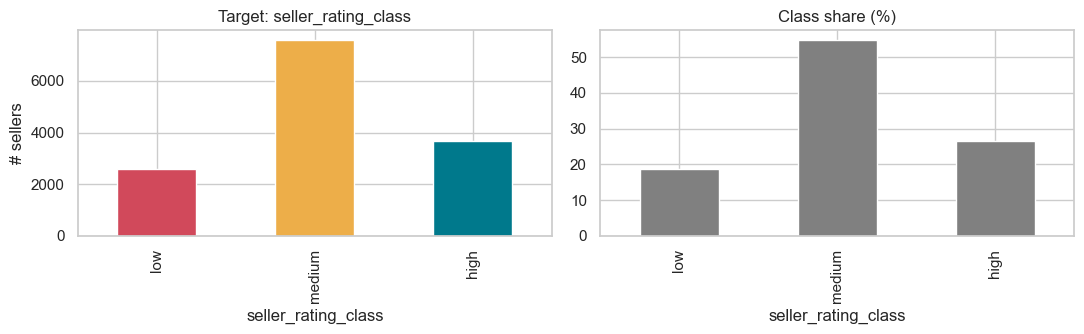

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

order = ['low', 'medium', 'high']

df_raw.seller_rating_class.value_counts().reindex(order).plot.bar(ax=ax[0], color=['#d1495b', '#edae49', '#00798c'])

ax[0].set_title('Target: seller_rating_class')

ax[0].set_ylabel('# sellers')

(df_raw.seller_rating_class.value_counts(normalize=True).reindex(order) * 100).round(1).plot.bar(ax=ax[1], color='grey')

ax[1].set_title('Class share (%)')

plt.tight_layout()

plt.show()


In [26]:
print(df_raw.seller_rating_class.value_counts(normalize=True).round(3))


seller_rating_class
medium    0.547
high      0.266
low       0.186
Name: proportion, dtype: float64


**The target is imbalanced:** medium 54.7%, high 26.6%, low 18.6%. A classifier that always predicts *medium* already reaches 54.7% accuracy, so accuracy alone is misleading. For model selection we use **macro-F1**, which weights the three classes equally.

#### Working through this investigation: Inspect numeric distributions visually

We draw one histogram for each numeric column. A histogram divides the observed range into intervals called **bins** and counts how many sellers fall into each interval. Tall bars indicate common values, and a long tail suggests asymmetry or occasional extremes.

When reading the figure, ask whether the variable looks symmetric, skewed, almost constant, or separated into several peaks. We are not using a histogram to prove a variable is normally distributed. We use it to notice patterns that a single mean or median would conceal.

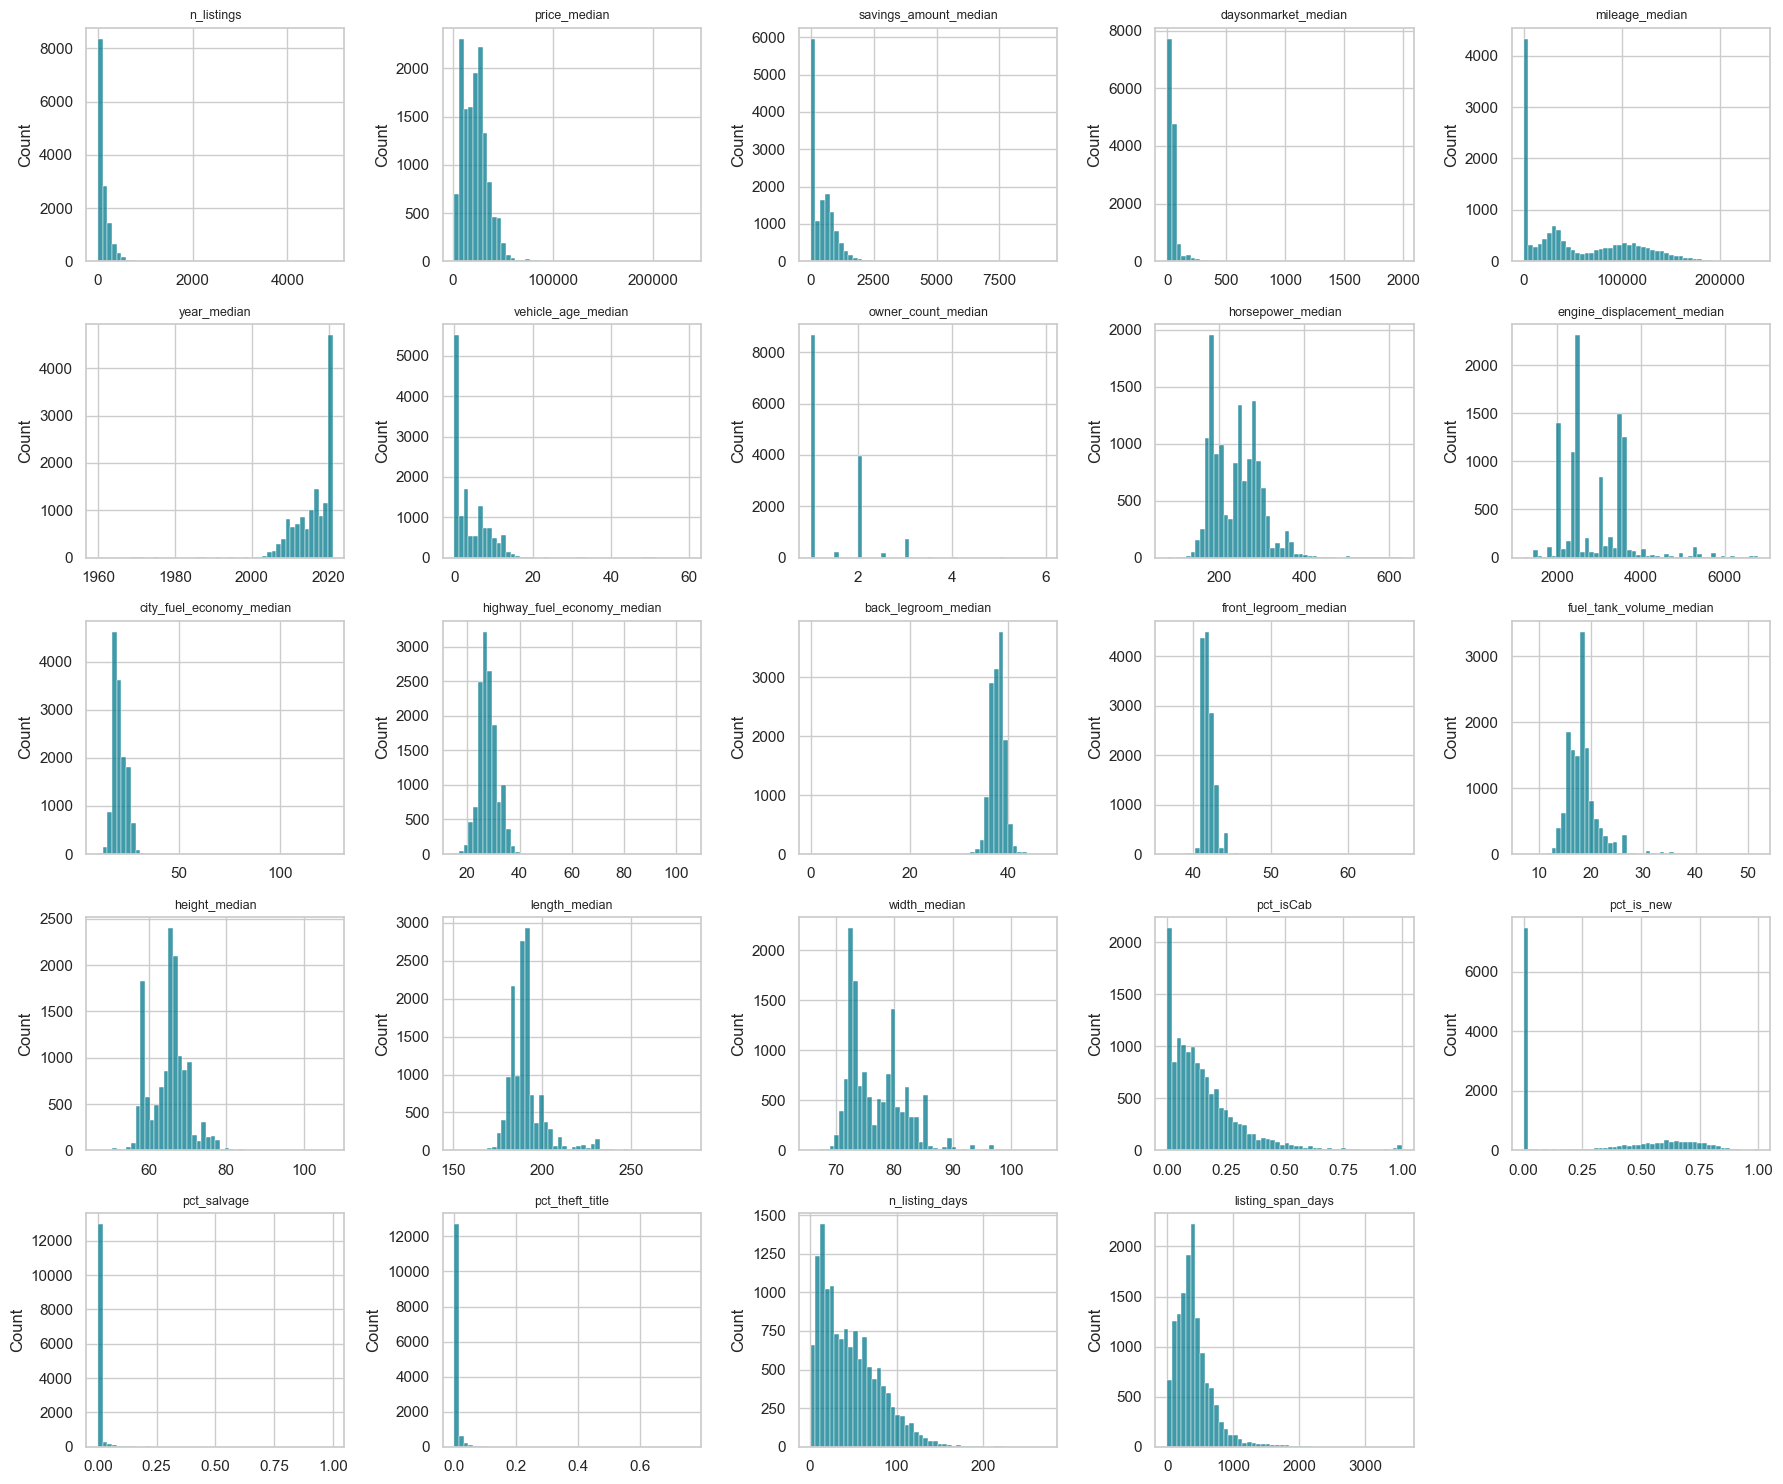

In [27]:
fig, axes = plt.subplots(5, 5, figsize=(18, 15))

for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df_raw[c].dropna(), bins=50, ax=ax, color='#00798c')
    ax.set_title(c, fontsize=9)
    ax.set_xlabel('')

for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')


plt.tight_layout()

plt.show()


The histograms confirm the skewness and the bimodality described above. The vehicle-dimension variables (height, length, width) show peaks that correspond to the dominant body types (sedan vs SUV vs pickup).

#### Working through this investigation: Read the categorical distributions

A bar chart is more suitable for categories than a histogram. Each bar represents the number of sellers associated with one category. We include missing categories as a visible label so that missingness does not silently disappear from our review.

A dominant category can make another category rare enough to be unstable in a later model. This is why we examine frequencies before deciding whether to combine rare categories. We must keep the original meaning of each feature when making such decisions.

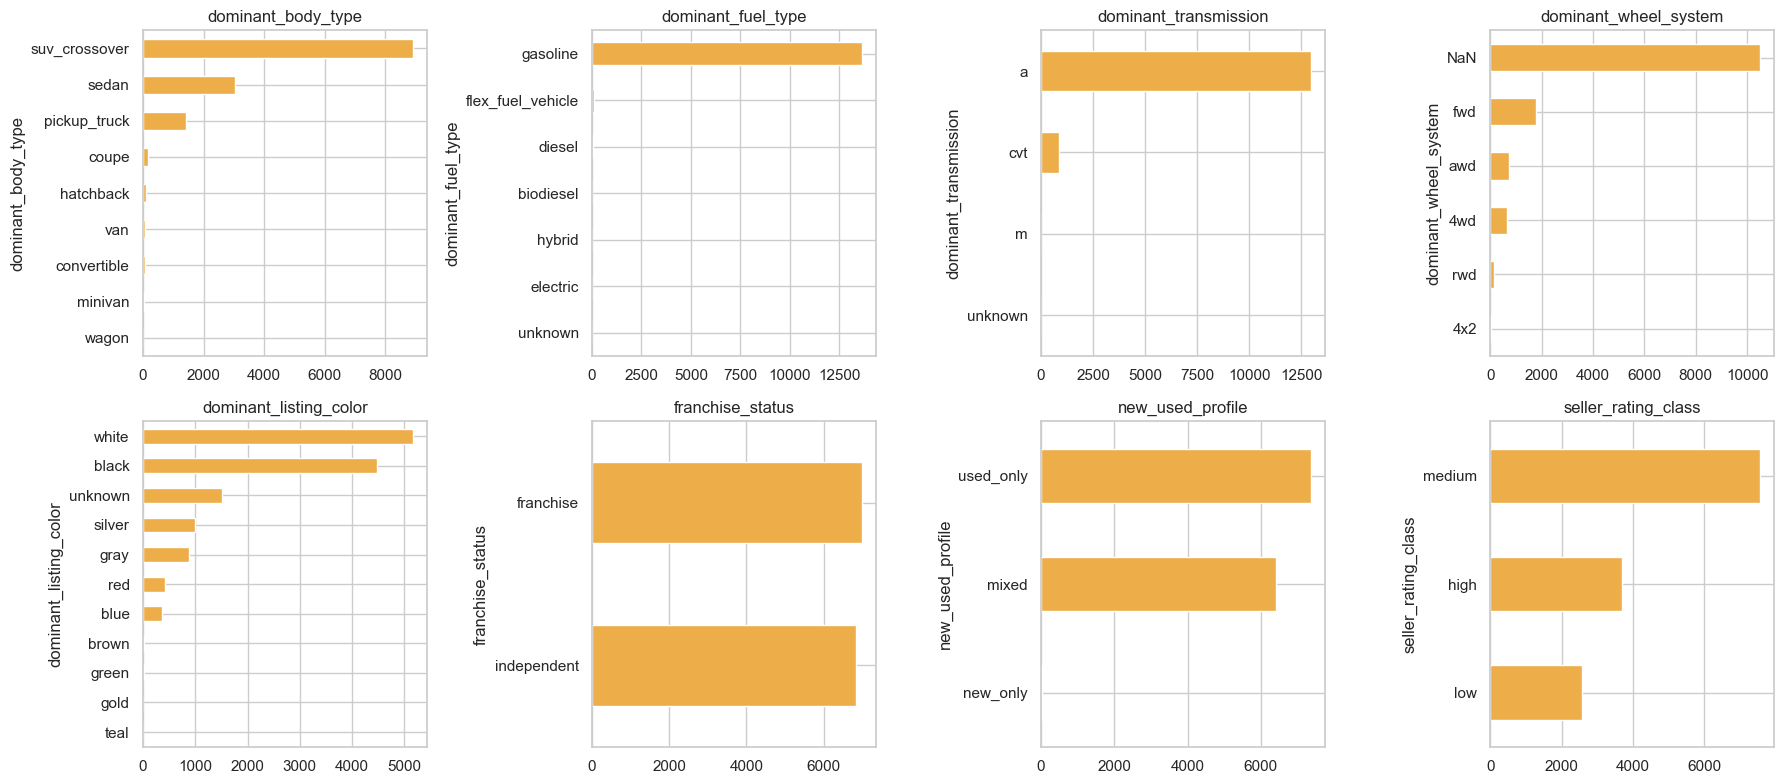

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, c in zip(axes.ravel(), cat_cols):
    vc = df_raw[c].fillna('NaN').value_counts()
    vc.plot.barh(ax=ax, color='#edae49')
    ax.set_title(c)
    ax.invert_yaxis()

plt.tight_layout()

plt.show()


**Categorical variables.** They are highly concentrated: 64% of sellers are mainly SUV/crossover sellers, 98.7% mainly gasoline, 94% mainly automatic. Categories with fewer than 1% of the records (e.g. wagon = 7, teal = 1) cannot support reliable statistics, so they are grouped into `other` during preparation. `dominant_listing_color` has an explicit `unknown` level (11%), which we keep as its own category because it is informative (it is not missing at random, it is a listing practice).

### Relation with the target

#### Working through this investigation: Compare features across rating groups

This is our first direct investigation of how seller attributes differ by rating. A **boxplot** summarizes the middle portion of a distribution using quartiles and a median line. The boxes are grouped by rating so that we can compare typical sellers across classes. We hide extreme points in the plot for readability, but we have not deleted them from the data.

We also compute group medians and conditional percentages. The cross-tabulations answer questions such as, “Among franchise sellers, what percentage received each rating?” Read the normalization direction carefully: row percentages describe the composition **within each group**, not the share of all sellers. Differences are associations, not evidence that one attribute causes the rating.

In [29]:
key = ['n_listings', 'price_median', 'daysonmarket_median', 'mileage_median', 'pct_is_new', 'savings_amount_median', 'n_listing_days', 'listing_span_days']


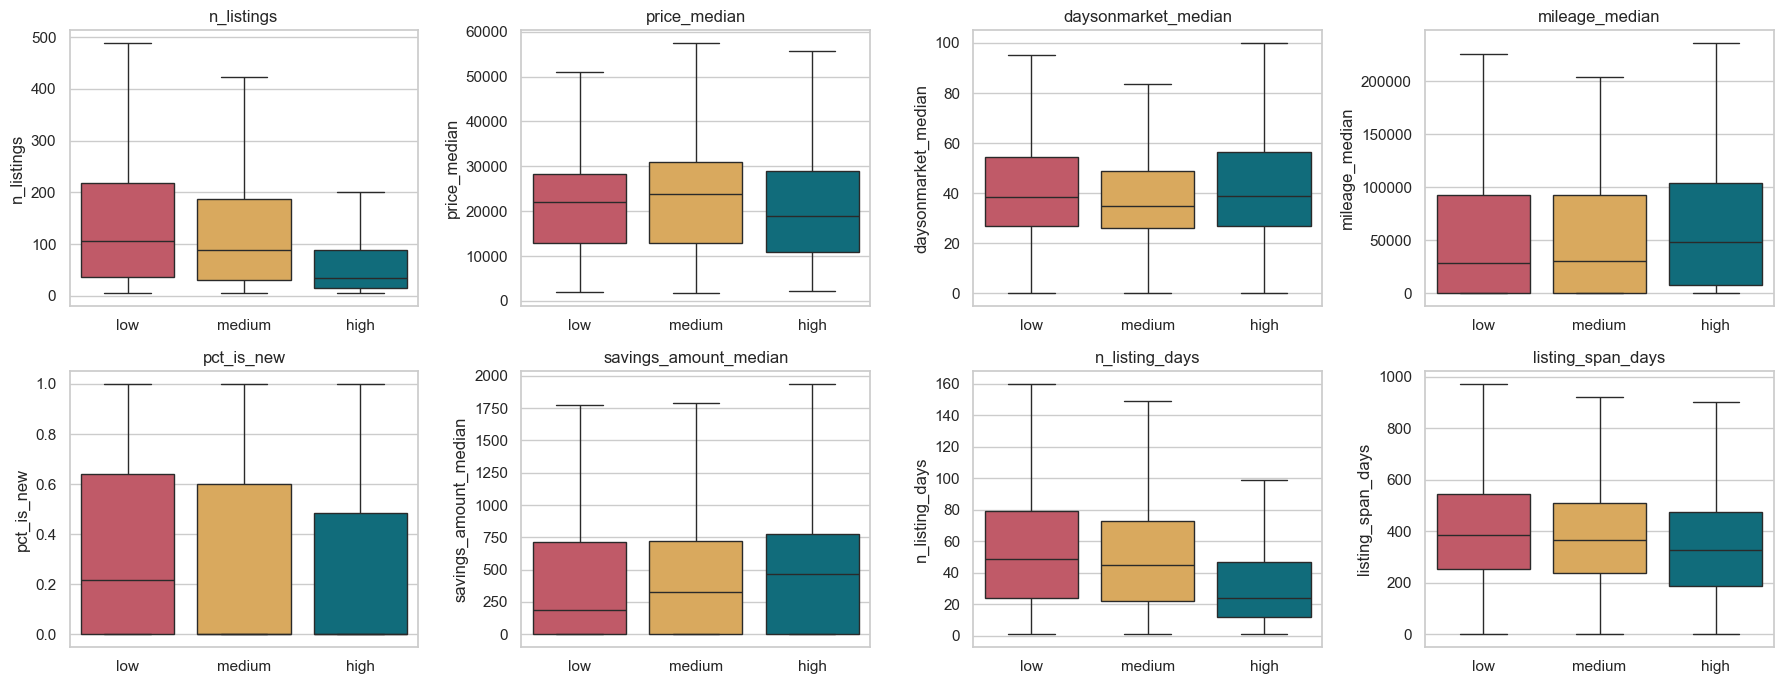

In [30]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))

for ax, c in zip(axes.ravel(), key):
    sns.boxplot(data=df_raw, x='seller_rating_class', y=c, order=order, ax=ax, showfliers=False, palette=['#d1495b', '#edae49', '#00798c'])
    ax.set_title(c)
    ax.set_xlabel('')

plt.tight_layout()

plt.show()


In [31]:
display(df_raw.groupby('seller_rating_class')[key].median().reindex(order).round(2))


,n_listings,price_median,daysonmarket_median,mileage_median,pct_is_new,savings_amount_median,n_listing_days,listing_span_days
seller_rating_class,,,,,,,,
low,107.0,22124.0,38.5,29038.0,0.22,191.5,49.0,384.0
medium,88.0,23840.5,35.0,30845.0,0.00,327.0,45.0,367.0
high,34.0,18998.0,39.0,48603.0,0.00,465.0,24.0,329.0


In [32]:
for c in ['franchise_status', 'new_used_profile']:
    display((pd.crosstab(df_raw[c], df_raw.seller_rating_class, normalize='index')[order] * 100).round(1))


seller_rating_class,low,medium,high
franchise_status,,,
franchise,20.9,58.5,20.6
independent,16.3,50.9,32.8


seller_rating_class,low,medium,high
new_used_profile,,,
mixed,20.9,58.5,20.6
new_only,29.0,38.7,32.3
used_only,16.6,51.5,31.8


**Key insight for the whole project:** the variable most related to the rating is **seller size**. *High*-rated sellers are much smaller (median 34 listings, versus 88 for medium and 107 for low), are active on fewer days, sell older and cheaper cars (higher mileage) and give larger advertised savings. *Low*-rated sellers are the largest ones and more often franchise / mixed new-used dealers. Independent sellers are rated high 32.8% of the time versus 20.6% for franchise dealers. The boxplots, however, overlap heavily between classes, which anticipates that classification will be hard.

### Quality-control vocabulary

- **Missing value:** an entry not available in the table, represented by `NaN` for many numeric pandas columns.
- **Invalid value:** a recorded value that contradicts the attribute's plausible domain, such as an impossible vehicle measurement.
- **Outlier:** a value far from most observations according to a specified rule. It might be valid.
- **Imputation:** filling a missing entry using an explicit procedure, such as a median.
- **Data leakage:** letting information from validation or test observations influence transformations or choices that should be fitted on training data only.

We will not treat all five problems as interchangeable. Each requires a different decision.

## 1.3 Assessing data quality
### Errors and semantic inconsistencies

#### Working through this investigation: Check whether recorded values are plausible

Real datasets can contain invalid values, inconsistent definitions, and records that are unusual but entirely legitimate. We create explicit checks based on the meaning of each field: impossible vehicle dimensions, surprising mileage, and combinations of seller attributes that may contradict one another.

Each expression such as `(df_raw.back_legroom_median < 25).sum()` creates a Boolean condition for every seller and counts how many conditions are true. A count tells us where to investigate; it does not automatically authorize deleting rows. We will distinguish obvious recording errors from business cases that simply look uncommon.

In [33]:
checks = {'year_median < 1990': (df_raw.year_median < 1990).sum(), 

'vehicle_age_median > 30': (df_raw.vehicle_age_median > 30).sum(), 

'back_legroom_median < 25 (impossible)': (df_raw.back_legroom_median < 25).sum(), 

'front_legroom_median > 50 (implausible)': (df_raw.front_legroom_median > 50).sum(), 

'city_fuel_economy > 60 (electric MPGe)': (df_raw.city_fuel_economy_median > 60).sum(), 

'mileage_median == 0': (df_raw.mileage_median == 0).sum(), 

'daysonmarket_median > 365': (df_raw.daysonmarket_median > 365).sum(), 

'n_listing_days > listing_span_days+1 (inconsistent)': (df_raw.n_listing_days > df_raw.listing_span_days + 1).sum(), 

'n_listing_days > n_listings (inconsistent)': (df_raw.n_listing_days > df_raw.n_listings).sum(), 

'pct_is_new==1 but profile != new_only': ((df_raw.pct_is_new == 1) & (df_raw.new_used_profile != 'new_only')).sum(), 

'new_only but mileage_median > 1000': ((df_raw.new_used_profile == 'new_only') & (df_raw.mileage_median > 1000)).sum(), 

'year_median + vehicle_age_median outside [2015,2022]': (~(df_raw.year_median + df_raw.vehicle_age_median).between(2015, 2022)).sum()}

pd.Series(checks, name='# records')


year_median < 1990                                       32
vehicle_age_median > 30                                  32
back_legroom_median < 25 (impossible)                     8
front_legroom_median > 50 (implausible)                   2
city_fuel_economy > 60 (electric MPGe)                   10
mileage_median == 0                                     621
daysonmarket_median > 365                                65
n_listing_days > listing_span_days+1 (inconsistent)       0
n_listing_days > n_listings (inconsistent)                0
pct_is_new==1 but profile != new_only                     0
new_only but mileage_median > 1000                        1
year_median + vehicle_age_median outside [2015,2022]     34
Name: # records, dtype: int64

- **Clear errors:** 8 sellers have rear legroom < 25 in (one is 0) and 2 have front legroom > 50 in (max 67). These are physically impossible for road cars → set to NaN and imputed.
- **Plausible extremes (kept):** 32 sellers with median model year < 1990 / age > 30 are classic-car dealers. 10 sellers with city fuel economy > 60 are electric-vehicle sellers (8 of them have `dominant_fuel_type = electric`, so the values are MPGe). 621 sellers with median mileage 0 are new-car dealers.
- **Consistency checks passed:** no seller has more listing days than listings or than its listing span; `pct_is_new = 1` always coincides with `new_used_profile = new_only`; `year_median + vehicle_age_median` is consistent with the 2015-2022 observation window for all but 34 (classic-car) sellers.

### Missing values

#### Working through this investigation: Investigate why entries are missing

A missing value is not always a random accident. Sometimes it means “not applicable,” and sometimes a collection process failed for a particular type of seller. We compare sellers with and without engine-displacement information to see whether they differ in other variables and rating distributions.

`isna()` produces true/false missingness indicators. `groupby(...)` lets us summarize the corresponding groups. Similar medians do **not** prove that data is missing completely at random, but meaningful differences can tell us that a blanket imputation would be misleading. We also test whether several missing fields tend to occur together.

In [34]:
miss = df_raw.isna()

print('engine_displacement missing vs. present (medians):')


engine_displacement missing vs. present (medians):


In [35]:
display(df_raw.groupby(miss.engine_displacement_median)[['horsepower_median', 'price_median', 'fuel_tank_volume_median', 'pct_is_new']].median())


,horsepower_median,price_median,fuel_tank_volume_median,pct_is_new
engine_displacement_median,,,,
False,244.0,22482.0,18.25,0.0
True,241.0,22238.0,18.00,0.0


In [36]:
print('target distribution when engine_displacement is missing / present:')


target distribution when engine_displacement is missing / present:


In [37]:
display(pd.crosstab(miss.engine_displacement_median, df_raw.seller_rating_class, normalize='index').round(3))


seller_rating_class,high,low,medium
engine_displacement_median,,,
False,0.267,0.183,0.550
True,0.266,0.196,0.538


In [38]:
print('pct_isCab / pct_salvage / pct_theft_title missing together:', (miss.pct_isCab & miss.pct_salvage & miss.pct_theft_title).sum())


pct_isCab / pct_salvage / pct_theft_title missing together: 27


`engine_displacement_median` is missing for 24.5% of sellers, but the sellers with and without it have the same horsepower, price, tank volume and the same target distribution. The values therefore look **missing completely at random**. Since the variable is also highly correlated with horsepower and fuel-tank volume (Spearman 0.81, see 1.5), its information is already covered by other attributes, so we **drop it** instead of imputing a quarter of the column. `dominant_wheel_system` (76% missing) is dropped too. The three `pct_*` title variables are missing for the same 27 sellers, and the remaining variables have < 0.3% missing; these are imputed with the **median of the seller's dominant body type** (medians are robust to skew, and body type strongly determines dimensions and fuel economy).

### Outliers

#### Working through this investigation: Find unusual values using the IQR rule

The **interquartile range**, or IQR, is `Q3 - Q1`, where Q1 is the 25th percentile and Q3 is the 75th percentile. The usual exploratory fences are `Q1 - 1.5 × IQR` and `Q3 + 1.5 × IQR`; using `3 × IQR` creates a more conservative extreme-value check.

A point outside a fence is an **outlier by a particular rule**, not necessarily a wrong observation. The rule can behave poorly for zero-heavy percentages because Q1 and Q3 may both equal zero. We will interpret these counts alongside the variable definitions instead of deleting all flagged sellers.

In [39]:
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    i = q3 - q1
    return ((s < q1 - k * i) | (s > q3 + k * i)).sum()


In [40]:
out = pd.DataFrame({'IQR 1.5 outliers': {c: iqr_outliers(df_raw[c].dropna()) for c in num_cols}, 'IQR 3 (extreme)': {c: iqr_outliers(df_raw[c].dropna(), 3) for c in num_cols}})

out['% extreme'] = (out['IQR 3 (extreme)'] / len(df_raw) * 100).round(2)

out.sort_values('IQR 3 (extreme)', ascending=False)


,IQR 1.5 outliers,IQR 3 (extreme),% extreme
pct_theft_title,2110,2110,15.24
pct_salvage,1242,1242,8.97
daysonmarket_median,1110,703,5.08
length_median,921,510,3.68
pct_isCab,674,196,1.42
listing_span_days,614,195,1.41
fuel_tank_volume_median,806,145,1.05
n_listings,641,125,0.90
price_median,171,61,0.44
savings_amount_median,218,37,0.27


The IQR rule flags many points in `pct_theft_title` and `pct_salvage`, but this happens only because their IQR is 0 (any non-zero value is an "outlier"), so the rule is not meaningful for them. For the skewed activity/price variables the extreme points are real large sellers, not errors. **We do not delete outliers**: instead we (a) log-transform the skewed variables, which shrinks the tails, and (b) use DBSCAN later as a density-based outlier detector. This keeps all 13,843 sellers for classification.

### A worked example of why preprocessing matters

Suppose three sellers have listing counts of 10, 100, and 1,000. A Euclidean distance calculation on raw counts is dominated by the last seller, even if our other variables are on much smaller scales. On the natural-log scale the corresponding `log1p` values are approximately 2.40, 4.62, and 6.91. The high value remains high but has less leverage.

**Scaling** and **log transformation** solve different problems. Scaling changes relative units; a logarithm changes the shape of a distribution. We often need both for distance-based algorithms. We only apply `log1p` when the values are at least zero.

## 1.4 Data preparation and variable transformation
Steps (each justified above): drop the identifier; fix the impossible legroom values; drop `dominant_wheel_system`, `engine_displacement_median`, and the near-duplicates `year_median` (ρ = −0.98 with vehicle age) and `highway_fuel_economy_median` (ρ = 0.94 with city); group rare categories; impute with body-type medians (for the unsupervised tasks on the whole dataset; for the supervised tasks the medians are recomputed on the training set only, see 3.1); apply `log1p` to the 7 skewed variables; and build one derived feature, `activity_ratio` = active listing days / listing span (how continuously the seller is active).

#### Working through this investigation: Prepare the working dataset, step by step

We now convert the inspection findings into explicit preprocessing decisions. The identifier is excluded from the model features because its numerical value is not a meaningful seller characteristic. Implausible legroom values are changed to missing, selected redundant or highly incomplete columns are removed, and rare categories are grouped.

We save `df_nan` before imputation. That untouched-with-respect-to-imputation copy matters later: supervised learning must estimate replacement values from training data, not from the test set. For our exploratory and clustering analysis, we fill remaining numeric gaps using within-body-type medians with a global-median fallback. We then create logarithmic versions of skewed variables and an activity ratio. Every transformation is made on a new `df`, leaving `df_raw` available for comparison.

In [41]:
# We remove the seller ID from the modeling features.
# We mark implausible measurements as missing before imputation.

df = df_raw.copy()

df = df.drop(columns=['sp_id'])

df.loc[df.back_legroom_median < 25, 'back_legroom_median'] = np.nan

df.loc[df.front_legroom_median > 50, 'front_legroom_median'] = np.nan


In [42]:
# We drop highly incomplete and redundant measurements.
# We avoid near-duplicate vehicle age and fuel-economy features.
# We group categories that appear in fewer than 1% of seller records.
# We retain a copy with missing values for training-only imputation later.
# We fill numeric gaps using body-type medians and a global fallback.

df = df.drop(columns=['dominant_wheel_system', 'engine_displacement_median', 'year_median', 'highway_fuel_economy_median'])

for c in ['dominant_body_type', 'dominant_fuel_type', 'dominant_transmission', 'dominant_listing_color']:
    freq = df[c].value_counts(normalize=True)
    df[c] = df[c].where(df[c].map(freq) >= 0.01, 'other')

df_nan = df.copy()

num_keep = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]


In [43]:
# We fill numeric gaps using body-type medians and a global fallback.
# We reduce right skew using the log1p transformation.

for c in num_keep:
    df[c] = df[c].fillna(df.groupby('dominant_body_type')[c].transform('median')).fillna(df[c].median())

log_cols = ['n_listings', 'price_median', 'savings_amount_median', 'daysonmarket_median', 'mileage_median', 'listing_span_days', 'n_listing_days']


In [44]:
# We calculate the share of days with listings during the observed span.

for c in log_cols:
    df['log_' + c] = np.log1p(df[c])

df['activity_ratio'] = df.n_listing_days / (df.listing_span_days + 1)

print(df.shape, '| remaining NaN:', df.isna().sum().sum())


(13843, 36) | remaining NaN: 0


In [45]:
for c in ['dominant_body_type', 'dominant_fuel_type', 'dominant_transmission', 'dominant_listing_color']:
    print(c, df[c].value_counts().to_dict())


dominant_body_type {'suv_crossover': 8920, 'sedan': 3044, 'pickup_truck': 1424, 'other': 288, 'coupe': 167}
dominant_fuel_type {'gasoline': 13658, 'other': 185}
dominant_transmission {'a': 12976, 'cvt': 847, 'other': 20}
dominant_listing_color {'white': 5167, 'black': 4475, 'unknown': 1510, 'silver': 992, 'gray': 875, 'red': 417, 'blue': 372, 'other': 35}


#### Working through this investigation: Compare distributions before and after a log transform

The formula `log1p(x)` means `ln(1 + x)`, where `ln` is the natural logarithm. Adding 1 allows a genuine zero to stay in the data because `ln(1) = 0`. A logarithm compresses very large positive values much more than small values.

We place each original histogram above its transformed version and print the skewness in the chart titles. This helps us decide whether a transformation reduces the dominance of a few exceptionally large sellers. A transformed variable has different units and should not be confused with the original dollar or mileage scale.

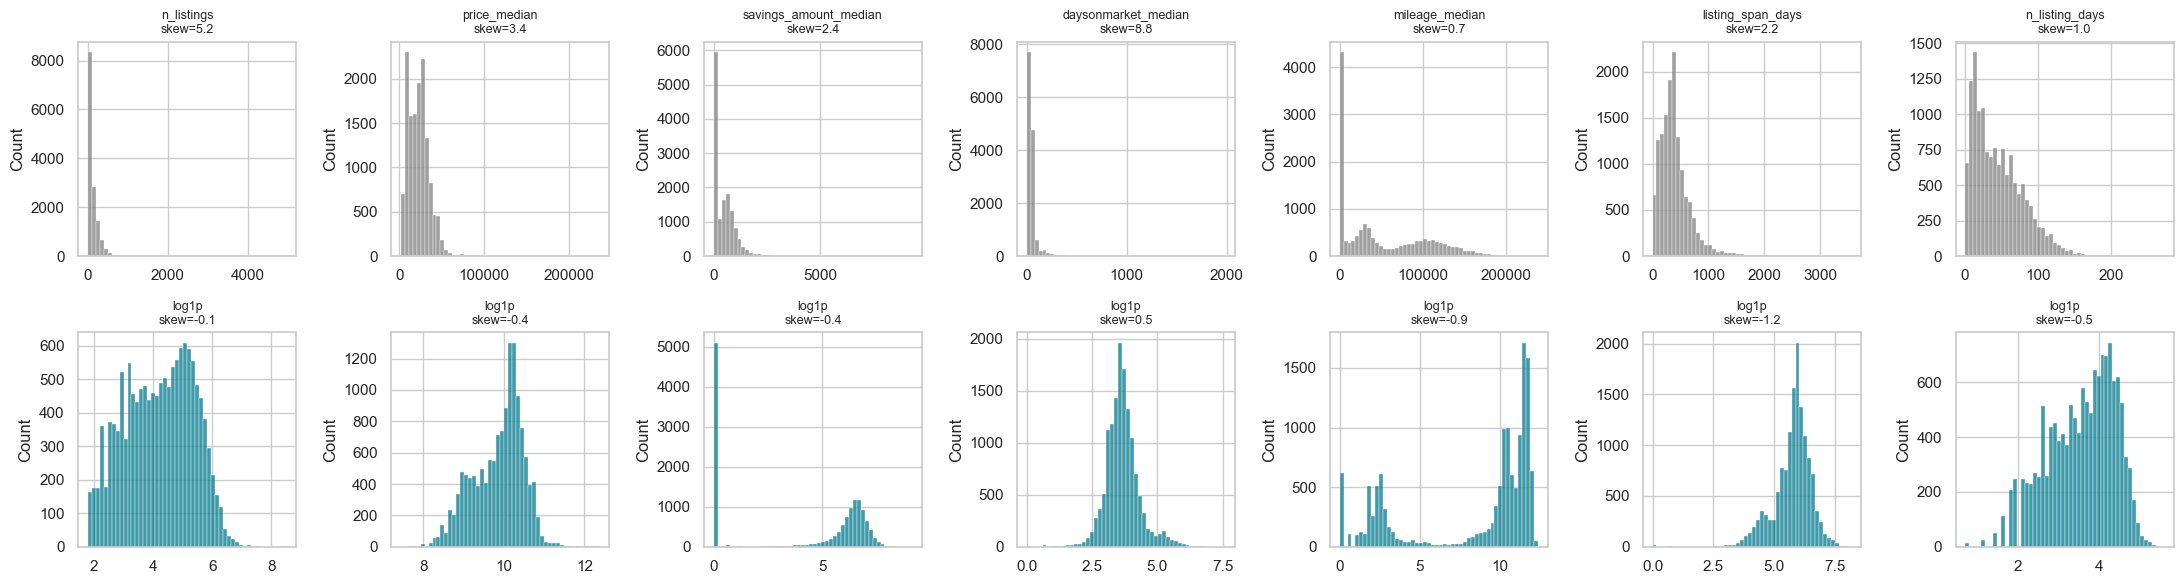

In [46]:
fig, axes = plt.subplots(2, 7, figsize=(22, 6))

for i, c in enumerate(log_cols):
    sns.histplot(df[c], bins=50, ax=axes[0, i], color='grey')
    axes[0, i].set_title(f'{c}\nskew={df[c].skew():.1f}', fontsize=9)
    sns.histplot(df['log_' + c], bins=50, ax=axes[1, i], color='#00798c')
    axes[1, i].set_title(f"log1p\nskew={df['log_' + c].skew():.1f}", fontsize=9)
    axes[0, i].set_xlabel('')
    axes[1, i].set_xlabel('')

plt.tight_layout()

plt.show()


`log1p` brings skewness from 2-9 down to roughly −1…1. The log versions are used for clustering (distance-based), KNN, Gaussian NB and regression. Decision trees are invariant to monotone transformations, so the transformation does not change them.

## 1.5 Pairwise correlations and elimination of variables
Spearman correlation is used because many variables are skewed and the relations are monotone but not linear.

#### Working through this investigation: Identify overlapping measurements with Spearman correlation

**Correlation** describes how two variables move together. Spearman correlation works on the ranks of observations, making it useful when the relationship is broadly monotonic but not necessarily a straight line. Its coefficient, often written `ρ`, ranges from -1 to +1. Positive values mean ranks tend to rise together; negative values mean one rank tends to fall when the other rises.

We calculate a correlation matrix and visualize it as a heatmap. Strong correlations indicate that two features may describe much the same seller characteristic. In a distance-based model, including many near-duplicates can unintentionally give that characteristic extra weight. Correlation by itself does not demonstrate causation.

In [47]:
corr_cols = [c for c in num_cols if c in df.columns] + ['engine_displacement_median', 'year_median', 'highway_fuel_economy_median']

C = df_raw[corr_cols].corr(method='spearman')


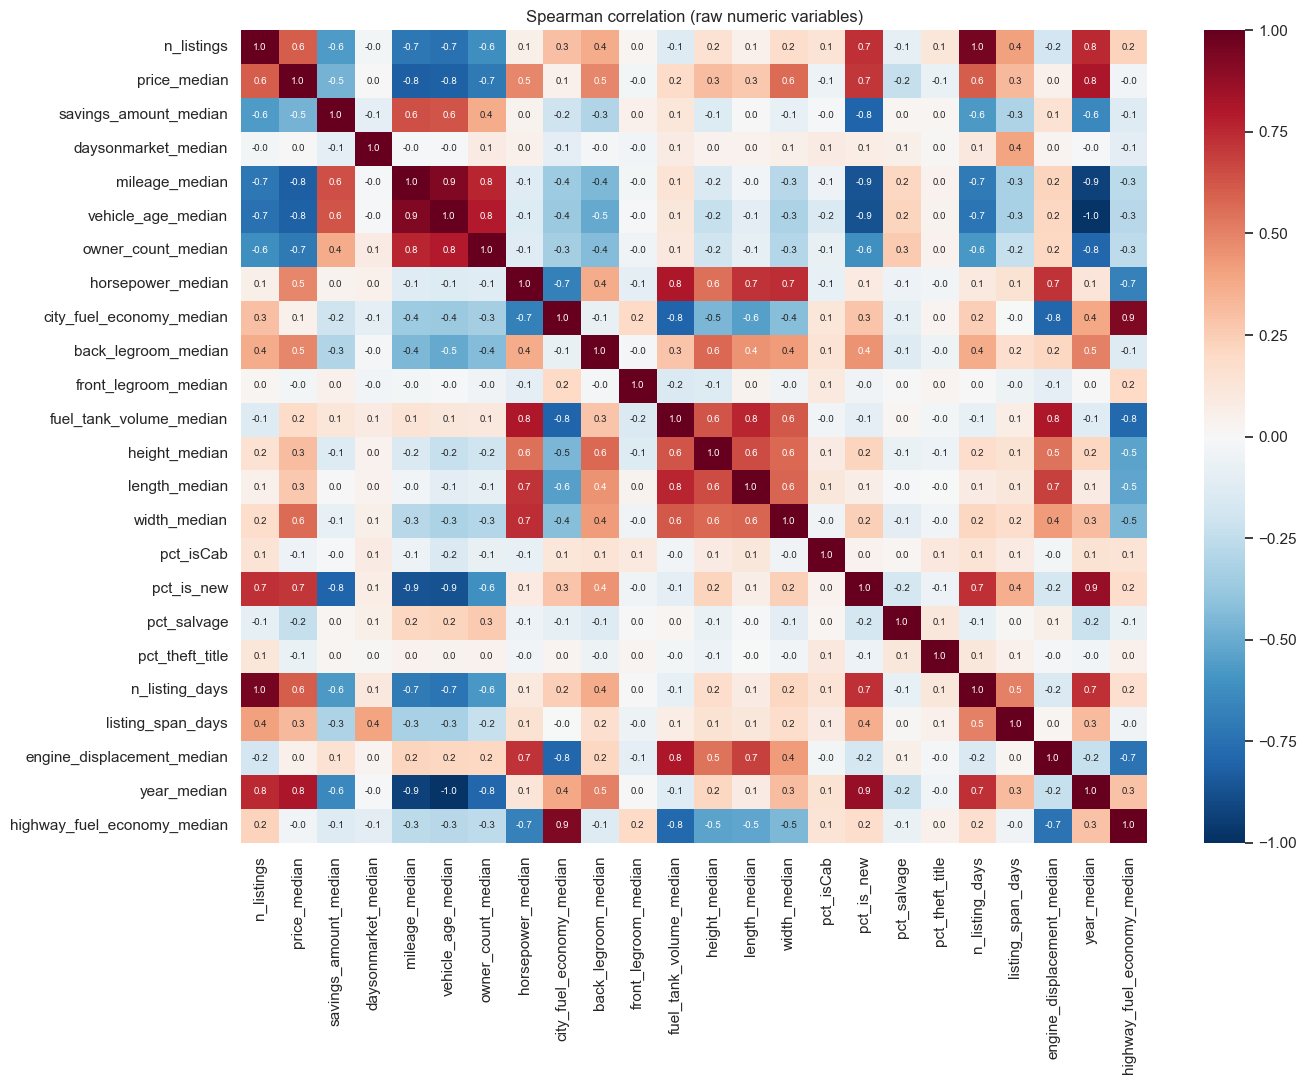

In [48]:
plt.figure(figsize=(14, 11))

sns.heatmap(C, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 7})

plt.title('Spearman correlation (raw numeric variables)')

plt.tight_layout()

plt.show()


In [49]:
up = C.where(np.triu(np.ones(C.shape), 1).astype(bool)).stack()

up[up.abs() > 0.75].sort_values(key=abs, ascending=False).round(3)


vehicle_age_median        year_median                   -0.984
n_listings                n_listing_days                 0.956
city_fuel_economy_median  highway_fuel_economy_median    0.936
mileage_median            year_median                   -0.932
                          vehicle_age_median             0.927
pct_is_new                year_median                    0.873
vehicle_age_median        pct_is_new                    -0.867
mileage_median            pct_is_new                    -0.861
price_median              mileage_median                -0.823
                          year_median                    0.819
                          vehicle_age_median            -0.815
fuel_tank_volume_median   engine_displacement_median     0.810
horsepower_median         fuel_tank_volume_median        0.805
savings_amount_median     pct_is_new                    -0.799
city_fuel_economy_median  fuel_tank_volume_median       -0.798
owner_count_median        year_median                  

**Strongly correlated groups (|ρ| > 0.75):**
1. *Age block:* year ↔ age (−0.98), mileage ↔ age (0.93), `pct_is_new` ↔ mileage (−0.86), owner count ↔ age (0.79). These all describe "new vs used" inventory. We keep `log_mileage`, `vehicle_age` and `pct_is_new` for classification, but only one or two of them for clustering, to avoid over-weighting one concept.
2. *Activity block:* `n_listings` ↔ `n_listing_days` (0.96).
3. *Engine/size block:* displacement ↔ tank (0.81), horsepower ↔ tank (0.81), city fuel economy ↔ tank (−0.80).
4. City ↔ highway fuel economy (0.94).

Eliminated: `year_median`, `highway_fuel_economy_median`, `engine_displacement_median`. Price is negatively related to mileage/age (−0.82), which motivates the regression task in Section 3.

## 1.6 Further findings
*(Analysis contributed by Muawia Nasser, re-checked here on the same data.)* Four extra checks: (a) is `engine_displacement` missing at random across fuel types? (b) how many price outliers are there? (c) how strong is the size-price relation? (d) does the price-mileage relation hold inside each type of seller?

#### Working through this investigation: Run four targeted checks before clustering

We revisit questions raised by the first pass through the data. First we compare engine-displacement missingness by fuel type. Next we measure the characteristics of sellers above the price IQR fence. Then we contrast Pearson and Spearman correlation for seller size and price. Finally we compare the price-mileage relationship for different new/used seller profiles.

The final scatter plot adds context to the correlations: sellers from distinct market segments can show different relationships even when the overall correlation seems simple. This is a good example of why a useful investigation often needs a subgroup analysis, not just a single statistic.

In [50]:
# We compare missing engine displacement across fuel types.

fuel = df_raw.dominant_fuel_type

display(pd.DataFrame({'sellers': fuel.value_counts(), 'missing_displacement_%': (df_raw.engine_displacement_median.isna().groupby(fuel).mean() * 100).round(1)}))


,sellers,missing_displacement_%
dominant_fuel_type,,
biodiesel,16,0.0
diesel,52,30.8
electric,12,50.0
flex_fuel_vehicle,91,17.6
gasoline,13658,24.5
hybrid,13,30.8
unknown,1,100.0


In [51]:
# We check the sellers above the price IQR upper fence.

q1, q3 = df_raw.price_median.quantile([0.25, 0.75])

ub = q3 + 1.5 * (q3 - q1)

out = df_raw.price_median > ub

print(f'price upper whisker = {ub:,.0f}  ->  {out.sum()} outlier sellers (median price {df_raw.price_median[out].median():,.0f}, median listings {df_raw.n_listings[out].median():.0f})')


price upper whisker = 55,978  ->  171 outlier sellers (median price 73,494, median listings 57)


In [52]:
# We compare linear and rank correlation between size and price.

print('n_listings vs price: Pearson', round(df_raw.n_listings.corr(df_raw.price_median), 3), '| Spearman', round(df_raw.n_listings.corr(df_raw.price_median, method='spearman'), 3))


n_listings vs price: Pearson 0.313 | Spearman 0.608


In [53]:
# We inspect price and mileage within each seller profile.

rows = [dict(profile='all sellers', sellers=len(df_raw), spearman=df_raw.price_median.corr(df_raw.mileage_median, method='spearman'))]

for prof, g in df_raw.groupby('new_used_profile'):
    rows.append(dict(profile=prof, sellers=len(g), spearman=g.price_median.corr(g.mileage_median, method='spearman')))

display(pd.DataFrame(rows).round(3))


,profile,sellers,spearman
0,all sellers,13843,-0.823
1,mixed,6428,-0.191
2,new_only,31,0.226
3,used_only,7384,-0.808


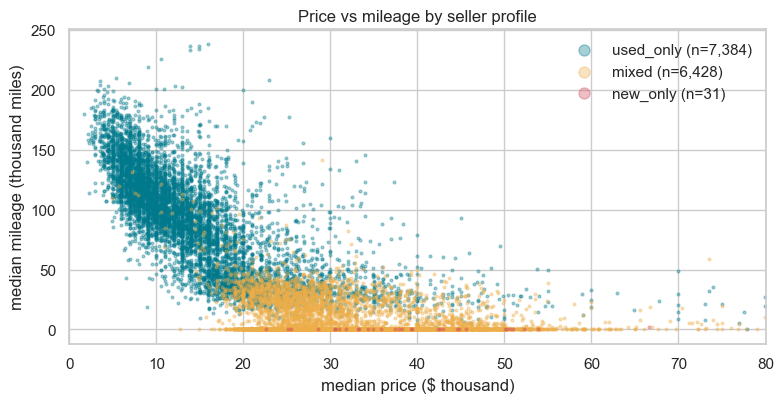

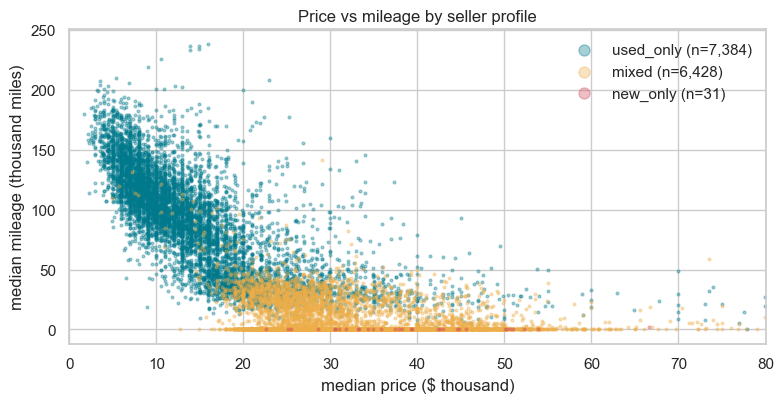

In [54]:
fig, ax = plt.subplots(figsize=(8, 4.2))

for prof, col in [('used_only', '#00798c'), ('mixed', '#edae49'), ('new_only', '#d1495b')]:
    g = df_raw[df_raw.new_used_profile == prof]
    ax.scatter(g.price_median / 1000, g.mileage_median / 1000, s=4, alpha=0.35, color=col, label=f'{prof} (n={len(g):,})')

ax.set_xlim(0, 80)

ax.set_xlabel('median price ($ thousand)')

ax.set_ylabel('median mileage (thousand miles)')

ax.set_title('Price vs mileage by seller profile')

ax.legend(markerscale=4, frameon=False)

fig.tight_layout()

fig.savefig('figures/fig_profile.png', dpi=200, bbox_inches='tight')

display(fig)


In [55]:
plt.close(fig)


**Findings.**
- (a) Displacement is missing for 24.5% of gasoline sellers but for **50% of electric** sellers: for electric cars the attribute is *not applicable* (no combustion engine). Since 98.7% of sellers are gasoline, the overall pattern is still close to random, which supports dropping the column (1.3).
- (b) 171 sellers lie above the upper whisker (\$55,978): they are real luxury dealers, not errors, so they are kept and handled with the log transform.
- (c) Pearson 0.31 vs Spearman 0.61: larger sellers do list pricier cars, but the relation is monotone and non-linear (driven by a few huge sellers), which is why Spearman is used throughout.
- (d) The strong overall relation (ρ = −0.82) hides very different behaviour: **−0.81 for used-only sellers but only −0.19 for mixed ones**, whose median mileage is near zero because they mostly list new cars. Most of the overall correlation comes from the *difference between* new-car and used-car sellers, a first sign of the two business models found by clustering. (new_only has only 31 sellers, so its value is not reliable.)

### Checkpoint: what should we understand after Section 1?

We can now explain what one row represents, identify numeric and categorical columns, recognize skewness and missingness, distinguish a genuine outlier from an error, and justify why some features were excluded or transformed. We have also seen an early relationship between seller size and rating, but we must avoid interpreting it causally.

**Test yourself:** Why do we preserve `df_raw`? Why might median imputation be safer than mean imputation for a right-skewed feature? Why does a highly correlated pair matter in a distance-based model?

### Clustering: the mental model

Imagine placing each seller on a map where one axis is price and another is mileage. Nearby dots describe sellers with similar attributes. Clustering algorithms try to group those dots, but they define a group in different ways: K-Means uses distance to a center, DBSCAN searches for density, and hierarchical methods merge similar groups.

In four dimensions there are four attributes per seller, so we cannot draw the full geometry on a normal page. The software can still calculate distances. This is why feature selection and scaling have such a large effect on the final groups.

**Important:** The source notebook contains a main **four-feature k=3 model** and a separate **ten-feature k=4 backup model**. They answer related but not identical questions. We will preserve both and keep their results distinct.

# 2. Clustering
**Main model (report Section 2):** 4 attributes (listings, price, mileage, share of new cars), log on listings and price, RobustScaler, K-Means k=3 (Model B, designed by Muawia). Sections 2.1-2.5.

**Backup model (report Table 4):** 10 log-transformed, standardized attributes, K-Means k=4. Section 2.6.

## 2.1 Attribute selection and preprocessing
The cells of 2.1-2.5 run in their own namespace: the variables of Section 1 (`df`, scalers, …) are restored at the end of 2.5, so the rest of the notebook is unaffected. Figures are saved as `figures/clu_*.png`.

#### Working through this investigation: Keep the main clustering experiment separate

The original notebook deliberately keeps the main four-feature clustering experiment in a temporary namespace, then restores the earlier working variables before the ten-feature backup experiment. We preserve that arrangement because names such as `df`, `F`, and `sil` are reused for different purposes in the two analyses.

This notebook should be run from top to bottom in a fresh kernel. Running sections out of order can mix results from different feature spaces. We will point out these dependencies instead of silently rewriting the project into a different analysis.

In [56]:
# We save the working variables before the separate clustering experiment.

_g_before = {k: v for k, v in globals().items() if not k.startswith('_')}

_rc_before = plt.rcParams.copy()


#### Working through this investigation: Define the four-feature clustering experiment

**Clustering** is unsupervised learning: we look for similar sellers without telling the algorithm their rating. Here the four selected attributes are inventory size, median price, median mileage, and proportion of new cars. We replace missing values using a simple median rule, build alternative transformed feature spaces, and scale them with **RobustScaler**.

Robust scaling uses the median and IQR, broadly turning a value into `(value - median) / IQR`. This makes features with very different numerical magnitudes more comparable while reducing sensitivity to extreme observations. Model A uses raw features; Model B log-transforms listings and price; Model C also log-transforms mileage. We use these alternatives to examine the effect of representation.

In [57]:
# We prepare a separate four-feature clustering workspace.

import sys, warnings

import numpy as np, pandas as pd, matplotlib

import matplotlib.pyplot as plt

from sklearn.preprocessing import RobustScaler


In [58]:
from sklearn.cluster import KMeans, BisectingKMeans, DBSCAN, OPTICS, HDBSCAN, AgglomerativeClustering

from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score, davies_bouldin_score

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster


In [59]:
warnings.filterwarnings('ignore')


In [60]:
csv, FIG = (str(DATA_PATH), 'figures')

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


In [61]:
COL = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3']

df = pd.read_csv(csv)

F = ['n_listings', 'price_median', 'mileage_median', 'pct_is_new']

X0 = df[F].fillna(df[F].median())


In [62]:
def sil(X, l, n=3000):
    return silhouette_score(X, l, sample_size=n, random_state=42)


In [63]:
def prep(logcols):
    Z = X0.copy()
    for c in logcols:
        Z[c] = np.log1p(Z[c])
    return RobustScaler().fit_transform(Z)


In [64]:
XA = prep([])

XB = prep(['n_listings', 'price_median'])

XC = prep(['n_listings', 'price_median', 'mileage_median'])

print('skew raw', X0.skew().round(3).to_dict())


skew raw {'n_listings': 5.247, 'price_median': 3.446, 'mileage_median': 0.682, 'pct_is_new': 0.546}


In [65]:
print('skew log', np.log1p(X0[F[:3]]).skew().round(3).to_dict())


skew log {'n_listings': -0.13, 'price_median': -0.447, 'mileage_median': -0.905}


### Why days on market is left out

With days on market, K-Means (k=2) only isolates ~609 very slow sellers: an outlier group, not a segment.

#### Working through this investigation: Check whether days on market improves segmentation

We temporarily add a fifth feature, days on market, then fit K-Means with two clusters. **K-Means** repeatedly assigns each seller to the nearest center and updates the centers to reduce within-cluster squared distance.

We compare cluster sizes, their days-on-market summaries, and silhouette. If a candidate variable causes the model to isolate only a small collection of extreme sellers, that may be an outlier partition rather than a useful market segmentation. The question is not merely whether the score changes, but whether the partition answers our business question.

In [66]:
X5 = df[F + ['daysonmarket_median']].fillna(df[F + ['daysonmarket_median']].median())

X5s = RobustScaler().fit_transform(X5)

l5 = KMeans(2, random_state=42, n_init=10).fit_predict(X5s)

print('5F k2 sizes', np.bincount(l5), 'sil', round(sil(X5s, l5), 3))


5F k2 sizes [  609 13234] sil 0.747


In [67]:
print(df.assign(c=l5).groupby('c')[['daysonmarket_median']].agg(['median', 'min']))


  daysonmarket_median       
               median    min
c                           
0               203.0  144.0
1                35.0    0.0


### Log transform: Models A, B, C

Same 4 features, k=3. A = raw, B = log listings + price, C = also log mileage. Silhouettes of different spaces are not comparable; we compare what the clusters are. **We use Model B.**

#### Working through this investigation: Compare transformations fairly

We fit three separate K-Means models using three representations of the same four attributes. We record how many sellers belong to each cluster and use the **adjusted Rand index** (ARI) to compare the assignments between models. ARI equals 1 for matching partitions and is near 0 for agreement expected by chance.

A crucial distinction: silhouette scores calculated in **different transformed spaces** should not be used as a completely fair head-to-head comparison, because the distances themselves have changed. ARI is useful here because it asks whether the underlying memberships change, regardless of the arbitrary numeric cluster labels.

In [68]:
labs = {}

for name, X in [('A', XA), ('B', XB), ('C', XC)]:
    l = KMeans(3, random_state=42, n_init=10).fit_predict(X)
    labs[name] = l
    print('model', name, 'sil', round(sil(X, l), 3), 'sizes', sorted(np.bincount(l), reverse=True))

print('ARI A-B', round(adjusted_rand_score(labs['A'], labs['B']), 3), 'B-C', round(adjusted_rand_score(labs['B'], labs['C']), 3))


model A sil 0.474 sizes [np.int64(6990), np.int64(5305), np.int64(1548)]
model B sil 0.45 sizes [np.int64(5812), np.int64(4230), np.int64(3801)]
model C sil 0.431 sizes [np.int64(4835), np.int64(4711), np.int64(4297)]
ARI A-B 0.443 B-C 0.678


In [69]:
lA4 = KMeans(4, random_state=42, n_init=10).fit_predict(XA)

print('A k4 sizes', np.bincount(lA4))


A k4 sizes [1519 6965 5329   30]


In [70]:
print(df.assign(c=lA4).groupby('c')[F].median())


   n_listings  price_median  mileage_median  pct_is_new
c                                                      
0       362.0       28300.0           11.00    0.684127
1        27.0       12500.0        96600.50    0.000000
2       137.0       30000.0           90.00    0.560000
3        29.5      173720.0         4900.25    0.000000


### Three measures we need to know

For a point `i`, the silhouette compares `a(i)`, its average distance to points in its own cluster, with `b(i)`, the smallest average distance to an alternative cluster: `s(i) = (b(i) - a(i)) / max(a(i), b(i))`. The score lies between -1 and +1. Values near +1 suggest a well-matched point, near 0 suggest a boundary, and negative values suggest it may fit another group better.

**SSE:** sum of squared distances from observations to their assigned centroids. Smaller is better *for a fixed number of clusters*, but increasing `k` almost always reduces SSE.

**Davies-Bouldin index:** average similarity of each group to its most similar other group, balancing within-group spread and separation. Smaller is preferable.

No one measure answers whether the groups are actually useful to the project.

## 2.2 Centroid-based: K-Means on Model B
### Choice of k

SSE, silhouette (3,000-seller sample) and Davies-Bouldin for k = 1..10.

#### Working through this investigation: Choose a candidate number of clusters

The number `k` tells K-Means how many groups to create. We sweep through candidate values and record three measures. **SSE / inertia** sums squared distances from each seller to its assigned center; it always tends to decrease as `k` grows. **Silhouette** compares each point with its own cluster and the closest alternative cluster; higher is better. **Davies-Bouldin** compares cluster scatter with separation; lower is better.

We inspect all three curves rather than accept a single metric without interpretation. An elbow suggests diminishing improvements in SSE. A higher silhouette may still come from an oversimplified partition. The chosen number of clusters should also produce useful, defensible seller profiles.

In [71]:
rows = []

sse = []


In [72]:
for k in range(1, 11):
    m = KMeans(k, random_state=42, n_init=10).fit(XB)
    sse.append(m.inertia_)
    if k > 1:
        rows.append(dict(k=k, sil=sil(XB, m.labels_), dbi=davies_bouldin_score(XB, m.labels_), sizes=sorted(np.bincount(m.labels_), reverse=True)))

kt = pd.DataFrame(rows)

print(kt.round(3).to_string())


    k    sil    dbi                                                        sizes
0   2  0.523  0.712                                                 [7435, 6408]
1   3  0.450  0.866                                           [5812, 4230, 3801]
2   4  0.374  1.054                                     [5569, 2962, 2900, 2412]
3   5  0.285  1.216                               [3603, 2891, 2794, 2389, 2166]
4   6  0.284  1.217                         [3281, 2698, 2414, 2091, 1929, 1430]
5   7  0.280  1.181                   [3316, 2278, 1831, 1695, 1646, 1601, 1476]
6   8  0.272  1.156             [2698, 2001, 1663, 1622, 1593, 1577, 1457, 1232]
7   9  0.271  1.112        [2523, 1945, 1607, 1558, 1551, 1442, 1416, 1355, 446]
8  10  0.271  1.075  [2528, 1919, 1583, 1521, 1425, 1352, 1162, 1031, 1030, 292]


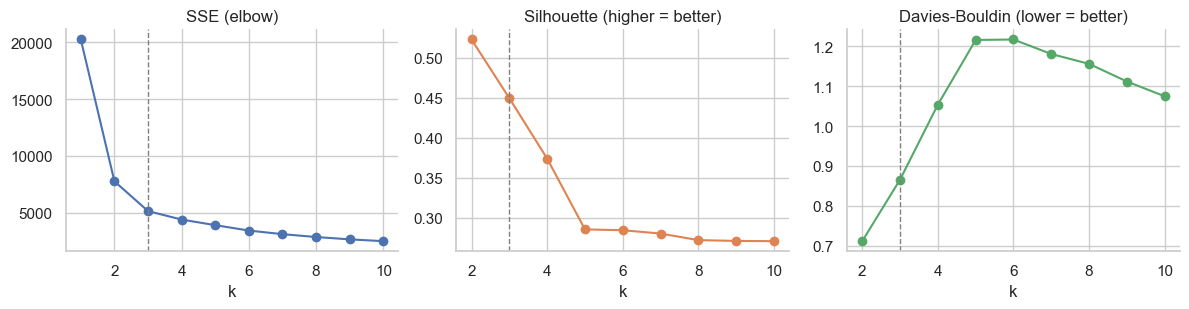

In [73]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))

ax[0].plot(range(1, 11), sse, 'o-', c=COL[0])

ax[0].set(title='SSE (elbow)', xlabel='k')

ax[1].plot(kt.k, kt.sil, 'o-', c=COL[1])

ax[1].set(title='Silhouette (higher = better)', xlabel='k')

ax[2].plot(kt.k, kt.dbi, 'o-', c=COL[2])

ax[2].set(title='Davies-Bouldin (lower = better)', xlabel='k')

for a in ax:
    a.axvline(3, ls='--', c='grey', lw=1)

plt.tight_layout()

plt.savefig(f'{FIG}/clu_kchoice.png', dpi=160)

_plt_show()


In [74]:
km = KMeans(3, random_state=42, n_init=10).fit(XB)

lB = km.labels_


### K-Means k=3: profiles, ratings, stability

Clusters reordered by price: C0 budget used, C1 mid-market used, C2 new-car franchise.

#### Working through this investigation: Explain cluster profiles and test stability

K-Means returns labels such as 0, 1, and 2, but those numbers have no built-in meaning. We reorder the labels by median seller price to make the analysis easier to describe. We then report cluster sizes, medians, franchise share, and the rating distribution **after** the unsupervised clusters have been formed.

We also test whether the groups change if we use a different initialization seed or fit on random subsamples. High ARI between partitions indicates relatively stable memberships. Finally, seller-level silhouette values show whether some groups contain many points that fit another cluster better. Stability is helpful, but stable groups are not necessarily sharply separated or causally meaningful.

In [75]:
med = df.assign(c=lB).groupby('c').price_median.median().sort_values().index

mp = {old: new for new, old in enumerate(med)}

lB = np.array([mp[x] for x in lB])

g = df.assign(c=lB)


In [76]:
prof = g.groupby('c').agg(size=('sp_id', 'size'), listings=('n_listings', 'median'), price=('price_median', 'median'), mileage=('mileage_median', 'median'), new=('pct_is_new', 'median'), dom=('daysonmarket_median', 'median'), franchise=('franchise_status', lambda s: (s == 'franchise').mean()))

rt = pd.crosstab(g.c, g.seller_rating_class, normalize='index')[['low', 'medium', 'high']]

print(prof.round(2).to_string())


   size  listings    price   mileage   new   dom  franchise
c                                                          
0  4230      20.0   9085.0  115446.0  0.00  37.5       0.00
1  3801      51.0  20747.0   39897.0  0.00  34.0       0.31
2  5812     178.0  29895.0      14.0  0.63  37.0       1.00


In [77]:
print(rt.round(3))


seller_rating_class    low  medium   high
c                                        
0                    0.167   0.496  0.337
1                    0.162   0.542  0.296
2                    0.216   0.588  0.196


In [78]:
print('B k3 sil', round(sil(XB, lB), 3), 'dbi', round(davies_bouldin_score(XB, lB), 3))


B k3 sil 0.45 dbi 0.866


In [79]:
print('seed ARI', round(adjusted_rand_score(lB, KMeans(3, random_state=7, n_init=10).fit_predict(XB)), 3))


seed ARI 1.0


In [80]:
rng = np.random.RandomState(0)

ar = []


In [81]:
for s in range(10):
    idx = rng.choice(len(XB), int(0.8 * len(XB)), replace=False)
    ar.append(adjusted_rand_score(lB, KMeans(3, random_state=s, n_init=10).fit(XB[idx]).predict(XB)))

print('subsample ARI mean', round(np.mean(ar), 3), 'min', round(np.min(ar), 3))


subsample ARI mean 0.996 min 0.987


In [82]:
sub = np.random.RandomState(42).choice(len(XB), 3000, replace=False)

ss = silhouette_samples(XB[sub], lB[sub])

print(pd.DataFrame({'c': lB[sub], 's': ss}).groupby('c').s.agg(['mean', lambda x: (x < 0).mean()]).round(3))


    mean  <lambda_0>
c                   
0  0.454       0.000
1  0.310       0.048
2  0.535       0.000


In [83]:
lB2 = KMeans(2, random_state=42, n_init=10).fit_predict(XB)

print('k2 sizes', np.bincount(lB2))


k2 sizes [6408 7435]


In [84]:
print(df.assign(c=lB2).groupby('c')[F].median())


   n_listings  price_median  mileage_median  pct_is_new
c                                                      
0        24.0       11895.0        100587.0    0.000000
1       156.0       28954.5            65.0    0.569132


In [85]:
print('k2 vs k3 crosstab')


k2 vs k3 crosstab


In [86]:
print(pd.crosstab(lB2, lB))


col_0     0     1     2
row_0                  
0      4230  2178     0
1         0  1623  5812


### Bisecting K-Means

#### Working through this investigation: Compare ordinary and bisecting K-Means

**Bisecting K-Means** starts with a broad cluster and splits groups into smaller pieces, instead of fitting all `k` centers simultaneously. We fit the bisecting version on the same transformed seller data and compare its assignments to ordinary K-Means using ARI.

This is a useful robustness check. Agreement supports the idea that the overall grouping is not tied to one initialization strategy. Disagreement invites us to inspect which seller types change groups rather than pronounce one algorithm automatically correct.

In [87]:
bk = BisectingKMeans(3, random_state=42, n_init=10, bisecting_strategy='largest_cluster').fit_predict(XB)

print('bisecting k3 ARI vs KM', round(adjusted_rand_score(lB, bk), 3), 'sil', round(sil(XB, bk), 3), 'sizes', np.bincount(bk))


bisecting k3 ARI vs KM 0.623 sil 0.373 sizes [5231 2193 6419]


### Cluster plots

#### Working through this investigation: Visualize the business meaning of each cluster

We plot price against mileage and inventory size against share of new cars. Each dot represents a seller, and color indicates the assigned cluster. Scatter plots reveal whether groups occupy distinct regions or overlap continuously.

Notice the logarithmic axis for variables spanning large ranges. A log axis changes the spacing of values on the plot; it does not change the stored records. The charts are most useful when read alongside cluster medians, because a two-dimensional picture cannot show all four clustering features simultaneously.

In [88]:
names = ['C0 budget used', 'C1 mid-market used', 'C2 new-car franchise']


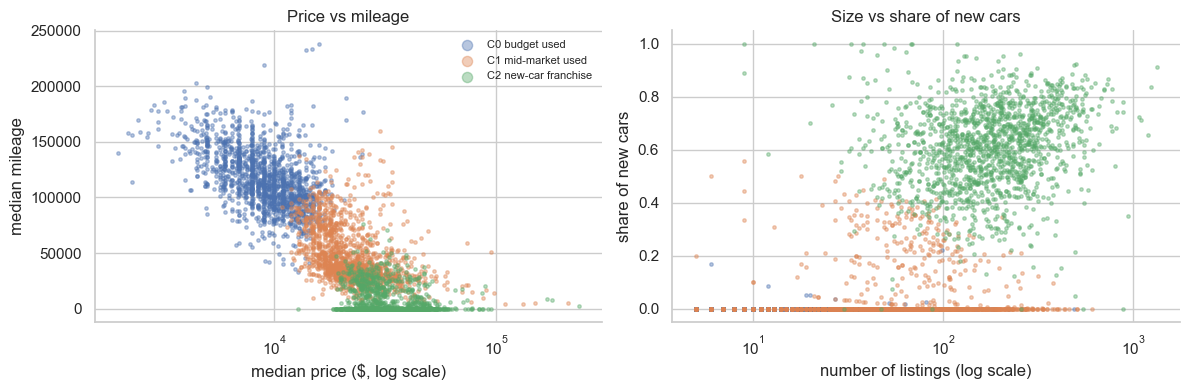

In [89]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for c in range(3):
    s = g[g.c == c].sample(min(1500, (g.c == c).sum()), random_state=1)
    ax[0].scatter(s.price_median, s.mileage_median, s=6, alpha=0.4, c=COL[c], label=names[c])
    ax[1].scatter(s.n_listings, s.pct_is_new, s=6, alpha=0.4, c=COL[c], label=names[c])

ax[0].set(xscale='log', xlabel='median price ($, log scale)', ylabel='median mileage', title='Price vs mileage')

ax[1].set(xscale='log', xlabel='number of listings (log scale)', ylabel='share of new cars', title='Size vs share of new cars')

ax[0].legend(markerscale=3, fontsize=8, frameon=False)

plt.tight_layout()

plt.savefig(f'{FIG}/clu_profiles.png', dpi=160)

_plt_show()


### Ratings inside each cluster

#### Working through this investigation: Compare rating compositions without using the rating to cluster

We make a 100% stacked bar chart for the rating distribution inside each cluster. Each row adds up to 100%, allowing us to compare the **composition** of the groups despite their different sizes.

The rating is an **external descriptive variable** here, not an input to clustering. If clusters have different rating mixes, that makes them potentially useful for analysis, but it does not mean that a cluster assignment explains what causes higher ratings.

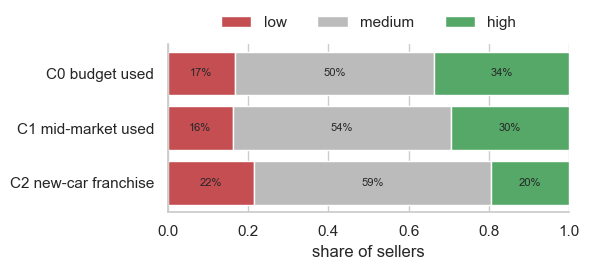

In [90]:
fig, ax = plt.subplots(figsize=(6, 2.8))

left = np.zeros(3)

for j, (cl, col) in enumerate(zip(['low', 'medium', 'high'], [COL[3], '#BBBBBB', COL[2]])):
    ax.barh(names, rt[cl], left=left, color=col, label=cl)
    for i, v in enumerate(rt[cl]):
        ax.text(left[i] + v / 2, i, f'{v:.0%}', ha='center', va='center', fontsize=8)
    left += rt[cl].values

ax.invert_yaxis()

ax.set_xlim(0, 1)

ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1), frameon=False)

ax.set_xlabel('share of sellers')

plt.tight_layout()

plt.savefig(f'{FIG}/clu_rating.png', dpi=160)

_plt_show()


### Density-based clustering in one example

Suppose five sellers lie tightly together but a sixth is far away. With a small `eps`, DBSCAN may classify the tight group as a cluster and the sixth as noise. Increasing `eps` can pull the sixth into the group; increasing `min_samples` makes the core-point requirement stricter.

A **core point** has at least `min_samples` points in its `eps` neighborhood, usually counting itself. A **border point** is reachable from a core point but may not be core. A **noise point** is not assigned to a dense region under the chosen parameters. Noise is not the same as an incorrect record.

## 2.3 Density-based: DBSCAN, OPTICS, HDBSCAN
### DBSCAN grid (full data)

eps from the sorted k-distance graph; min_samples 5/10/20.

#### Working through this investigation: Explore DBSCAN parameters and density structure

**DBSCAN** searches for dense regions of points rather than assigning every seller to a center. The two main parameters are `eps` (the neighborhood radius) and `min_samples` (the density threshold for a core point). Sellers outside dense regions may receive the noise label `-1`.

We start with a sorted neighbor-distance plot to see where distances increase noticeably, then test a grid of `eps` and `min_samples`. We record cluster counts, noise percentage, and silhouette where more than one non-noise cluster exists. High silhouette after discarding many sellers is not automatically a better outcome. Coverage matters.

     eps  ms  clusters  noise    sil                     top
0   0.05   5       263   67.1 -0.042    [1757, 254, 171, 89]
1   0.10   5        31   17.1 -0.393    [6277, 4996, 25, 19]
2   0.15   5        20    5.3 -0.491       [13016, 11, 7, 6]
3   0.20   5         4    2.1  0.201        [13540, 5, 5, 5]
4   0.30   5         2    0.5  0.436             [13758, 13]
5   0.40   5         1    0.1    NaN                 [13825]
6   0.50   5         1    0.0    NaN                 [13838]
7   0.05  10        38   92.4  0.192      [185, 164, 91, 65]
8   0.10  10        20   28.6 -0.232    [5243, 4401, 46, 21]
9   0.15  10         3   10.1 -0.349         [12407, 24, 10]
10  0.20  10         1    3.6    NaN                 [13344]
11  0.30  10         1    0.8    NaN                 [13727]
12  0.40  10         2    0.3  0.487             [13794, 11]
13  0.50  10         1    0.1    NaN                 [13834]
14  0.05  20         0  100.0    NaN                      []
15  0.10  20         8  

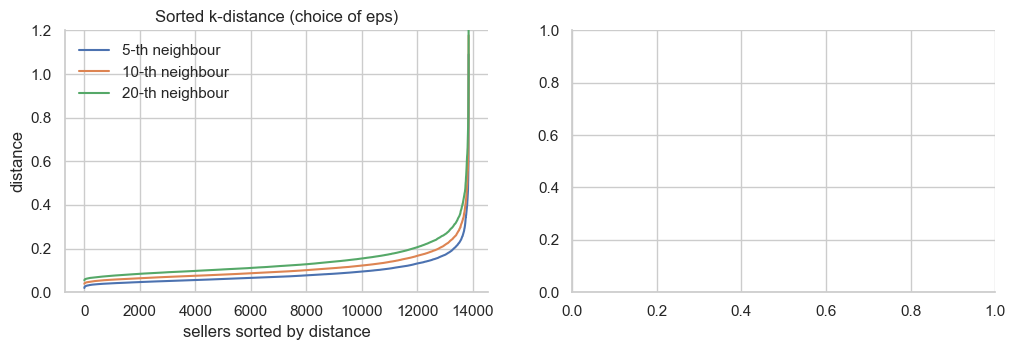

In [91]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))

for i, m in enumerate([5, 10, 20]):
    d, _ = NearestNeighbors(n_neighbors=m).fit(XB).kneighbors(XB)
    ax[0].plot(np.sort(d[:, -1]), c=COL[i], label=f'{m}-th neighbour')

ax[0].set(ylim=(0, 1.2), title='Sorted k-distance (choice of eps)', xlabel='sellers sorted by distance', ylabel='distance')

ax[0].legend(frameon=False)

dres = []

for ms in [5, 10, 20]:
    for eps in [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]:
        l = DBSCAN(eps=eps, min_samples=ms).fit_predict(XB)
        n = len(set(l)) - (-1 in l)
        mk = l != -1
        sz = sorted(np.bincount(l[mk]), reverse=True) if n else []
        s = silhouette_score(XB[mk], l[mk], sample_size=3000, random_state=42) if n > 1 else np.nan
        dres.append(dict(eps=eps, ms=ms, clusters=n, noise=round(100 * (~mk).mean(), 1), sil=s, top=sz[:4]))

dt = pd.DataFrame(dres)

print(dt.round(3).to_string())


### OPTICS and HDBSCAN

#### Working through this investigation: Use OPTICS and HDBSCAN as density checks

**OPTICS** describes how reachable points are under changing density thresholds; the reachability plot is often easier to interpret than one fixed DBSCAN `eps`. **HDBSCAN** uses a hierarchical density idea to look for comparatively stable dense groups, with `min_cluster_size` controlling their minimum size.

We fit OPTICS on a sample for speed and HDBSCAN on the four-feature representation. We compare the number of groups, the share labeled noise, and their typical feature values. If the results show a continuum rather than distinct density valleys, that is itself a finding: density-based segmentation may be a poor match for these sellers.

In [92]:
s4 = np.random.RandomState(42).choice(len(XB), 4000, replace=False)

op = OPTICS(min_samples=20).fit(XB[s4])


In [93]:
for xi in [0.01, 0.03, 0.05, 0.1]:
    from sklearn.cluster import cluster_optics_xi
    lab = cluster_optics_xi(reachability=op.reachability_, predecessor=op.predecessor_, ordering=op.ordering_, min_samples=20, xi=xi)[0]
    print('optics xi', xi, 'clusters', len(set(lab)) - (-1 in lab), 'noise', round((lab == -1).mean(), 3), 'sizes', sorted(np.bincount(lab[lab >= 0]), reverse=True)[:5] if (lab >= 0).any() else [])

r = op.reachability_[op.ordering_]

r[np.isinf(r)] = np.nan

ax[1].plot(r, c=COL[4], lw=0.6)


optics xi 0.01 clusters 11 noise 0.926 sizes [np.int64(39), np.int64(35), np.int64(32), np.int64(27), np.int64(27)]
optics xi 0.03 clusters 4 noise 0.969 sizes [np.int64(49), np.int64(35), np.int64(20), np.int64(20)]
optics xi 0.05 clusters 1 noise 0.995 sizes [np.int64(20)]
optics xi 0.1 clusters 1 noise 0.0 sizes [np.int64(4000)]


In [94]:
ax[1].set(title='OPTICS reachability (4,000 sellers)', xlabel='OPTICS order', ylabel='reachability')


[Text(0.5, 1.0, 'OPTICS reachability (4,000 sellers)'),
 Text(0.5, 25.078125, 'OPTICS order'),
 Text(532.2727272727271, 0.5, 'reachability')]

In [95]:
plt.tight_layout()


<Figure size 640x480 with 0 Axes>

In [96]:
plt.savefig(f'{FIG}/clu_density.png', dpi=160)


<Figure size 640x480 with 0 Axes>

In [97]:
_plt_show()


In [98]:
for mcs in [50, 100, 200, 400]:
    h = HDBSCAN(min_cluster_size=mcs, min_samples=20).fit_predict(XB)
    mk = h != -1
    n = len(set(h)) - (-1 in h)
    print('hdbscan mcs', mcs, 'clusters', n, 'noise', round((~mk).mean(), 3), 'sizes', sorted(np.bincount(h[mk]), reverse=True)[:5])
    if mcs == 200 and n > 1:
        print(df.assign(c=h).groupby('c')[F].median())


hdbscan mcs 50 clusters 2 noise 0.29 sizes [np.int64(5329), np.int64(4506)]
hdbscan mcs 100 clusters 2 noise 0.29 sizes [np.int64(5329), np.int64(4506)]
hdbscan mcs 200 clusters 2 noise 0.29 sizes [np.int64(5329), np.int64(4506)]
    n_listings  price_median  mileage_median  pct_is_new
c                                                       
-1        54.0       22945.5         38100.0    0.000000
 0        30.0       12995.0         91324.0    0.000000
 1       178.0       29070.5            12.0    0.631159
hdbscan mcs 400 clusters 2 noise 0.29 sizes [np.int64(5329), np.int64(4506)]


## 2.4 Hierarchical clustering

Same 2,500-seller sample, Euclidean distance, four linkages, dendrograms of the last 25 merges.

#### Working through this investigation: Compare hierarchical linkage strategies

**Hierarchical clustering** builds groups through repeated merges. A **dendrogram** shows the order and distance of those merges. We compare Ward, complete, average, and single linkage because each defines the distance between groups differently.

Ward seeks merges that add relatively little within-group variance. Single linkage considers the closest pair and can form chains. Complete linkage considers the farthest pair; average linkage uses mean pairwise distance. We record both silhouette and group sizes to avoid trusting an apparently good score generated by one giant cluster and several tiny groups.

In [99]:
h = np.random.RandomState(42).choice(len(XB), 2500, replace=False)

Xh = XB[h]


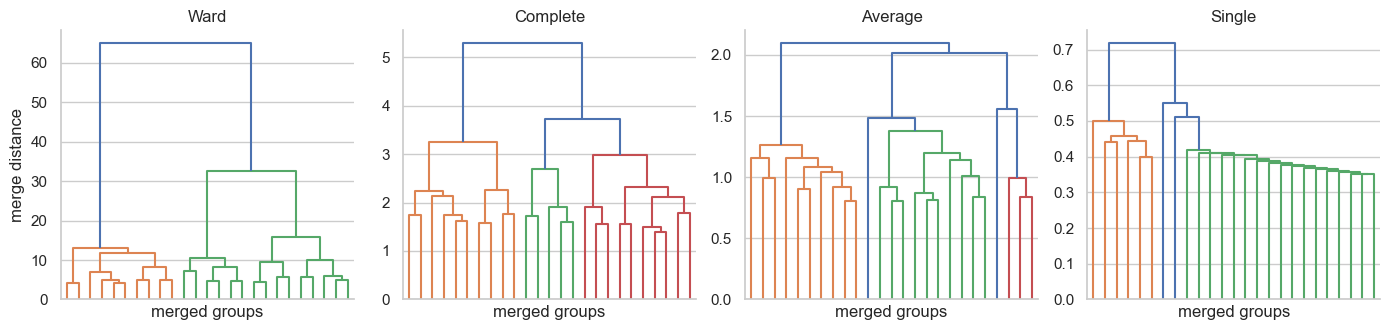

In [100]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.4))

hres = []

for a, meth in zip(axs, ['ward', 'complete', 'average', 'single']):
    L = linkage(Xh, meth)
    dendrogram(L, ax=a, truncate_mode='lastp', p=25, no_labels=True, color_threshold=None)
    a.set_title(meth.capitalize())
    a.set_xlabel('merged groups')
    row = dict(linkage=meth)
    for k in [2, 3, 4]:
        lk = fcluster(L, k, 'maxclust')
        row[f's{k}'] = silhouette_score(Xh, lk)
        row[f'z{k}'] = sorted(np.bincount(lk)[1:], reverse=True)
    row['ari_km3'] = adjusted_rand_score(lB[h], fcluster(L, 3, 'maxclust'))
    hres.append(row)

axs[0].set_ylabel('merge distance')

plt.tight_layout()

plt.savefig(f'{FIG}/clu_dendro.png', dpi=160)

_plt_show()


In [101]:
print(pd.DataFrame(hres).round(3).to_string())


    linkage     s2            z2     s3                z3     s4                     z4  ari_km3
0      ward  0.499  [1377, 1123]  0.430  [1123, 741, 636]  0.352  [1123, 636, 377, 364]    0.784
1  complete  0.502  [1411, 1089]  0.437  [1346, 1089, 65]  0.335   [1346, 785, 304, 65]    0.532
2   average  0.510   [1542, 958]  0.484   [1519, 958, 23]  0.454     [1519, 958, 14, 9]    0.531
3    single  0.443     [2493, 7]  0.157      [2492, 7, 1]  0.101        [2490, 7, 2, 1]   -0.000


In [102]:
L = linkage(Xh, 'ward')

print('ward last merge heights', L[-5:, 2].round(2))


ward last merge heights [11.71 13.01 15.87 32.63 64.98]


In [103]:
w3 = fcluster(L, 3, 'maxclust')

print(pd.crosstab(lB[h], w3))


col_0     1    2    3
row_0                
0         0  636  136
1        75    0  596
2      1048    0    9


### K-Means on the same sample (for comparison with Ward)

#### Working through this investigation: Use the same observations for a fair comparison

A clustering score depends on which sellers are evaluated. Here we compare K-Means partitions on the same 2,500-seller sample used for the hierarchical experiment. Keeping the sample and feature space fixed removes one avoidable source of mismatch.

We do not need the scores to be identical: the algorithms make different choices. We do need to avoid presenting a score from one population as if it were directly interchangeable with a score from another.

In [104]:
print('KM k3 sil on same sample', round(silhouette_score(Xh, lB[h]), 3), 'k2', round(silhouette_score(Xh, lB2[h]), 3))


KM k3 sil on same sample 0.447 k2 0.521


## 2.5 Final discussion: which algorithm is best?
- **K-Means k=3 on Model B** is the best result: highest silhouette (0.45) among methods that assign every seller, stable (subsample ARI 0.996), balanced, interpretable, related to the rating.
- **Ward** finds almost the same three groups (ARI 0.78). Complete/average isolate small extreme groups; single linkage chains.
- **DBSCAN / OPTICS / HDBSCAN** find only the new/used split: no density gap separates the mid-market sellers.
- **Bisecting K-Means** agrees only partly (ARI 0.62).
- The **10-attribute backup model** (2.6) adds a mainstream vs premium split of franchise dealers, but is much weaker (silhouette 0.21, Ward ARI 0.39 at k=4).

#### Working through this investigation: Restore the original data-preparation workspace

The main four-feature clustering experiment reused several Python variable names. We now restore the state saved before that experiment, including the prepared dataset from Section 1 and the earlier plotting settings.

This is inherited from the source notebook, so we keep it intact. It makes the execution order especially important: start in a fresh kernel, then use **Run All**. Later sections expect the prepared `df`, not the temporary raw `df` used inside the four-feature experiment.

In [105]:
# We restore the variables prepared in Section 1.

for _k in [k for k in list(globals()) if not k.startswith('_') and k not in _g_before]:
    del globals()[_k]

globals().update(_g_before)


In [106]:
plt.rcParams.update(_rc_before)


In [107]:
print('namespace restored')


namespace restored


### Why ten features may produce different clusters from four

A distance-based algorithm considers every selected coordinate. Adding a feature gives that property influence over the distance, even if it is not directly relevant to the segmentation goal. If two selected coordinates carry nearly identical information, that part of the seller profile may receive extra weight.

The backup model was designed to represent more aspects of the business: price, condition, inventory, turnover, discounts, and vehicle mix. It is not automatically superior just because it includes more information. We compare the **interpretability, stability, and coverage** of the resulting partitions.

## 2.6 Backup model: 10 attributes, K-Means k=4
### 2.6.1 Attribute selection
Clustering uses distances, so we (i) take **one representative per correlated block**, so that no concept counts twice; (ii) use **log-transformed** versions of the skewed variables; and (iii) **standardize** (z-score), so every attribute has the same weight. The 10 selected attributes describe price level, condition (mileage, % new), seller size and speed (listings, days on market, activity ratio), discounting (savings) and vehicle type (horsepower, fuel economy, % cab). The target is **not** used; we only use it afterwards to interpret the clusters.

#### Working through this investigation: Construct the ten-feature backup representation

The backup model describes sellers through ten attributes covering price, vehicle condition, inventory size, selling speed, discounting, and vehicle characteristics. We use the logarithmic features already created during preparation and scale the selected features with **StandardScaler**.

Standardization is approximately `(x - mean) / standard deviation`, so a unit means one standard deviation rather than one dollar, mile, or listing. This helps prevent numerical magnitude from dominating Euclidean distance. We also inspect correlations between selected inputs; scaling does **not** remove correlations, so the feature set still needs substantive justification.

In [108]:
clu_feats = ['log_price_median', 'log_mileage_median', 'pct_is_new', 'log_n_listings', 'log_daysonmarket_median', 'log_savings_amount_median', 'horsepower_median', 'city_fuel_economy_median', 'pct_isCab', 'activity_ratio']

X_clu = StandardScaler().fit_transform(df[clu_feats])

print(X_clu.shape)


(13843, 10)


In [109]:
pd.DataFrame(X_clu, columns=clu_feats).corr().abs().round(2).max().sort_values()


log_price_median             1.0
log_mileage_median           1.0
pct_is_new                   1.0
log_n_listings               1.0
log_daysonmarket_median      1.0
log_savings_amount_median    1.0
horsepower_median            1.0
city_fuel_economy_median     1.0
pct_isCab                    1.0
activity_ratio               1.0
dtype: float64

### 2.6.2 Centroid-based: K-Means
We test k = 2…12 with 10 initializations each and look at three criteria: SSE (elbow), silhouette (on a random 4,000-point sample, for speed) and Davies-Bouldin index (on all points).

#### Working through this investigation: Compare k values for the ten-feature model

We again calculate K-Means inertia, silhouette, and the Davies-Bouldin index, now in the ten-feature standardized space. A sampled silhouette estimate reduces computing time because pairwise-distance calculations can be expensive.

We keep the sampled indices fixed during the sweep. That matters because otherwise changes in score could reflect a different evaluation sample instead of the value of `k`. We read the three curves together and keep the final choice tied to interpretability, not only an attractive peak.

In [110]:
from sklearn.cluster import KMeans


In [111]:
rng = np.random.RandomState(RS)

sil_idx = rng.choice(len(X_clu), 4000, replace=False)

ks = range(2, 13)

sse, sil, dbi = ([], [], [])


In [112]:
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X_clu)
    sse.append(km.inertia_)
    sil.append(silhouette_score(X_clu[sil_idx], km.labels_[sil_idx]))
    dbi.append(davies_bouldin_score(X_clu, km.labels_))


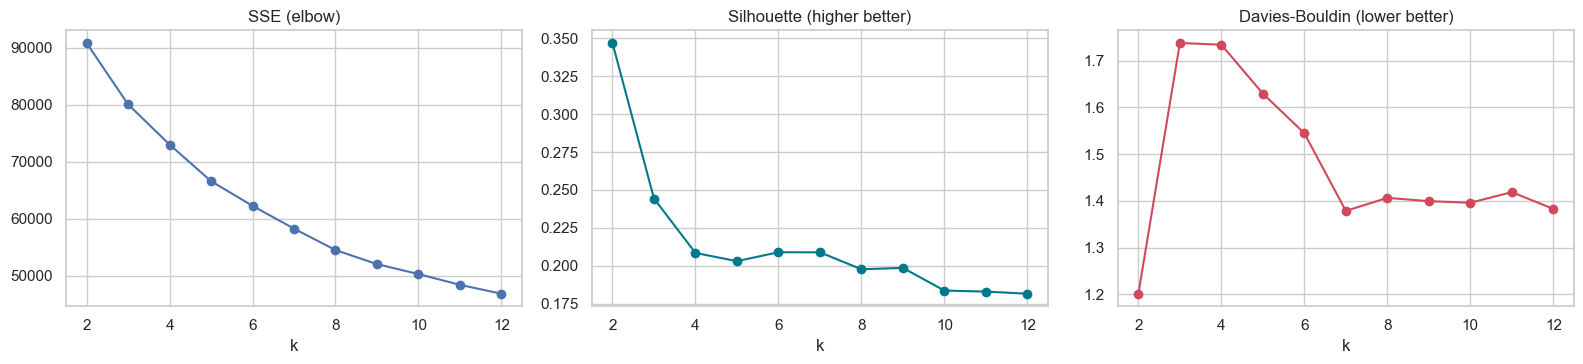

In [113]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))

ax[0].plot(ks, sse, 'o-')

ax[0].set_title('SSE (elbow)')

ax[1].plot(ks, sil, 'o-', color='#00798c')

ax[1].set_title('Silhouette (higher better)')

ax[2].plot(ks, dbi, 'o-', color='#d1495b')

ax[2].set_title('Davies-Bouldin (lower better)')

for a in ax:
    a.set_xlabel('k')

plt.tight_layout()

plt.show()


In [114]:
pd.DataFrame({'k': list(ks), 'SSE': np.round(sse), 'silhouette': np.round(sil, 3), 'DBI': np.round(dbi, 3)})


,k,SSE,silhouette,DBI
0,2,90848.0,0.347,1.202
1,3,80088.0,0.244,1.738
2,4,73043.0,0.208,1.734
3,5,66625.0,0.203,1.630
4,6,62291.0,0.209,1.545
5,7,58301.0,0.209,1.379
6,8,54540.0,0.198,1.407
7,9,52073.0,0.199,1.400
8,10,50335.0,0.184,1.396
9,11,48443.0,0.183,1.419


**Choice of k.** Silhouette and DBI are best at **k = 2** (0.347 / 1.20). However, k = 2 only separates new-car from used-car sellers, which we already know from `pct_is_new`. The SSE curve has no sharp elbow, and the silhouette is essentially flat (0.20-0.21) between k = 4 and k = 7. Within this plateau we choose **k = 4**, the smallest k that splits both the used and the new segments into interpretable sub-groups. We also confirm it with hierarchical clustering in 2.4. The low absolute silhouette (~0.2) is reported honestly: seller profiles change gradually, without clear gaps between groups.

#### Working through this investigation: Fit the chosen four-group backup model

We fit the chosen four-cluster solution and assign each seller to a group. **Centroids** are the average coordinates of points in each cluster in the standardized feature space. The heatmap shows which features are above or below the overall mean for each group.

We then return to familiar units, including dollars, miles, and listing counts, to build human-readable cluster profiles. The composition tables show ratings and franchise status inside each cluster. Always report cluster sizes along with percentages: 80% of a tiny cluster and 80% of a large cluster represent very different numbers of sellers.

In [115]:
K = 4

km = KMeans(n_clusters=K, n_init=20, random_state=RS).fit(X_clu)

df['km_cluster'] = km.labels_

print('sizes:', np.bincount(km.labels_), '| silhouette:', round(silhouette_score(X_clu[sil_idx], km.labels_[sil_idx]), 3))


sizes: [3898 2125 4957 2863] | silhouette: 0.208


In [116]:
cent = pd.DataFrame(km.cluster_centers_, columns=clu_feats)


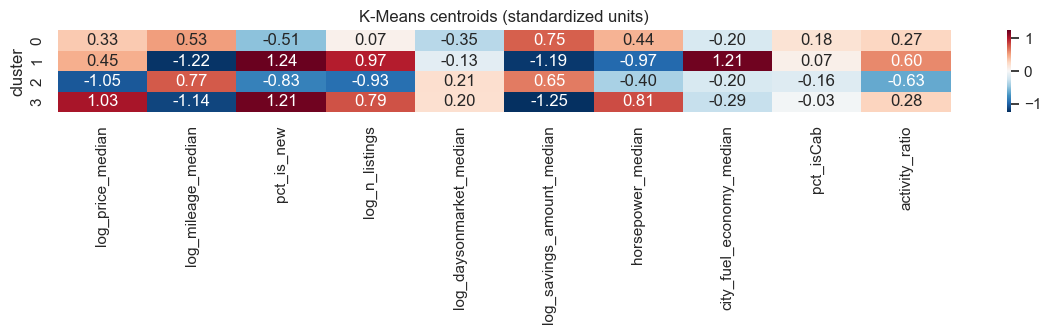

In [117]:
plt.figure(figsize=(12, 3.5))

sns.heatmap(cent, cmap='RdBu_r', center=0, annot=True, fmt='.2f')

plt.title('K-Means centroids (standardized units)')

plt.ylabel('cluster')

plt.tight_layout()

plt.show()


In [118]:
prof = df.groupby('km_cluster')[['price_median', 'mileage_median', 'pct_is_new', 'n_listings', 'daysonmarket_median', 'savings_amount_median', 'horsepower_median']].median()

prof['size'] = df.km_cluster.value_counts().sort_index()

display(prof.round(2))


,price_median,mileage_median,pct_is_new,n_listings,daysonmarket_median,savings_amount_median,horsepower_median,size
km_cluster,,,,,,,,
0,23500.0,34216.0,0.00,75.0,31.0,698.5,268.0,3898
1,25910.0,10.0,0.66,208.0,33.0,0.0,184.0,2125
2,9999.0,107017.0,0.00,21.0,40.5,589.0,210.0,4957
3,35572.5,13.0,0.65,169.0,41.5,0.0,285.0,2863


In [119]:
display((pd.crosstab(df.km_cluster, df.seller_rating_class, normalize='index')[order] * 100).round(1))


seller_rating_class,low,medium,high
km_cluster,,,
0,16.1,60.6,23.3
1,28.5,53.4,18.1
2,16.4,47.6,36.0
3,18.7,60.0,21.3


In [120]:
display((pd.crosstab(df.km_cluster, df.franchise_status, normalize='index') * 100).round(1))


franchise_status,franchise,independent
km_cluster,,
0,47.6,52.4
1,99.2,0.8
2,3.7,96.3
3,99.5,0.5


**Cluster interpretation (k = 4):**
- **C0 - mid-size used/mixed dealers** (3,898): mid price (~$23.5k), ~34k miles, highest savings; half franchise, half independent.
- **C1 - mainstream new-car franchise dealers** (2,125): ~66% new, low horsepower and economy cars, large inventories (median 208 listings), no savings advertised; 99% franchise.
- **C2 - small independent used-car lots** (4,957): cheap (~$10k), high mileage (~107k), small (21 listings); 96% independent.
- **C3 - premium new-car franchise dealers** (2,863): new, expensive (~$35.6k), high-horsepower vehicles; 99.5% franchise.

**Relation with the rating:** C2 (small independents) has the highest share of *high* ratings (36%), and C1 (large mainstream new-car franchises) the highest share of *low* ratings (28.5%). This agrees with what we found in Data Understanding: smaller sellers get better ratings. The clusters were found without the target, yet they recover a structure related to it.

#### Working through this investigation: Reduce ten dimensions to a viewable plane

**Principal Component Analysis (PCA)** finds directions in the data that preserve as much linear variance as possible. The first component captures the most variance; the second captures the largest remaining variance while being orthogonal to the first.

We use only the first two components for **visualization**, not to create the original clusters. The explained-variance ratio tells us what share of the ten-feature variability the plotted plane retains. Apparent overlap or separation in a 2D projection is suggestive, but it cannot perfectly represent distances in all ten dimensions.

In [121]:
from sklearn.decomposition import PCA


In [122]:
P = PCA(2, random_state=RS).fit(X_clu)

Z = P.transform(X_clu)

print('explained variance of 2 PCs (visualisation only):', P.explained_variance_ratio_.sum().round(3))


explained variance of 2 PCs (visualisation only): 0.578


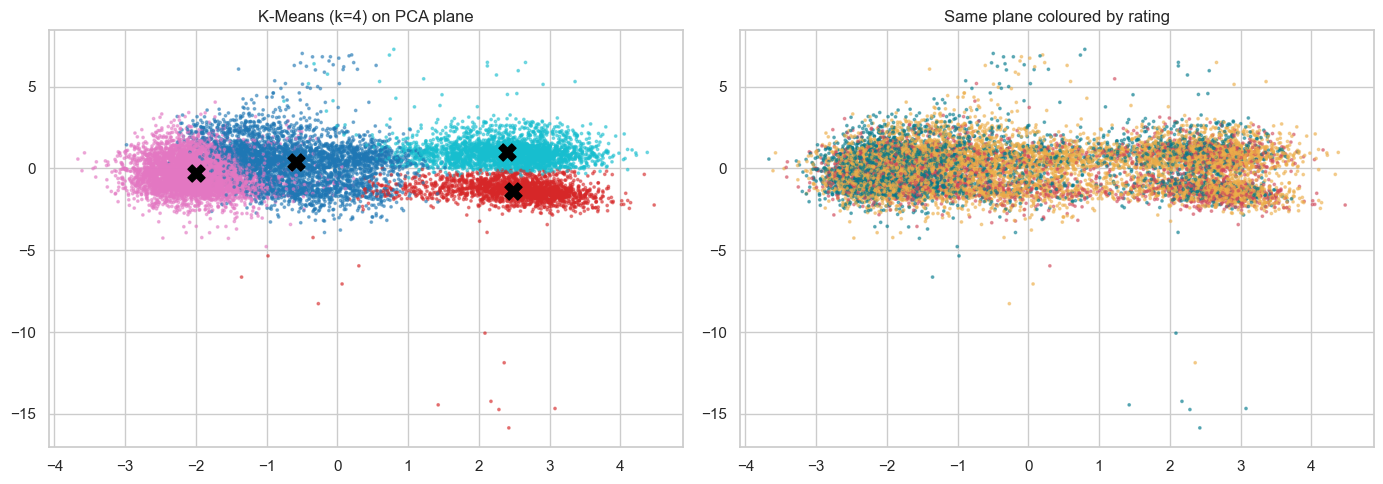

In [123]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(Z[:, 0], Z[:, 1], c=km.labels_, cmap='tab10', s=3, alpha=0.5)

ax[0].set_title('K-Means (k=4) on PCA plane')

cz = P.transform(km.cluster_centers_)

ax[0].scatter(cz[:, 0], cz[:, 1], c='black', marker='X', s=150)

cmap = {'low': '#d1495b', 'medium': '#edae49', 'high': '#00798c'}

ax[1].scatter(Z[:, 0], Z[:, 1], c=df.seller_rating_class.map(cmap), s=3, alpha=0.5)

ax[1].set_title('Same plane coloured by rating')

plt.tight_layout()

plt.show()


The PCA projection (58% of variance, used only for visualization) shows the four segments as adjacent regions of one continuum rather than separated blobs, which explains the moderate silhouette. Coloring the same points by rating shows that all three rating classes are spread over the whole plane.

#### Bisecting K-Means (optional)
Bisecting K-Means starts from one cluster and repeatedly splits the cluster with the largest SSE with a 2-means. We compare it with K-Means on the same attributes for k = 2…8.

#### Working through this investigation: Check bisecting K-Means on the backup space

We fit bisecting K-Means to the same standardized ten-feature data and compare it to the ordinary K-Means partition. We also inspect a contingency table of membership assignments.

The difference between **purity** and **ARI** matters. Purity asks how well one grouping can be matched to another by majority membership and can favor partitions with more groups. ARI adjusts for chance agreement and is more symmetric. We use both as descriptions, not as interchangeable measures.

In [124]:
from sklearn.cluster import BisectingKMeans


In [125]:
rows = []

for k in range(2, 9):
    bk = BisectingKMeans(n_clusters=k, n_init=10, bisecting_strategy='largest_cluster', random_state=RS).fit(X_clu)
    rows.append(dict(k=k, SSE=round(bk.inertia_), silhouette=round(silhouette_score(X_clu[sil_idx], bk.labels_[sil_idx]), 3), DBI=round(davies_bouldin_score(X_clu, bk.labels_), 3), sizes=sorted(np.bincount(bk.labels_), reverse=True)))

bis_res = pd.DataFrame(rows)

display(bis_res)


,k,SSE,silhouette,DBI,sizes
0,2,90848,0.347,1.202,"[8666, 5177]"
1,3,80741,0.238,1.768,"[5177, 4712, 3954]"
2,4,73525,0.199,1.788,"[4712, 3954, 3037, 2140]"
3,5,69483,0.156,1.760,"[3954, 3037, 3035, 2140, 1677]"
4,6,64046,0.174,1.753,"[3037, 3035, 2390, 2140, 1677, 1564]"
5,7,62152,0.154,1.822,"[3035, 2390, 2202, 2140, 1677, 1564, 835]"
6,8,60409,0.132,1.859,"[2390, 2202, 2140, 1679, 1677, 1564, 1356, 835]"


In [126]:
bk4 = BisectingKMeans(n_clusters=4, n_init=10, bisecting_strategy='largest_cluster', random_state=RS).fit(X_clu)

ct_b = pd.crosstab(pd.Series(bk4.labels_, name='Bisecting'), pd.Series(km.labels_, name='K-Means'))

display(ct_b)


K-Means,0,1,2,3
Bisecting,,,,
0,3655,17,272,10
1,20,6,4685,1
2,37,2100,0,3
3,186,2,0,2849


In [127]:
print('Bisecting(k=4) vs K-Means(k=4): purity =', round(ct_b.max(axis=1).sum() / len(X_clu), 3), '| SSE bisecting =', round(bk4.inertia_), 'vs K-Means =', round(km.inertia_))


Bisecting(k=4) vs K-Means(k=4): purity = 0.96 | SSE bisecting = 73525 vs K-Means = 73043


**Bisecting K-Means** gives the same picture: the first split (k = 2) is identical to K-Means (silhouette 0.347), and at k = 4 its clusters agree with K-Means on 96% of the sellers (purity 0.96), with almost the same SSE (73,525 vs 73,043). Its silhouette decreases faster for k > 4 because it can only split, never re-assign points between existing clusters. This independently confirms the four segments.

### 2.6.3 Density-based: DBSCAN
`eps` is chosen with the sorted k-distance graph (the knee of the m-th nearest-neighbor distance curve, with m = `min_samples`), then refined with a grid search.

#### Working through this investigation: Read neighbor-distance curves for DBSCAN

We calculate distances to the `m`-th nearest neighbor and sort them. A noticeable bend can suggest a neighborhood radius, although real datasets often have no single obvious bend.

The distance is measured in the standardized ten-feature space. An `eps` of 1 here does not mean one mile, one dollar, or one raw feature unit. If we change the feature set or scaler, these distances change too, and we need to reconsider the DBSCAN search range.

In [128]:
from sklearn.neighbors import NearestNeighbors


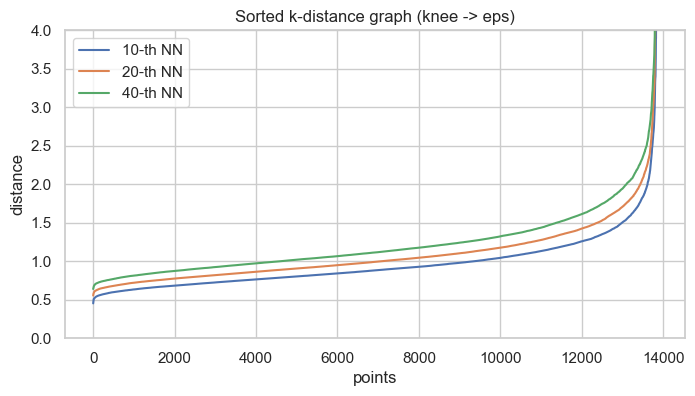

In [129]:
fig, ax = plt.subplots(figsize=(8, 4))

for m in [10, 20, 40]:
    d, _ = NearestNeighbors(n_neighbors=m).fit(X_clu).kneighbors(X_clu)
    ax.plot(np.sort(d[:, -1]), label=f'{m}-th NN')

ax.set_ylim(0, 4)

ax.set_title('Sorted k-distance graph (knee -> eps)')

ax.set_xlabel('points')

ax.set_ylabel('distance')

ax.legend()

plt.show()


The knee of the k-distance curves is at about **1.0-1.5** (standardized units), so we search `eps` in [0.8, 2.2] and `min_samples` ∈ {10, 20, 40}.

#### Working through this investigation: Run the density-based parameter grid

We try several combinations of neighborhood radius and minimum sample count. For every combination we record the number of clusters, percentage of noise sellers, and cluster sizes.

This table helps us rule out settings that merge nearly everyone into one dense group and settings that classify much of the dataset as noise. Parameter tuning is not simply about maximizing silhouette. We need a result that actually serves our goal of understanding seller segments.

In [130]:
from sklearn.cluster import DBSCAN


In [131]:
rows = []

for eps in [0.8, 1.0, 1.2, 1.5, 1.8, 2.2]:
    for ms in [10, 20, 40]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_clu)
        n_cl = len(set(lab)) - (-1 in lab)
        noise = (lab == -1).mean()
        mask = lab[sil_idx] != -1
        s = silhouette_score(X_clu[sil_idx][mask], lab[sil_idx][mask]) if n_cl > 1 and len(set(lab[sil_idx][mask])) > 1 else np.nan
        sizes = sorted(np.bincount(lab[lab >= 0]), reverse=True)[:4] if n_cl else []
        rows.append(dict(eps=eps, min_samples=ms, n_clusters=n_cl, noise_pct=round(noise * 100, 1), silhouette_no_noise=round(s, 3), top_sizes=sizes))

db_res = pd.DataFrame(rows)

db_res


,eps,min_samples,n_clusters,noise_pct,silhouette_no_noise,top_sizes
0,0.8,10,9,41.3,0.065,"[5278, 2776, 16, 15]"
1,0.8,20,8,55.8,0.190,"[3890, 1169, 912, 55]"
2,0.8,40,3,73.4,0.570,"[2523, 666, 494]"
3,1.0,10,4,16.4,-0.029,"[11505, 39, 19, 15]"
4,1.0,20,1,23.4,NaN,[10601]
5,1.0,40,2,33.5,0.464,"[5943, 3264]"
6,1.2,10,4,6.7,-0.004,"[12826, 70, 14, 12]"
7,1.2,20,3,10.5,0.121,"[12311, 44, 36]"
8,1.2,40,1,15.0,NaN,[11763]
9,1.5,10,1,2.3,NaN,[13523]


**Grid result.** For eps ≥ 1.5, DBSCAN finds a single cluster that contains nearly everything. For eps ≤ 0.8 it labels 40-75% of the points as noise. In between, there are two meaningful configurations:
- **A) eps = 1.2, min_samples = 20:** one dense core (12,311 sellers), two tiny clusters, and 10.5% noise. Here DBSCAN acts as an **outlier detector**.
- **B) eps = 1.0, min_samples = 40:** two clusters (5,943 / 3,264) with a high silhouette on the clustered points (0.46), at the cost of 33.5% noise.

The silhouette values of configurations with tiny clusters or > 50% noise are not comparable and are not used to choose.

#### Working through this investigation: Interpret density clusters and noise sellers

We compare the unusual observations identified by DBSCAN with the observations assigned to dense clusters. We also cross-tabulate DBSCAN groups against the four K-Means segments and compare rating distributions.

This can reveal two different uses for DBSCAN: segmenting dense groups, or flagging rare seller profiles for closer inspection. A noise label means “not in a sufficiently dense region under these parameters,” not “invalid seller.”

In [132]:
EPS, MS = (1.2, 20)

db = DBSCAN(eps=EPS, min_samples=MS).fit(X_clu)

df['db_cluster'] = db.labels_

db2 = DBSCAN(eps=1.0, min_samples=40).fit(X_clu)


In [133]:
df['db2_cluster'] = db2.labels_

print('A) eps=1.2, ms=20 sizes:', pd.Series(db.labels_).value_counts().to_dict())


A) eps=1.2, ms=20 sizes: {0: 12311, -1: 1452, 1: 44, 2: 36}


In [134]:
print('B) eps=1.0, ms=40 sizes:', pd.Series(db2.labels_).value_counts().to_dict())


B) eps=1.0, ms=40 sizes: {0: 5943, -1: 4636, 1: 3264}


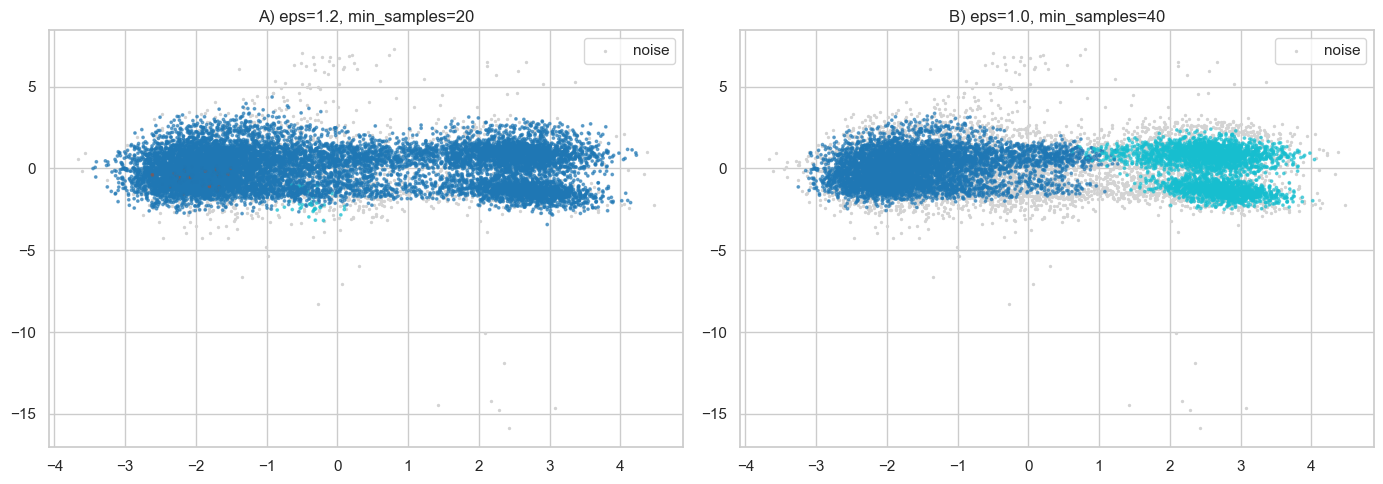

In [135]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for a, lab, t in [(ax[0], db.labels_, 'A) eps=1.2, min_samples=20'), (ax[1], db2.labels_, 'B) eps=1.0, min_samples=40')]:
    a.scatter(Z[lab == -1, 0], Z[lab == -1, 1], c='lightgrey', s=2, label='noise')
    a.scatter(Z[lab != -1, 0], Z[lab != -1, 1], c=lab[lab != -1], cmap='tab10', s=3, alpha=0.6)
    a.set_title(t)
    a.legend()

plt.tight_layout()

plt.show()


In [136]:
cols = ['price_median', 'mileage_median', 'pct_is_new', 'n_listings', 'daysonmarket_median', 'pct_isCab', 'city_fuel_economy_median']

print('A) medians, clustered vs noise:')


A) medians, clustered vs noise:


In [137]:
display(df.groupby(df.db_cluster == -1)[cols].median().rename(index={False: 'clustered', True: 'noise'}).round(2))


,price_median,mileage_median,pct_is_new,n_listings,daysonmarket_median,pct_isCab,city_fuel_economy_median
db_cluster,,,,,,,
clustered,22385.0,33881.0,0.0,74.0,36.0,0.11,20.0
noise,22382.5,32213.0,0.0,47.0,41.0,0.16,20.0


In [138]:
print('B) medians per cluster:')


B) medians per cluster:


In [139]:
display(df.groupby('db2_cluster')[cols].median().round(2))


,price_median,mileage_median,pct_is_new,n_listings,daysonmarket_median,pct_isCab,city_fuel_economy_median
db2_cluster,,,,,,,
-1,23842.0,29582.5,0.00,74.0,36.0,0.15,21.0
0,13990.0,88652.5,0.00,34.0,36.0,0.11,19.5
1,29992.5,10.0,0.66,197.0,37.0,0.11,21.0


In [140]:
print('B) vs K-Means clusters:')


B) vs K-Means clusters:


In [141]:
display(pd.crosstab(df.db2_cluster, df.km_cluster))


km_cluster,0,1,2,3
db2_cluster,,,,
-1,1643,769,1291,933
0,2255,20,3666,2
1,0,1336,0,1928


In [142]:
display((pd.crosstab(df.db_cluster == -1, df.seller_rating_class, normalize='index')[order] * 100).round(1))


seller_rating_class,low,medium,high
db_cluster,,,
False,18.5,55.7,25.8
True,19.5,46.8,33.7


**Discussion.** Configuration **B** recovers the two densest regions, which correspond to the "used" part of K-Means C0+C2 (cheap, high mileage) and the "new" part of C1+C3 (66% new, ~$30k, ~197 listings). It confirms the dominant new/used structure but leaves one third of the sellers unassigned. Configuration **A** is more useful as a data-quality tool: its noise points are smaller sellers with longer days-on-market and more cab vehicles, i.e., atypical inventories, and they are rated *high* more often (33.7% vs 25.8%). Overall, DBSCAN struggles here because the data has **one large region of slowly varying density** instead of separated dense groups, which is a typical failure case for density-based clustering.

#### OPTICS (optional)
OPTICS orders the points by reachability distance and does not need a single global `eps`, so it can in principle handle clusters of different density. It is run on the same 4,000-seller sample used for the silhouette (OPTICS is O(n²) in the worst case).

#### Working through this investigation: Inspect OPTICS over changing density thresholds

We plot reachability distances for a sampled set of sellers and vary the OPTICS extraction parameter `xi`. Smaller valleys in the reachability plot can correspond to dense groups; a smooth curve may signal gradually varying density instead.

We summarize the number of extracted clusters, their sizes, their silhouette when defined, and the noise share. These outcomes should be read together because a high score on only a tiny subset of points may not support a useful segmentation of the full seller population.

In [143]:
from sklearn.cluster import OPTICS


In [144]:
Xo = X_clu[sil_idx]

opt = OPTICS(min_samples=20, xi=0.05, min_cluster_size=0.02).fit(Xo)

reach = opt.reachability_[opt.ordering_]


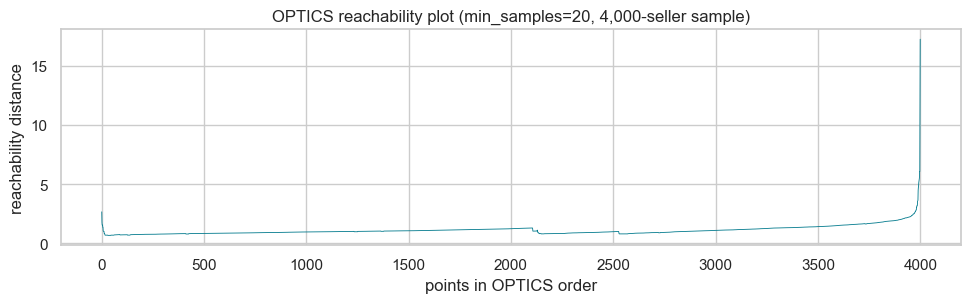

In [145]:
fig, ax = plt.subplots(figsize=(10, 3.2))

ax.plot(np.where(np.isinf(reach), np.nan, reach), lw=0.6, color='#00798c')

ax.set_title('OPTICS reachability plot (min_samples=20, 4,000-seller sample)')

ax.set_xlabel('points in OPTICS order')

ax.set_ylabel('reachability distance')

plt.tight_layout()

plt.show()


In [146]:
rows = []

for xi in [0.01, 0.02, 0.05, 0.1]:
    lab = OPTICS(min_samples=20, xi=xi, min_cluster_size=0.02).fit_predict(Xo)
    n_cl = len(set(lab)) - (-1 in lab)
    m = lab != -1
    s = silhouette_score(Xo[m], lab[m]) if n_cl > 1 else np.nan
    rows.append(dict(xi=xi, n_clusters=n_cl, noise_pct=round((lab == -1).mean() * 100, 1), silhouette_no_noise=round(s, 3), sizes=sorted(np.bincount(lab[m]), reverse=True)[:5] if n_cl else []))

pd.DataFrame(rows)


,xi,n_clusters,noise_pct,silhouette_no_noise,sizes
0,0.01,1,0.0,NaN,[4000]
1,0.02,1,0.0,NaN,[4000]
2,0.05,1,0.0,NaN,[4000]
3,0.10,1,0.0,NaN,[4000]


**OPTICS** finds a single cluster for every value of `xi` (0.01-0.10): the reachability plot has no deep valleys separated by high peaks, only a slowly rising profile. This is the strongest evidence that the sellers form **one continuum of varying density**, which explains why DBSCAN either merges everything or produces large noise.

#### HDBSCAN
HDBSCAN (presented in class together with OPTICS) builds the single-linkage hierarchy on the *mutual reachability* distance and keeps the most stable clusters, so it needs no `eps`. We vary `min_cluster_size` with `min_samples` = 20.

#### Working through this investigation: Check hierarchical density clustering with HDBSCAN

We vary `min_cluster_size` while keeping `min_samples` fixed, then inspect the number of discovered dense groups and the fraction treated as noise. We also compare the selected HDBSCAN partition to K-Means and examine median seller features.

The key lesson is to judge a density method by both **quality and coverage**. When most sellers are unassigned or groups only reproduce an obvious new/used divide, a simpler complete partition may be more useful for the original project.

In [147]:
from sklearn.cluster import HDBSCAN


In [148]:
rows = []

for mcs in [50, 100, 200, 400]:
    lab = HDBSCAN(min_cluster_size=mcs, min_samples=20, copy=True).fit_predict(X_clu)
    n_cl = len(set(lab)) - (-1 in lab)
    m = lab != -1
    s = silhouette_score(X_clu[sil_idx][m[sil_idx]], lab[sil_idx][m[sil_idx]]) if n_cl > 1 else np.nan
    rows.append(dict(min_cluster_size=mcs, n_clusters=n_cl, noise_pct=round((~m).mean() * 100, 1), silhouette_no_noise=round(s, 3), sizes=sorted(np.bincount(lab[m]), reverse=True)[:4] if n_cl else []))

hdb_res = pd.DataFrame(rows)

display(hdb_res)


,min_cluster_size,n_clusters,noise_pct,silhouette_no_noise,sizes
0,50,2,54.1,0.516,"[4200, 2159]"
1,100,2,54.1,0.516,"[4200, 2159]"
2,200,2,54.1,0.516,"[4200, 2159]"
3,400,2,54.1,0.516,"[4200, 2159]"


In [149]:
hdb = HDBSCAN(min_cluster_size=200, min_samples=20, copy=True).fit(X_clu)

df['hdb_cluster'] = hdb.labels_

display(pd.crosstab(df.hdb_cluster, df.km_cluster))


km_cluster,0,1,2,3
hdb_cluster,,,,
-1,2504,1196,2157,1627
0,1393,7,2800,0
1,1,922,0,1236


In [150]:
display(df.groupby('hdb_cluster')[['price_median', 'mileage_median', 'pct_is_new', 'n_listings']].median().round(2))


,price_median,mileage_median,pct_is_new,n_listings
hdb_cluster,,,,
-1,23995.0,28968.75,0.05,78.0
0,12998.5,93278.75,0.00,34.0
1,29887.5,10.00,0.67,202.0


### 2.6.4 Hierarchical clustering
Agglomerative clustering needs O(n²) memory, so we use a random sample of 2,500 sellers (18%) and compare four linkages with Euclidean distance (plus cosine distance with average linkage).

#### Working through this investigation: Build hierarchical clusters on a manageable sample

We sample 2,500 sellers because hierarchical methods can require large pairwise-distance structures. A distance matrix grows approximately with the square of the number of observations, so doubling the sample can mean roughly four times as many pairwise distances.

For each linkage strategy we draw a dendrogram and calculate silhouette for several candidate numbers of clusters. We keep the group sizes beside each score, because extreme imbalance is often the explanation for suspiciously high silhouette values.

In [151]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

from scipy.spatial.distance import pdist


In [152]:
h_idx = np.random.RandomState(RS).choice(len(X_clu), 2500, replace=False)

Xh = X_clu[h_idx]


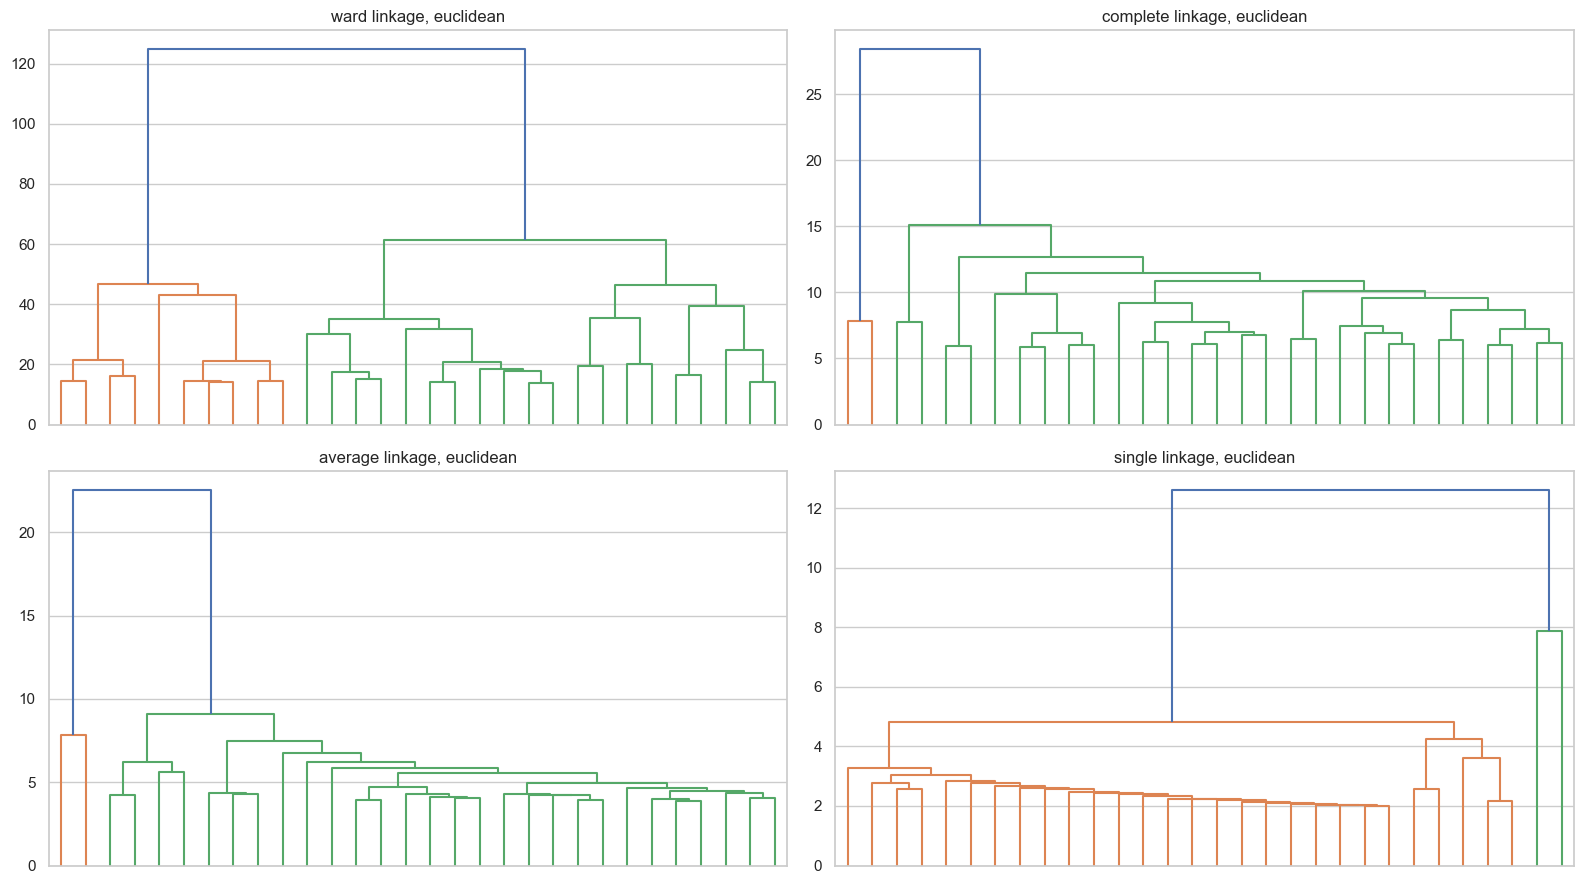

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))

res = []

for ax, (meth, metric) in zip(axes.ravel(), [('ward', 'euclidean'), ('complete', 'euclidean'), ('average', 'euclidean'), ('single', 'euclidean')]):
    L = linkage(Xh, method=meth, metric=metric)
    dendrogram(L, ax=ax, truncate_mode='lastp', p=30, no_labels=True, color_threshold=None)
    ax.set_title(f'{meth} linkage, {metric}')
    for k in [2, 3, 4, 5, 6]:
        lab = fcluster(L, k, criterion='maxclust')
        sizes = sorted(np.bincount(lab)[1:], reverse=True)
        res.append(dict(linkage=meth, k=k, silhouette=round(silhouette_score(Xh, lab), 3), sizes=sizes))

plt.tight_layout()

plt.show()


In [154]:
hc_res = pd.DataFrame(res)

hc_res.pivot(index='k', columns='linkage', values='silhouette')


linkage,average,complete,single,ward
k,,,,
2,0.817,0.817,0.817,0.327
3,0.548,0.608,0.787,0.240
4,0.548,0.424,0.608,0.202
5,0.441,0.135,0.600,0.199
6,0.352,0.243,0.593,0.200


#### Working through this investigation: Inspect the four-cluster hierarchical candidates

We narrow the hierarchical summary to `k = 4` so it can be compared to the selected K-Means backup model. At this point we are not fitting a new model; we are filtering the result table we built in the preceding step.

Look at the cluster sizes before discussing scores. A seemingly excellent silhouette can coexist with a partition that identifies only a few singleton outliers rather than the seller groups we want.

In [155]:
hc_res[hc_res.k == 4]


,linkage,k,silhouette,sizes
2,ward,4,0.202,"[1128, 589, 420, 363]"
7,complete,4,0.424,"[2481, 11, 6, 2]"
12,average,4,0.548,"[2489, 9, 1, 1]"
17,single,4,0.608,"[2492, 6, 1, 1]"


**Silhouette alone is misleading here.** Single, average and complete linkage reach very high silhouettes (0.55-0.82), but the cluster sizes show why: they produce one giant cluster plus a few singletons (e.g. sizes [2492, 6, 1, 1]). This is the classic **chaining effect** (single linkage) and **outlier isolation** (average/complete), and such a partition is useless. **Ward** linkage gives balanced clusters ([1128, 589, 420, 363] at k = 4); its dendrogram shows a large jump at 2 clusters and a smaller one around 4 clusters.

#### Working through this investigation: Compare cosine linkage and Ward agreement

Euclidean distance measures straight-line separation between feature vectors. **Cosine distance** instead emphasizes differences in direction, so sellers with similar relative patterns may appear close even when their magnitudes differ.

We compare average linkage with cosine distance and inspect Ward clusters against K-Means. The contingency table shows overlap; the purity statistic summarizes how much of the Ward grouping can be mapped onto dominant K-Means clusters. We keep the agreement interpretation grounded in the fact that both methods examine the same sampled sellers.

In [156]:
L_cos = linkage(Xh, method='average', metric='cosine')

for k in [3, 4]:
    lab = fcluster(L_cos, k, criterion='maxclust')
    print('average/cosine k=%d silhouette(cosine)=%.3f sizes=%s' % (k, silhouette_score(Xh, lab, metric='cosine'), sorted(np.bincount(lab)[1:], reverse=True)))

Lw = linkage(Xh, 'ward')

hw = fcluster(Lw, 4, criterion='maxclust')


average/cosine k=3 silhouette(cosine)=0.331 sizes=[np.int64(1612), np.int64(877), np.int64(11)]
average/cosine k=4 silhouette(cosine)=0.311 sizes=[np.int64(1316), np.int64(877), np.int64(296), np.int64(11)]


In [157]:
ct = pd.crosstab(pd.Series(hw, name='Ward'), pd.Series(km.labels_[h_idx], name='K-Means'))

display(ct)


K-Means,0,1,2,3
Ward,,,,
1,0,21,0,399
2,0,359,0,4
3,244,10,873,1
4,453,9,38,89


In [158]:
purity = ct.max(axis=1).sum() / ct.values.sum()

print('Agreement Ward(k=4) vs K-Means(k=4) on the same sample: purity =', round(purity, 3))


Agreement Ward(k=4) vs K-Means(k=4) on the same sample: purity = 0.834


With cosine distance (which compares profile *shape*, not magnitude) average linkage becomes more balanced, but it still isolates a group of 11 points. **Ward at k = 4 agrees well with K-Means** (the contingency table shows that each Ward cluster maps mainly to one K-Means cluster; purity = 0.83 on the same sample). This is expected, since both minimize within-cluster variance, and it independently supports the choice of 4 segments.

#### Working through this investigation: Summarize clustering approaches together

We gather the main clustering candidates into one comparison table with silhouette, number of clusters, and share of noise. Some algorithms always assign every observation, while density methods may leave substantial portions unassigned.

This comparison is useful for a final recommendation, but it has limitations: some numbers are computed on different subsets, and a silhouette on non-noise points is not a full-dataset score. The narrative must acknowledge these differences instead of ranking methods solely by their numerical silhouette.

In [159]:
comp = pd.DataFrame([dict(method='K-Means k=4', silhouette=silhouette_score(X_clu[sil_idx], km.labels_[sil_idx]), clusters=4, noise_pct=0), dict(method=f'DBSCAN eps={EPS}, ms={MS}', silhouette=silhouette_score(X_clu[sil_idx][db.labels_[sil_idx] != -1], db.labels_[sil_idx][db.labels_[sil_idx] != -1]) if len(set(db.labels_)) > 2 else np.nan, clusters=len(set(db.labels_)) - 1, noise_pct=(db.labels_ == -1).mean() * 100), dict(method='Bisecting K-Means k=4', silhouette=silhouette_score(X_clu[sil_idx], bk4.labels_[sil_idx]), clusters=4, noise_pct=0), dict(method='Hierarchical Ward k=4 (sample)', silhouette=silhouette_score(Xh, hw), clusters=4, noise_pct=0)])

comp.round(3)


,method,silhouette,clusters,noise_pct
0,K-Means k=4,0.208,4,0.000
1,"DBSCAN eps=1.2, ms=20",0.121,3,10.489
2,Bisecting K-Means k=4,0.199,4,0.000
3,Hierarchical Ward k=4 (sample),0.202,4,0.000


### 2.6.5 Discussion of the backup model (10-attribute space)
- **K-Means (k = 4)** is the most useful result: it assigns every seller, and its clusters are balanced and easy to interpret (two used-car and two new-car segments) and related to the rating.
- **Bisecting K-Means** reproduces the K-Means clusters almost exactly (purity 0.96).
- **Hierarchical Ward** confirms the same structure (purity 0.83, similar silhouette) but does not scale to the full dataset. The other linkages fail (chaining, singleton clusters).
- **DBSCAN** is not suited to this data (one region of continuously varying density): it gives either a single cluster or large noise. Its value is as an outlier detector. OPTICS confirms that there is no density gap to exploit.

The overall silhouette (~0.2) shows that the data has **gradients rather than well-separated groups**. This is a limitation of the dataset (aggregated medians smooth out differences), not of a specific algorithm.

### Checkpoint: what did clustering teach us?

We examined two feature representations and several families of clustering algorithms. We compared SSE, silhouette, Davies-Bouldin, stability, cluster size, and noise coverage. We learned that a mathematically high score can be misleading when almost every seller falls into one group.

**Test yourself:** Why does K-Means need scaled features? What does an ARI of 1 mean? Why is `-1` in DBSCAN not an ordinary cluster? What additional information does a cluster profile give beyond a silhouette score?

### Classification: what changes when we know the answers?

In clustering we did not reveal the rating to the model. In classification, training sellers **do** have their correct rating labels. The model learns from them and predicts the labels of unseen sellers.

**Train/test split:** training observations are used to fit models and choose settings; test observations are held aside for final evaluation. **Cross-validation:** training data are repeatedly split into fitting and validation folds so we can compare hyperparameters without repeatedly looking at the test set.

**Precision:** `TP / (TP + FP)` tells us how reliable positive predictions are. **Recall:** `TP / (TP + FN)` tells us how many real positives we identified. **F1:** `2 × precision × recall / (precision + recall)` combines the two. **Macro-F1** averages the per-class F1 scores without letting the majority class dominate.

# 3. Classification & Regression
## 3.1 Setup
- Features: 22 numeric (log versions for skewed ones) + 6 categorical (one-hot) = 45 columns. Cluster labels are **not** used as features.
- Hold-out: **70/30 stratified split** (same class proportions in train and test). Hyper-parameters are chosen with **5-fold stratified cross-validation on the training set only**, optimizing **macro-F1**. The test set is used once, at the end.
- **No information from the test set is used in preparation:** the 14 numeric variables with missing values are re-imputed with the body-type medians of the **training set only**, and the scaler and the discretizer are fitted on the training set. (Re-imputing changed no result by more than 0.002, because less than 0.3% of the values were missing.)
- KNN uses standardized features (it is distance-based). Trees use raw features (scale-invariant).
- **Baseline:** always predicting *medium* gives accuracy 0.547 but macro-F1 0.236. Every model must beat the baseline on macro-F1.

#### Working through this investigation: Create a protected classification experiment

We switch to **supervised learning**. Each example has input features and a known label `seller_rating_class`; the model learns a relationship between them and is evaluated on sellers that were not part of model fitting.

We reserve 30% for a **stratified test set**, keeping rating proportions similar in both subsets. Model settings are selected using five-fold cross-validation inside the training data. We rebuild numeric imputations from training data only, one-hot encode categorical variables, and fit a scaler on training examples. **Macro-F1** averages the F1 score of each class equally; F1 combines **precision** (correct predictions among predicted positives) and **recall** (correct predictions among true positives). These safeguards matter more than a seemingly impressive training accuracy.

In [160]:
# We define the seller-rating prediction experiment.

cls_num = ['log_n_listings', 'log_price_median', 'log_savings_amount_median', 'log_daysonmarket_median', 'log_mileage_median', 'vehicle_age_median', 'owner_count_median', 'horsepower_median', 'city_fuel_economy_median', 'back_legroom_median', 'front_legroom_median', 'fuel_tank_volume_median', 'height_median', 'length_median', 'width_median', 'pct_isCab', 'pct_is_new', 'pct_salvage', 'pct_theft_title', 'log_n_listing_days', 'log_listing_span_days', 'activity_ratio']

cls_cat = ['dominant_body_type', 'dominant_fuel_type', 'dominant_transmission', 'dominant_listing_color', 'franchise_status', 'new_used_profile']

y = df.seller_rating_class

idx_tr, idx_te = train_test_split(df.index, test_size=0.3, stratify=y, random_state=RS)


In [161]:
# We estimate replacement medians from training sellers only.

num_raw = [c for c in df_nan.columns if pd.api.types.is_numeric_dtype(df_nan[c]) and df_nan[c].isna().any()]

F = df.copy()


In [162]:
for c in num_raw:
    med_body = df_nan.loc[idx_tr].groupby('dominant_body_type')[c].median()
    F[c] = df_nan[c].fillna(df_nan.dominant_body_type.map(med_body)).fillna(df_nan.loc[idx_tr, c].median())

print('re-imputed (train statistics only):', num_raw)


re-imputed (train statistics only): ['mileage_median', 'vehicle_age_median', 'owner_count_median', 'horsepower_median', 'city_fuel_economy_median', 'back_legroom_median', 'front_legroom_median', 'fuel_tank_volume_median', 'height_median', 'length_median', 'width_median', 'pct_isCab', 'pct_salvage', 'pct_theft_title']


In [163]:
X_all = pd.get_dummies(F[cls_num + cls_cat], columns=cls_cat, drop_first=False, dtype=int)

X_tr, X_te, y_tr, y_te = (X_all.loc[idx_tr], X_all.loc[idx_te], y.loc[idx_tr], y.loc[idx_te])

sc = StandardScaler().fit(X_tr)

X_tr_s, X_te_s = (sc.transform(X_tr), sc.transform(X_te))


In [164]:
cv = StratifiedKFold(5, shuffle=True, random_state=RS)

print(X_tr.shape, X_te.shape)


(9690, 45) (4153, 45)


In [165]:
print('Majority-class baseline accuracy:', round((y_te == 'medium').mean(), 3), '| baseline macro-F1:', round(f1_score(y_te, ['medium'] * len(y_te), average='macro'), 3))


Majority-class baseline accuracy: 0.547 | baseline macro-F1: 0.236


In [166]:
results = {}

def evaluate(name, model, Xte):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)
    results[name] = dict(accuracy=accuracy_score(y_te, pred), macro_F1=f1_score(y_te, pred, average='macro'), weighted_F1=f1_score(y_te, pred, average='weighted'), macro_AUC=roc_auc_score(y_te, proba, multi_class='ovr', average='macro', labels=model.classes_))
    print(classification_report(y_te, pred, digits=3))
    ConfusionMatrixDisplay.from_predictions(y_te, pred, labels=order, cmap='Blues', normalize='true', values_format='.2f')
    plt.title(f'{name} - normalized confusion matrix')
    plt.grid(False)
    plt.show()
    return (pred, proba)


## 3.2 Decision Tree
Grid: criterion {gini, entropy} × max_depth {3, 5, 7, 9, 12, None} × min_samples_leaf {1, 10, 30, 60} × class_weight {None, balanced} (96 configurations × 5 folds).

#### Working through this investigation: Tune a decision tree without looking at test performance

A **decision tree** predicts a class by asking a sequence of feature-based questions. We search tree criteria, depth limits, leaf sizes, and class-weight settings using cross-validation on training sellers.

A deep tree can memorize small details in training data. A larger `min_samples_leaf` and lower `max_depth` constrain its complexity. **Gini impurity** and **entropy** are alternative measures of class mixing when choosing splits. We select the setting with the strongest cross-validated macro-F1, then leave the test set for final evaluation.

In [167]:
from sklearn.tree import DecisionTreeClassifier, plot_tree


In [ ]:
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=RS), {'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, 7, 9, 12, None], 'min_samples_leaf': [1, 10, 30, 60], 'class_weight': [None, 'balanced']}, scoring='f1_macro', cv=cv, n_jobs=1).fit(X_tr, y_tr)

print('best:', dt_grid.best_params_, '| CV macro-F1:', round(dt_grid.best_score_, 3))


In [ ]:
cvr = pd.DataFrame(dt_grid.cv_results_)

piv = cvr[cvr.param_class_weight.astype(str) == str(dt_grid.best_params_['class_weight'])].pivot_table(index='param_max_depth', columns='param_criterion', values='mean_test_score', aggfunc='max')

display(piv.round(3))


param_criterion,entropy,gini
param_max_depth,,
3,0.418,0.422
5,0.397,0.409
7,0.415,0.409
9,0.403,0.411
12,0.401,0.413


The best tree is **shallow (depth 3), gini, class_weight = balanced** (CV macro-F1 0.422). Deeper trees do *not* improve CV performance, so the extra splits fit noise. With `balanced` weights the tree stops ignoring the minority classes.

#### Working through this investigation: Evaluate and interpret the selected tree

We obtain predictions and class probabilities for the held-out sellers, then calculate accuracy, class-level metrics, macro-F1, and the confusion matrix. A normalized confusion matrix tells us, for each **true rating**, what fraction was predicted into each class.

We also print short tree rules, compare train and test macro-F1, and inspect feature importance. Tree importance measures how much splits reduced the training impurity; it does **not** prove a causal influence. When a feature dominates the ranking, we should check for redundant variables and whether the result matches the earlier exploratory patterns.

              precision    recall  f1-score   support

        high      0.399     0.602     0.480      1106
         low      0.313     0.257     0.282       774
      medium      0.612     0.497     0.549      2273

    accuracy                          0.480      4153
   macro avg      0.441     0.452     0.437      4153
weighted avg      0.499     0.480     0.481      4153



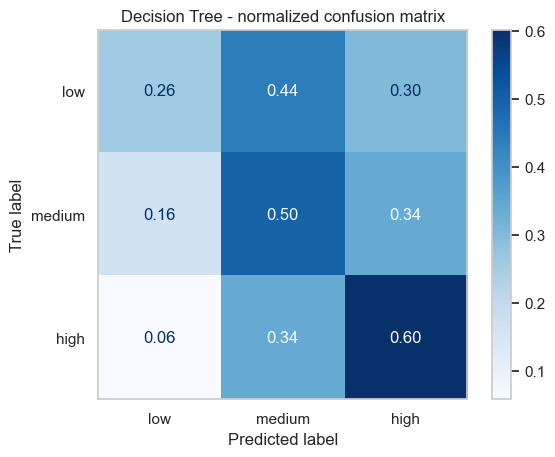

In [ ]:
dt = dt_grid.best_estimator_

dt_pred, dt_proba = evaluate('Decision Tree', dt, X_te)


In [ ]:
from sklearn.tree import export_text


In [ ]:
print(export_text(dt, feature_names=list(X_all.columns), max_depth=3))


|--- log_n_listings <= 4.66
|   |--- log_n_listings <= 3.42
|   |   |--- log_mileage_median <= 11.57
|   |   |   |--- class: high
|   |   |--- log_mileage_median >  11.57
|   |   |   |--- class: high
|   |--- log_n_listings >  3.42
|   |   |--- pct_is_new <= 0.03
|   |   |   |--- class: medium
|   |   |--- pct_is_new >  0.03
|   |   |   |--- class: high
|--- log_n_listings >  4.66
|   |--- log_price_median <= 10.19
|   |   |--- height_median <= 62.55
|   |   |   |--- class: low
|   |   |--- height_median >  62.55
|   |   |   |--- class: low
|   |--- log_price_median >  10.19
|   |   |--- log_n_listings <= 5.44
|   |   |   |--- class: medium
|   |   |--- log_n_listings >  5.44
|   |   |   |--- class: medium



In [ ]:
print('train macro-F1:', round(f1_score(y_tr, dt.predict(X_tr), average='macro'), 3), '(check over-fitting)')


train macro-F1: 0.451 (check over-fitting)


In [ ]:
imp = pd.Series(dt.feature_importances_, index=X_all.columns).sort_values(ascending=False).head(12)

print(imp.round(3))


log_n_listings              0.747
log_price_median            0.125
pct_is_new                  0.055
log_mileage_median          0.045
height_median               0.027
log_daysonmarket_median     0.000
vehicle_age_median          0.000
horsepower_median           0.000
owner_count_median          0.000
city_fuel_economy_median    0.000
back_legroom_median         0.000
front_legroom_median        0.000
dtype: float64


<Axes: >

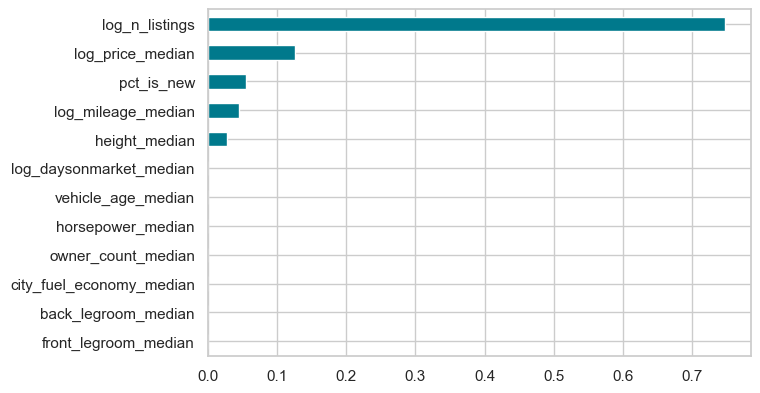

In [ ]:
imp[::-1].plot.barh(figsize=(7, 4.5), color='#00798c')


Text(0.5, 1.0, 'Decision Tree - top feature importances')

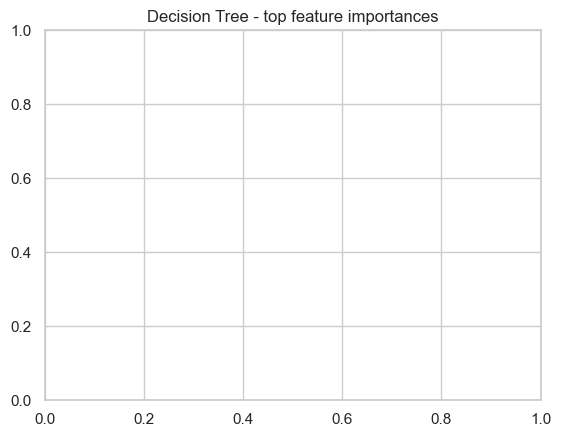

In [ ]:
plt.title('Decision Tree - top feature importances')


In [ ]:
plt.show()


<Figure size 640x480 with 0 Axes>

#### Working through this investigation: Draw an interpretable depth-three tree

We fit a small tree using the selected criterion and class-weight setting so that we can read its decisions from top to bottom. Internal nodes test a feature, branches represent the outcome, and leaves give the final class distribution or prediction.

The plot is a teaching aid, not a different data source. Its reported test macro-F1 lets us check whether the simplified model behaves like the selected fitted tree. A readable tree is especially helpful when a reviewer asks **why** the model predicted a particular class.

In [ ]:
small = DecisionTreeClassifier(max_depth=3, criterion=dt_grid.best_params_['criterion'], class_weight=dt_grid.best_params_['class_weight'], random_state=RS).fit(X_tr, y_tr)


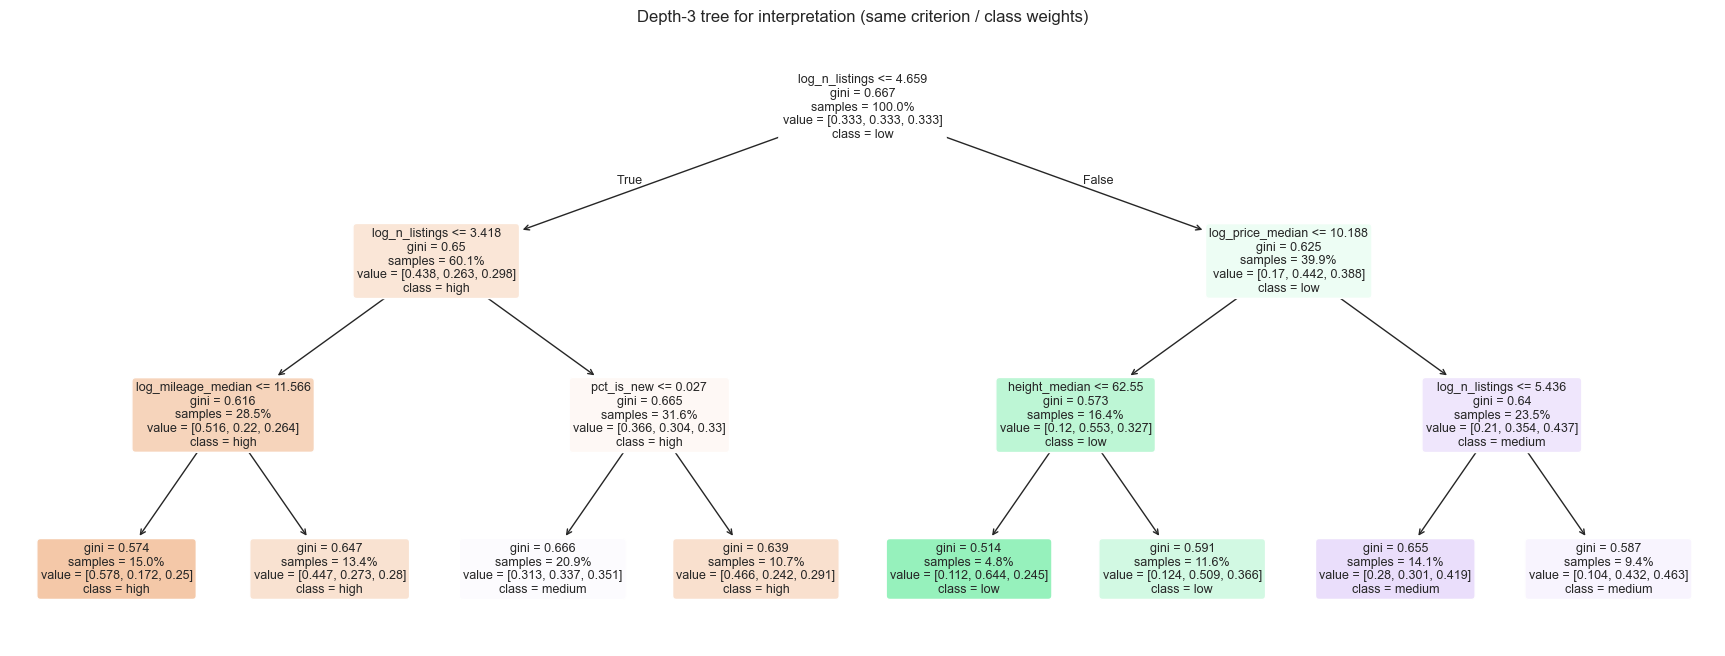

In [ ]:
plt.figure(figsize=(22, 8))

plot_tree(small, feature_names=X_all.columns, class_names=small.classes_, filled=True, rounded=True, fontsize=9, proportion=True)

plt.title('Depth-3 tree for interpretation (same criterion / class weights)')

plt.show()


In [ ]:
print('depth-3 test macro-F1:', round(f1_score(y_te, small.predict(X_te), average='macro'), 3))


depth-3 test macro-F1: 0.437


**Test results:** accuracy 0.480, **macro-F1 0.437** (baseline 0.236), macro AUC 0.62. Train macro-F1 is 0.451, so there is **no overfitting**: the limit comes from the data, not from the model. *High* is recognized reasonably well (recall 0.60), while *low* is the hardest class (F1 0.28): low-rated sellers look like medium-rated ones.

**Interpretation of the tree** (feature importance: `log_n_listings` 0.75, `log_price` 0.13, `pct_is_new` 0.06):
- sellers with **≤ ~105 listings** (log ≤ 4.66) → mostly **high**, especially very small ones (≤ ~30 listings);
- sellers with **> ~105 listings and cheap inventory** (price ≤ ~$26.6k) → **low**;
- large sellers with more expensive inventory → **medium**.

So seller size is by far the strongest predictor. A plausible explanation: small sellers receive few reviews, which pushes their average to extreme high values, while large dealers accumulate many reviews and regress toward medium/low.

## 3.3 K-Nearest Neighbors
Grid: k ∈ {1, 3, 5, 11, 21, 31, 51, 75}, weights {uniform, distance}, metric {euclidean, manhattan}, on standardized features.

#### Working through this investigation: Tune and evaluate K-nearest neighbors

**KNN** predicts a seller's class from nearby labeled sellers in feature space. We choose how many neighbors to consult, whether neighbors vote equally or by distance, and which distance metric to use.

KNN needs feature scaling: a change of thousands of dollars would otherwise overwhelm a proportion measured between zero and one. We fit the scaler on training data, run cross-validation, plot the settings, and finally evaluate the selected KNN on the held-out test data. When `k` becomes large, the most common class may dominate the neighborhood.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier


In [ ]:
knn_grid = GridSearchCV(KNeighborsClassifier(), {'n_neighbors': [1, 3, 5, 11, 21, 31, 51, 75], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']}, scoring='f1_macro', cv=cv, n_jobs=1).fit(X_tr_s, y_tr)

print('best:', knn_grid.best_params_, '| CV macro-F1:', round(knn_grid.best_score_, 3))


best: {'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'uniform'} | CV macro-F1: 0.388


Text(0.5, 0, 'k')

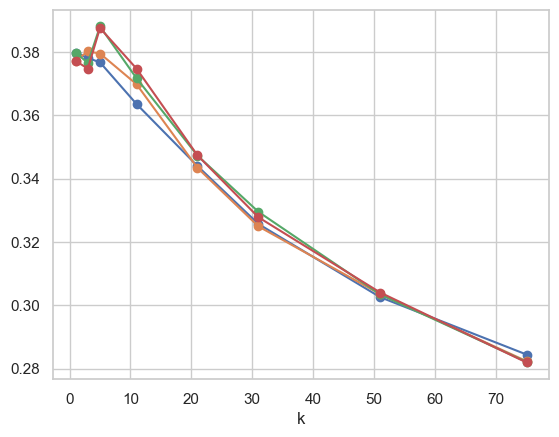

In [ ]:
kr = pd.DataFrame(knn_grid.cv_results_)

for (w, m), g in kr.groupby(['param_weights', 'param_metric']):
    plt.plot(g.param_n_neighbors.astype(int), g.mean_test_score, 'o-', label=f'{w}/{m}')

plt.xlabel('k')


Text(0, 0.5, 'CV macro-F1')

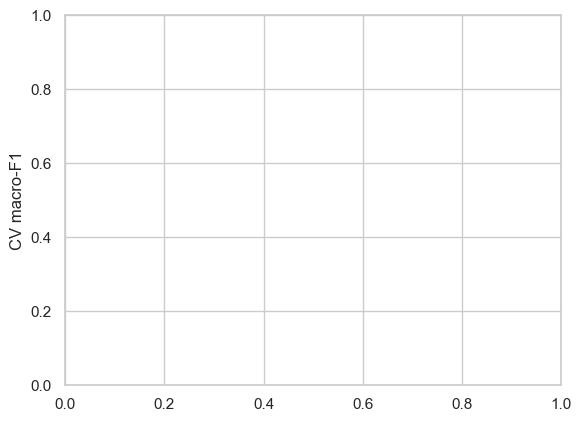

In [ ]:
plt.ylabel('CV macro-F1')


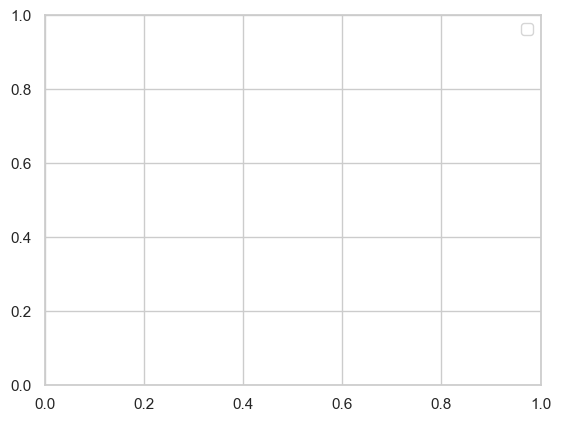

In [ ]:
plt.legend()


Text(0.5, 1.0, 'KNN: choice of k')

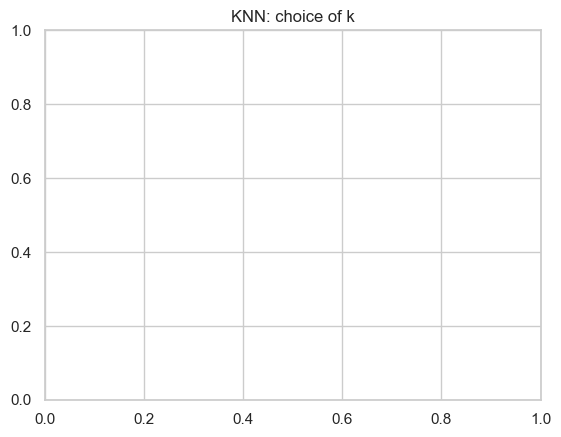

In [ ]:
plt.title('KNN: choice of k')


In [ ]:
plt.show()


<Figure size 640x480 with 0 Axes>

              precision    recall  f1-score   support

        high      0.357     0.347     0.352      1106
         low      0.267     0.186     0.219       774
      medium      0.587     0.656     0.619      2273

    accuracy                          0.486      4153
   macro avg      0.404     0.396     0.397      4153
weighted avg      0.466     0.486     0.474      4153



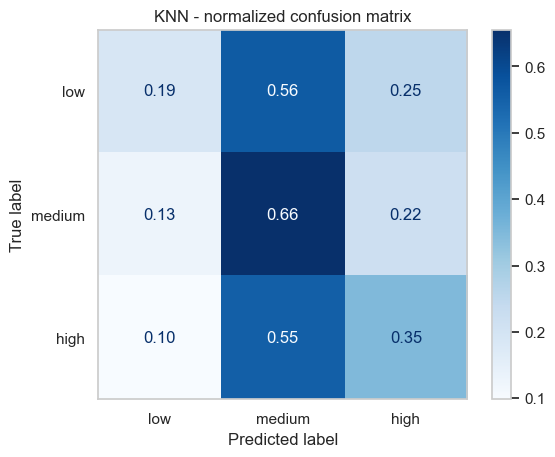

In [ ]:
knn = knn_grid.best_estimator_

knn_pred, knn_proba = evaluate('KNN', knn, X_te_s)


#### Working through this investigation: Test class balancing for KNN

We also test a balanced training sample containing the same number of sellers from each rating class. **Undersampling** removes some observations from the majority classes, changing what the neighborhood model sees.

This can help minority-class recognition, but it reduces the amount of training data and may lower overall accuracy. We compare both macro-F1 and class-level precision/recall rather than treating balancing as a guaranteed improvement. This is a diagnostic variant of the original KNN experiment.

In [ ]:
# We test KNN again after undersampling the training classes.

rng_b = np.random.RandomState(RS)

n_min = y_tr.value_counts().min()

bal_pos = np.concatenate([rng_b.choice(np.where(y_tr.values == c)[0], n_min, replace=False) for c in order])

knn_b = KNeighborsClassifier(**knn_grid.best_params_).fit(X_tr_s[bal_pos], y_tr.values[bal_pos])


In [ ]:
pb = knn_b.predict(X_te_s)

print('KNN on balanced training set: accuracy =', round(accuracy_score(y_te, pb), 3), '| macro-F1 =', round(f1_score(y_te, pb, average='macro'), 3))


KNN on balanced training set: accuracy = 0.359 | macro-F1 = 0.352


In [ ]:
print(classification_report(y_te, pb, digits=3))


              precision    recall  f1-score   support

        high      0.342     0.518     0.412      1106
         low      0.211     0.386     0.273       774
      medium      0.584     0.272     0.371      2273

    accuracy                          0.359      4153
   macro avg      0.379     0.392     0.352      4153
weighted avg      0.450     0.359     0.364      4153



The best CV setting is k = 5, uniform, euclidean (CV macro-F1 0.388). As k grows, accuracy rises but macro-F1 falls, because large neighborhoods are dominated by the majority class *medium*. On the test set KNN has the highest accuracy (0.486) but the lowest macro-F1 (0.397): it mostly predicts *medium* (recall 0.66) and misses *low* (recall 0.19). KNN also suffers here from the 45-dimensional, partly irrelevant feature space (curse of dimensionality: all one-hot dummies weigh as much as `n_listings`).

Unlike the tree, KNN cannot weight classes. To check whether this makes the comparison unfair, we refit it on a **class-balanced (undersampled) training set**: recall of *high* and *low* rises (0.52 / 0.39), but *medium* collapses (0.27), and macro-F1 drops to 0.352. Balancing therefore does not help KNN; its weakness comes from the noisy, high-dimensional neighbourhoods.

### Bayes' rule from the beginning

Bayes' rule is `P(A | B) = P(B | A) × P(A) / P(B)`. The vertical bar means **given**. `P(A)` is our prior belief about event A, and `P(B | A)` asks how likely we are to see evidence B when A is true.

In classification, A is a rating and B is the seller's set of features. A Naive Bayes model estimates how likely the features are within each rating class and combines that evidence with the class frequencies. It compares the resulting unnormalized scores and predicts the class with the largest one. The conditional-independence assumption makes the calculation manageable, but we should not assume the features are actually independent.

## 3.4 Naive Bayes
Two variants: **Gaussian NB** on the 22 numeric features (log transforms make them closer to Gaussian), and **Categorical NB** on all features, with numeric ones discretized into 5 quantile bins (this avoids the Gaussian assumption and uses the categorical attributes).

#### Working through this investigation: Fit Gaussian Naive Bayes

**Naive Bayes** predicts a class using Bayes' rule: `P(class | features) ∝ P(features | class) × P(class)`. The “naive” assumption is that features are conditionally independent given the class. This is often unrealistic, but it can still work as a simple baseline.

**Gaussian NB** models each numeric feature inside each class using a bell-shaped distribution. We search smoothing strengths to avoid unstable near-zero variances, and we compare empirical versus equal class priors. Because correlated features can effectively count the same signal several times, we interpret the result with the earlier correlation analysis in mind.

In [ ]:
from sklearn.naive_bayes import GaussianNB, CategoricalNB


In [ ]:
# We fit Gaussian NB using only numeric predictor columns.

gnb = GridSearchCV(GaussianNB(), {'var_smoothing': np.logspace(-11, -1, 11), 'priors': [None, [1 / 3, 1 / 3, 1 / 3]]}, scoring='f1_macro', cv=cv).fit(X_tr[cls_num], y_tr)

print('GaussianNB best:', gnb.best_params_, '| CV macro-F1:', round(gnb.best_score_, 3))


GaussianNB best: {'priors': None, 'var_smoothing': np.float64(1e-06)} | CV macro-F1: 0.429


              precision    recall  f1-score   support

        high      0.377     0.482     0.423      1106
         low      0.288     0.227     0.254       774
      medium      0.607     0.568     0.587      2273

    accuracy                          0.482      4153
   macro avg      0.424     0.426     0.421      4153
weighted avg      0.486     0.482     0.481      4153



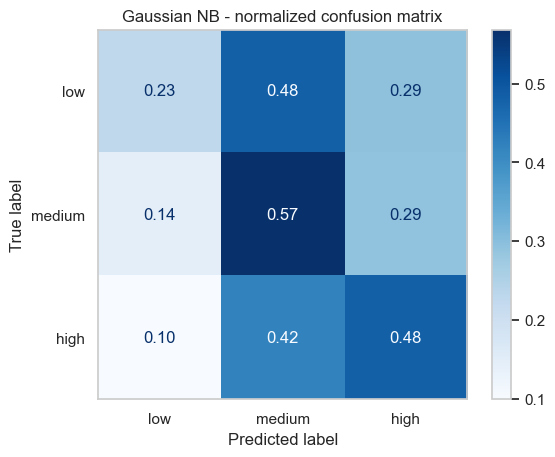

In [ ]:
gnb_pred, gnb_proba = evaluate('Gaussian NB', gnb.best_estimator_, X_te[cls_num])


Gaussian NB: test macro-F1 0.421, accuracy 0.482. The grid also tried **uniform class priors** (to compensate the imbalance), but the empirical priors were better in cross-validation. This is good considering that the independence assumption is clearly violated (Section 1.5 found strongly correlated blocks, so correlated evidence is counted several times).

#### Working through this investigation: Fit Categorical Naive Bayes

Categorical NB needs discrete feature values. We divide numeric variables into five quantile bins and encode the original categories with integer labels, using transformations fitted on training data. A quantile bin contains roughly the same number of observations, though ties can affect the exact boundaries.

We then fit Categorical NB with several **Laplace smoothing** strengths (`alpha`) and prior settings. Smoothing prevents an unseen category from forcing a probability to exactly zero. The extra code for previously unseen test categories is retained from the source implementation. The resulting classifier gives us a useful contrast with Gaussian NB's continuous numeric assumptions.

In [ ]:
from sklearn.preprocessing import KBinsDiscretizer, OrdinalEncoder


In [ ]:
# We discretize numeric features using training-fitted quantile bins.

kb = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')

oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

B_tr = np.hstack([kb.fit_transform(F.loc[idx_tr, cls_num]), oe.fit_transform(F.loc[idx_tr, cls_cat])])

B_te = np.hstack([kb.transform(F.loc[idx_te, cls_num]), oe.transform(F.loc[idx_te, cls_cat])])


In [ ]:
# We reserve a separate category code for unseen test values.

n_cat = B_tr.max(0).astype(int) + 1

B_te = np.where(B_te < 0, n_cat, B_te)

print('test values with a category unseen in training:', int((B_te == n_cat).sum()))


test values with a category unseen in training: 0


In [ ]:
cnb = GridSearchCV(CategoricalNB(min_categories=n_cat + 1), {'alpha': [0.1, 0.5, 1, 2, 5], 'fit_prior': [True, False]}, scoring='f1_macro', cv=cv).fit(B_tr, y_tr)

print('CategoricalNB best:', cnb.best_params_, '| CV macro-F1:', round(cnb.best_score_, 3))


CategoricalNB best: {'alpha': 5, 'fit_prior': True} | CV macro-F1: 0.413


              precision    recall  f1-score   support

        high      0.351     0.590     0.440      1106
         low      0.299     0.236     0.264       774
      medium      0.617     0.457     0.525      2273

    accuracy                          0.451      4153
   macro avg      0.422     0.428     0.410      4153
weighted avg      0.487     0.451     0.454      4153



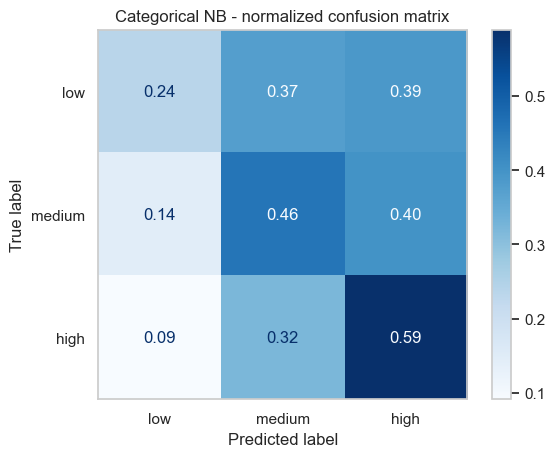

In [ ]:
cnb_pred, cnb_proba = evaluate('Categorical NB', cnb.best_estimator_, B_te)


Categorical NB (α = 5, empirical priors): macro-F1 0.410. Categories never seen in training get their own code, so they receive the small Laplace-smoothed probability instead of being confused with an existing category. It favors the *high* class (recall 0.59) at the expense of *medium*. Discretization loses information inside each bin, which explains why it is slightly worse than the Gaussian version.

#### Working through this investigation: Compare models and inspect ROC curves

We assemble the main classification metrics into a table and plot one-vs-rest **ROC curves**. For each rating, the ROC curve treats that class as positive and the other two as negative, showing how the true-positive rate changes relative to the false-positive rate as we move the probability threshold.

**AUC** summarizes the ROC curve; 0.5 resembles random ranking and 1 indicates perfect separation for that one-vs-rest task. We do not pick a winner based only on AUC or accuracy. Macro-F1 is the project's key selection measure because every rating class matters.

In [ ]:
res_df = pd.DataFrame(results).T.round(3)

display(res_df)


,accuracy,macro_F1,weighted_F1,macro_AUC
Decision Tree,0.480,0.437,0.481,0.621
KNN,0.486,0.397,0.474,0.570
Gaussian NB,0.482,0.421,0.481,0.598
Categorical NB,0.451,0.410,0.454,0.601


In [ ]:
probas = {'Decision Tree': (dt_proba, dt.classes_), 'KNN': (knn_proba, knn.classes_), 'Gaussian NB': (gnb_proba, gnb.best_estimator_.classes_), 'Categorical NB': (cnb_proba, cnb.best_estimator_.classes_)}


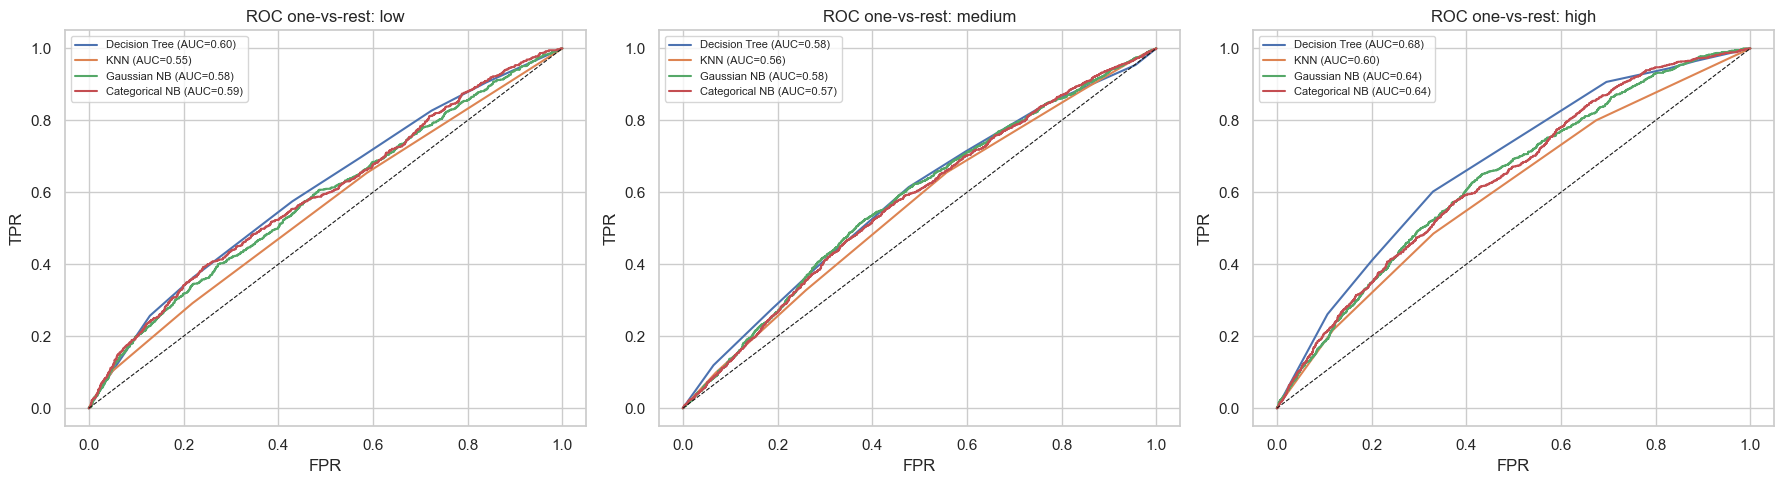

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, cls in zip(axes, order):
    for name, (p, classes) in probas.items():
        j = list(classes).index(cls)
        fpr, tpr, _ = roc_curve(y_te == cls, p[:, j])
        ax.plot(fpr, tpr, label=f'{name} (AUC={auc(fpr, tpr):.2f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
    ax.set_title(f'ROC one-vs-rest: {cls}')
    ax.legend(fontsize=8)
    ax.set_xlabel('FPR')
    ax.set_ylabel('TPR')

plt.tight_layout()

plt.show()


In [ ]:
auc_tab = {}

for name, (p, classes) in probas.items():
    auc_tab[name] = {cls: round(roc_auc_score(y_te == cls, p[:, list(classes).index(cls)]), 3) for cls in order}

print(pd.DataFrame(auc_tab).T)


                  low  medium   high
Decision Tree   0.603   0.583  0.677
KNN             0.552   0.558  0.601
Gaussian NB     0.580   0.579  0.636
Categorical NB  0.590   0.574  0.638


## 3.5 Comparison of classifiers
| Model | Accuracy | Macro-F1 | Macro AUC |
|---|---|---|---|
| Baseline (always medium) | 0.547 | 0.236 | 0.50 |
| **Decision Tree (depth 3, balanced)** | 0.480 | **0.437** | **0.621** |
| Gaussian NB | 0.482 | 0.421 | 0.598 |
| Categorical NB | 0.451 | 0.410 | 0.601 |
| KNN (k = 5) | 0.486 | 0.397 | 0.570 |
| KNN (k = 5, balanced training set) | 0.359 | 0.352 | - |

The **Decision Tree is the best model** on macro-F1 and AUC, and it is also the most interpretable. As the guidelines warn, performance is modest for every model: the one-vs-rest ROC curves show that *high* vs rest is the most separable class (AUC 0.68 for the tree, 0.60-0.64 for the others), while *medium* vs rest is the least separable (AUC 0.56-0.58): medium sits between the two other classes. All models beat the baseline on macro-F1, so they extract real signal. The remaining error comes from information that the dataset does not contain (review counts, service quality, location).

## 3.6 Additional classification task: franchise status
We also predict `franchise_status` from the other inventory features (decision tree, same protocol).

#### Working through this investigation: Try franchise status as a second target

We reuse the classification framework but change the prediction target to `franchise_status`. We explicitly remove the one-hot encoding of that target from the inputs, because using the answer as a feature would be direct **target leakage**.

The experiment tests whether seller inventory features alone strongly distinguish franchise and independent sellers. We still need to check that any dominant predictor is not simply a near-definition of the target. A very high score on a related administrative label may be less impressive than a moderate score on a genuinely difficult outcome.

In [ ]:
# We predict franchise status without feeding the target itself to the model.

Xf = X_all.drop(columns=[c for c in X_all.columns if c.startswith('franchise_status')])

yf = df.franchise_status

Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(Xf, yf, test_size=0.3, stratify=yf, random_state=RS)

dtf = GridSearchCV(DecisionTreeClassifier(random_state=RS), {'max_depth': [3, 5, 7, 9], 'min_samples_leaf': [10, 30]}, scoring='f1_macro', cv=cv).fit(Xf_tr, yf_tr)


In [ ]:
pf = dtf.predict(Xf_te)

print('best:', dtf.best_params_)


best: {'max_depth': 7, 'min_samples_leaf': 30}


In [ ]:
print(classification_report(yf_te, pf, digits=3))


              precision    recall  f1-score   support

   franchise      0.982     0.938     0.960      2100
 independent      0.939     0.982     0.960      2053

    accuracy                          0.960      4153
   macro avg      0.961     0.960     0.960      4153
weighted avg      0.961     0.960     0.960      4153



In [ ]:
print(pd.Series(dtf.best_estimator_.feature_importances_, index=Xf.columns).sort_values(ascending=False).head(6).round(3))


pct_is_new                 0.917
vehicle_age_median         0.043
pct_isCab                  0.010
log_daysonmarket_median    0.005
width_median               0.005
log_price_median           0.004
dtype: float64


This task is almost trivial: accuracy and F1 are 0.96, and `pct_is_new` alone carries 92% of the importance. In practice, **only franchise dealers sell new cars**. This confirms the semantics found in clustering (C1/C3 are 99% franchise) and shows by contrast that the difficulty of the rating task is intrinsic.

### Regression: a prediction and an error

If a seller's true price is $20,000 and our predicted price is $18,000, the residual on the original dollar scale is `$20,000 - $18,000 = $2,000`. **MAE** averages absolute residual sizes, while **MSE** squares them first, giving large mistakes more weight. **RMSE** is the square root of MSE and returns to the target's units.

Here the target is initially `log1p(price)`, so MSE and MAE are measured in **log-price units**, not dollars. We only interpret an error in dollars after explicitly transforming predictions and true values back with `expm1`. A high R² is not automatically evidence that we identified causal determinants of pricing.

## 3.7 Regression
**Target:** `log_price_median`. Price is continuous and right-skewed; the log stabilizes the variance and turns multiplicative effects (e.g., depreciation per extra mile) into additive ones.

### Simple linear regression
Independent variable: `log_mileage_median`, the variable most correlated with log price (|ρ| = 0.82).

#### Working through this investigation: Start regression with one explanatory variable

**Regression** predicts a number, not a class. The response here is log-transformed median price, and the initial predictor is log-transformed mileage. We fit a straight-line relationship using training sellers, then check predictions on the test sellers.

The model is of the form `ŷ = b₀ + b₁x`, where `ŷ` is predicted log price, `b₀` is the intercept, and `b₁` is the fitted slope. **R²** summarizes improvement over predicting the mean of the test target; **MSE** averages squared errors; **MAE** averages absolute errors. The residual plot displays `actual - predicted` and helps reveal patterns the line cannot capture.

In [ ]:
from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor

from sklearn.neighbors import KNeighborsRegressor


In [ ]:
yr = df.log_price_median

print('|Spearman| with log price:')


|Spearman| with log price:


In [ ]:
print(df[['vehicle_age_median', 'log_mileage_median', 'horsepower_median', 'pct_is_new', 'owner_count_median']].corrwith(yr, method='spearman').round(3))


vehicle_age_median   -0.815
log_mileage_median   -0.823
horsepower_median     0.489
pct_is_new            0.718
owner_count_median   -0.717
dtype: float64


In [ ]:
x1 = df[['log_mileage_median']]

x1_tr, x1_te, y1_tr, y1_te = (x1.loc[idx_tr], x1.loc[idx_te], yr.loc[idx_tr], yr.loc[idx_te])

lr1 = LinearRegression().fit(x1_tr, y1_tr)

p1 = lr1.predict(x1_te)


In [ ]:
print(f'log_price = {lr1.intercept_:.3f} + {lr1.coef_[0]:.3f} * log_mileage')


log_price = 10.646 + -0.093 * log_mileage


In [ ]:
reg_res = {'Simple linear (log_mileage)': dict(R2=r2_score(y1_te, p1), MSE=mean_squared_error(y1_te, p1), MAE=mean_absolute_error(y1_te, p1))}


Text(0.5, 1.0, 'Residuals')

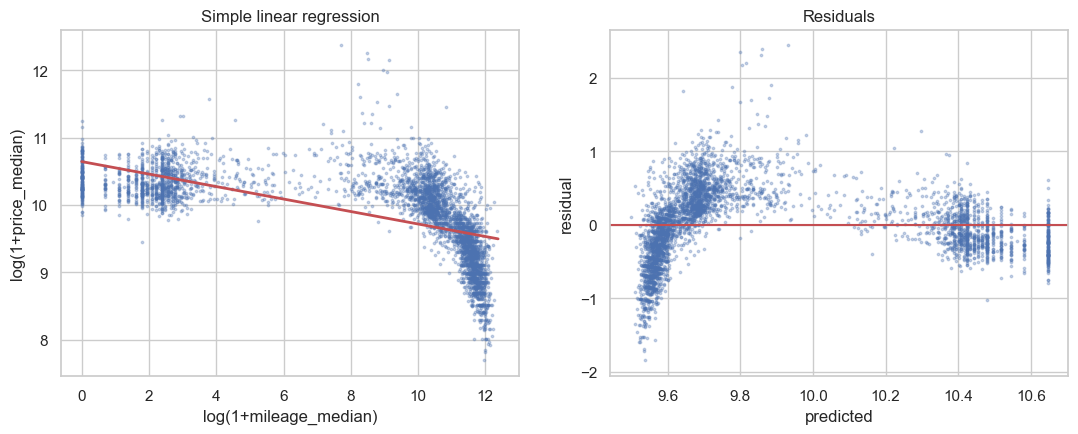

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].scatter(x1_te, y1_te, s=3, alpha=0.3)

xs = np.linspace(x1.min().iloc[0], x1.max().iloc[0], 100).reshape(-1, 1)

ax[0].plot(xs, lr1.predict(pd.DataFrame(xs, columns=x1.columns)), 'r', lw=2)

ax[0].set_xlabel('log(1+mileage_median)')

ax[0].set_ylabel('log(1+price_median)')

ax[0].set_title('Simple linear regression')

ax[1].scatter(p1, y1_te - p1, s=3, alpha=0.3)

ax[1].axhline(0, color='r')

ax[1].set_xlabel('predicted')

ax[1].set_ylabel('residual')

ax[1].set_title('Residuals')


In [ ]:
plt.tight_layout()


<Figure size 640x480 with 0 Axes>

In [ ]:
plt.show()


<Figure size 640x480 with 0 Axes>

In [ ]:
pd.DataFrame(reg_res).T.round(4)


,R2,MSE,MAE
Simple linear (log_mileage),0.3814,0.2383,0.3858


Fit: log price = 10.65 − 0.093 · log(1 + mileage), test **R² = 0.381**, MSE = 0.238. The relation is negative as expected, but one line cannot fit the two populations: new-car dealers (mileage ≈ 0) have a wide range of prices (economy vs premium), and the residual plot shows a clear structure, so a single predictor is not enough.

### Multiple regression (same target, 13 independent variables + body type + franchise)
`savings_amount_median` is **excluded**: the advertised saving is part of the price announcement itself (ρ = −0.47 with price), so using it to predict price would be close to target leakage. One linear model (OLS) and two non-linear models (Decision Tree Regressor, KNN Regressor), tuned with 5-fold CV on R².

#### Working through this investigation: Compare richer regression methods

We expand to several explanatory variables and encode categories as indicator columns. We intentionally leave advertised savings out because it is mechanically related to advertised price, which could make the prediction artificially easy.

We evaluate ordinary least squares, a regression tree, and KNN regression using the same training/test indices. Scaling is applied for the methods that benefit from it. Hyperparameters for tree and KNN regression are selected by cross-validation on training data. Every model then receives the same held-out evaluation with R², MSE, and MAE.

In [ ]:
# We reuse the existing train/test indices for regression.

reg_feats = ['log_mileage_median', 'vehicle_age_median', 'horsepower_median', 'pct_is_new', 'owner_count_median', 'city_fuel_economy_median', 'length_median', 'width_median', 'height_median', 'pct_isCab', 'pct_salvage', 'log_daysonmarket_median', 'log_n_listings']

Xr = pd.get_dummies(F[reg_feats + ['dominant_body_type', 'franchise_status']], columns=['dominant_body_type', 'franchise_status'], drop_first=True, dtype=int)

Xr_tr, Xr_te, yr_tr, yr_te = (Xr.loc[idx_tr], Xr.loc[idx_te], yr.loc[idx_tr], yr.loc[idx_te])

scr = StandardScaler().fit(Xr_tr)


In [ ]:
# We reuse the existing train/test indices for regression.

Xr_tr_s, Xr_te_s = (scr.transform(Xr_tr), scr.transform(Xr_te))

models = {'Multiple linear (OLS)': (LinearRegression(), {}, True), 'Decision Tree Regressor': (DecisionTreeRegressor(random_state=RS), {'max_depth': [4, 6, 8, 10, 14], 'min_samples_leaf': [5, 20, 50]}, False), 'KNN Regressor': (KNeighborsRegressor(), {'n_neighbors': [5, 10, 20, 40], 'weights': ['uniform', 'distance']}, True)}

reg_models = {}


In [ ]:
for name, (m, grid, scaled) in models.items():
    Xa, Xb = (Xr_tr_s, Xr_te_s) if scaled else (Xr_tr, Xr_te)
    g = GridSearchCV(m, grid, scoring='r2', cv=5).fit(Xa, yr_tr) if grid else m.fit(Xa, yr_tr)
    p = g.predict(Xb)
    reg_models[name] = (g, p)
    reg_res[name] = dict(R2=r2_score(yr_te, p), MSE=mean_squared_error(yr_te, p), MAE=mean_absolute_error(yr_te, p), best_params=getattr(g, 'best_params_', '-'))

reg_table = pd.DataFrame(reg_res).T

reg_table[['R2', 'MSE', 'MAE']] = reg_table[['R2', 'MSE', 'MAE']].astype(float).round(4)

reg_table


,R2,MSE,MAE,best_params
Simple linear (log_mileage),0.3814,0.2383,0.3858,NaN
Multiple linear (OLS),0.8478,0.0586,0.1757,-
Decision Tree Regressor,0.9174,0.0318,0.1304,"{'max_depth': 14, 'min_samples_leaf': 20}"
KNN Regressor,0.8862,0.0438,0.1465,"{'n_neighbors': 10, 'weights': 'distance'}"


| Model | R² | MSE | MAE |
|---|---|---|---|
| Simple linear | 0.381 | 0.238 | 0.386 |
| Multiple linear (OLS) | 0.848 | 0.059 | 0.176 |
| KNN Regressor (k = 10, distance) | 0.886 | 0.044 | 0.147 |
| **Decision Tree Regressor (depth 14, leaf 20)** | **0.917** | **0.032** | **0.130** |

Adding horsepower, size, % new and the other variables raises R² from 0.38 to 0.85. The **non-linear models are clearly better**: the tree reaches R² = 0.92 because price depends on interactions (e.g., horsepower matters differently for new and used inventories), which a linear model cannot represent.

#### Working through this investigation: Understand regression coefficients and errors

The coefficient bar chart is a quick picture of which variables push the linear prediction up or down, holding the other encoded variables fixed in the model. **Standardized coefficients** refer to changes of one standard deviation in a predictor, but the dummy variables and choice of reference category still matter.

We compare predicted and actual log prices and report an RMSE after reversing the logarithm for the tree model. Back-transforming predictions changes the interpretation of the error scale; an RMSE in dollars cannot be directly compared with an MSE in log units. Coefficients and model importance are associations under the fitted model, not causal estimates.

In [ ]:
ols = reg_models['Multiple linear (OLS)'][0]

coef = pd.Series(ols.coef_, index=Xr.columns).sort_values()


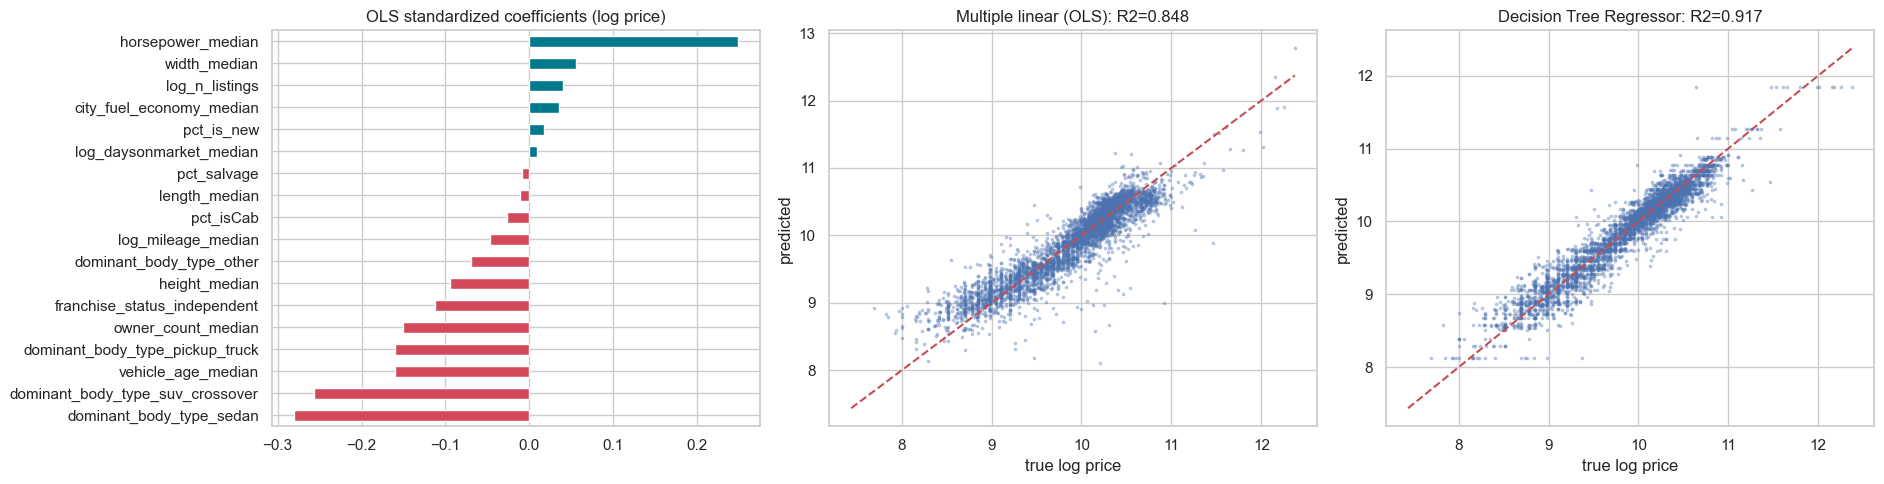

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))

coef.plot.barh(ax=ax[0], color=np.where(coef > 0, '#00798c', '#d1495b'))

ax[0].set_title('OLS standardized coefficients (log price)')

for a, name in zip(ax[1:], ['Multiple linear (OLS)', 'Decision Tree Regressor']):
    p = reg_models[name][1]
    a.scatter(yr_te, p, s=3, alpha=0.3)
    a.plot([yr.min(), yr.max()], [yr.min(), yr.max()], 'r--')
    a.set_title(f'{name}: R2={r2_score(yr_te, p):.3f}')
    a.set_xlabel('true log price')
    a.set_ylabel('predicted')

plt.tight_layout()

plt.show()


In [ ]:
p_best = reg_models['Decision Tree Regressor'][1]

print('Decision tree RMSE in dollars (back-transformed):', round(np.sqrt(mean_squared_error(np.expm1(yr_te), np.expm1(p_best)))))


Decision tree RMSE in dollars (back-transformed): 5025


In [ ]:
print(coef.round(3).to_string())


dominant_body_type_sedan           -0.280
dominant_body_type_suv_crossover   -0.257
vehicle_age_median                 -0.160
dominant_body_type_pickup_truck    -0.160
owner_count_median                 -0.151
franchise_status_independent       -0.113
height_median                      -0.095
dominant_body_type_other           -0.070
log_mileage_median                 -0.047
pct_isCab                          -0.026
length_median                      -0.011
pct_salvage                        -0.008
log_daysonmarket_median             0.009
pct_is_new                          0.018
city_fuel_economy_median            0.036
log_n_listings                      0.040
width_median                        0.055
horsepower_median                   0.249


**Interpreting the OLS coefficients (standardized; the reference body type is coupe):** price rises mainly with **horsepower** (+0.25) and falls with **vehicle age** (−0.16) and **owner count** (−0.15). Independent sellers have lower prices than franchise dealers at equal characteristics (−0.11). Mileage and % new get small coefficients once age is in the model, because they carry the same information (the age block of 1.5): with collinear predictors, the individual coefficients cannot be read as separate effects, even if the predictions stay good. Among body types, pickups (−0.16) are pricier than SUVs (−0.26) and sedans (−0.28) relative to coupes. Back-transformed to dollars, the tree's RMSE is about **$5,000** on a median price of ~$22k. **Best regressor: Decision Tree**. The linear model remains useful for its interpretable coefficients.

### Checkpoint: what did supervised learning teach us?

We trained models against known seller labels, separated training from testing, selected settings by cross-validation, and compared models using metrics appropriate for imbalanced labels. We also distinguished classification of a rating from regression of a numeric price.

**Test yourself:** What information may a scaler learn from training data? Why is macro-F1 more useful than accuracy alone here? What is the difference between a class probability and a predicted class? In which units is a regression error measured after predicting log price?

### Pattern mining: a different kind of question

Clustering asks “Which sellers resemble one another?” Classification asks “Can we predict a seller's rating?” Pattern mining asks “Which combinations of seller characteristics repeatedly appear together?”

For a rule `A → B`, we will use three measures:

- `support(A ∪ B)` is the share of transactions containing both sides.
- `confidence(A → B)` is the share of A-transactions that also contain B.
- `lift(A → B) = confidence(A → B) / support(B)` compares the rule to the overall frequency of B.

A rule with lift above 1 indicates positive association, not causation. A rare pattern can have spectacular lift and still be unreliable if it only describes a handful of sellers.

# 4. Pattern Mining
## 4.1 Transaction encoding
Each seller becomes a **transaction of 14 items**. Numeric variables are discretized into **tertiles** (low / mid / high, equal frequency, so that each item has ~33% support and no item dominates just because of skew). `pct_is_new` and `pct_isCab` use semantic cut-points (none / some / mostly new; low / mid / high cab). Body type, franchise status, profile, color and **rating** are added as items. This gives 48 distinct items.

#### Working through this investigation: Turn sellers into item transactions

In **pattern mining**, a transaction is a set of items that occur together. Here each seller becomes a transaction describing attributes such as price level, mileage level, rating, and franchise type. We divide selected numeric variables into tertiles, which make approximately three equally populated ranked groups.

We convert the resulting categorical statements into a Boolean item matrix: `True` means a seller has the item. This representation lets frequent-itemset algorithms ask which combinations appear often. The choice of bin boundaries affects the patterns we find, so each item should be interpreted as a deliberately discretized seller characteristic.

In [ ]:
# We convert seller profiles into item-based transactions.

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules


In [ ]:
pm_num = {'price_median': 'price', 'mileage_median': 'mileage', 'n_listings': 'listings', 'daysonmarket_median': 'dom', 'savings_amount_median': 'savings', 'horsepower_median': 'hp', 'activity_ratio': 'activity'}

T = pd.DataFrame(index=df.index)


In [ ]:
for c, short in pm_num.items():
    T[short] = pd.qcut(df[c].rank(method='first'), 3, labels=[f'{short}=low', f'{short}=mid', f'{short}=high'])

T['new'] = pd.cut(df.pct_is_new, [-1, 0, 0.5, 1.01], labels=['new=none', 'new=some', 'new=mostly'])

T['cab'] = pd.cut(df.pct_isCab, [-1, 0.05, 0.2, 1.01], labels=['cab=low', 'cab=mid', 'cab=high'])


In [ ]:
for c, short in [('dominant_body_type', 'body'), ('franchise_status', 'franchise'), ('new_used_profile', 'profile'), ('dominant_listing_color', 'color')]:
    T[short] = short + '=' + df[c].astype(str)

T['rating'] = 'rating=' + df.seller_rating_class

onehot = pd.get_dummies(T.astype(str), prefix='', prefix_sep='').astype(bool)

print('transactions:', onehot.shape, '| items per transaction:', T.shape[1])


In [ ]:
onehot.mean().sort_values(ascending=False).head(10).round(3)


## 4.2 Frequent itemsets for different min_sup
FP-Growth is used (same result as Apriori, much faster).

#### Working through this investigation: Study the effect of minimum support

An **itemset** is a collection of items. Its **support** is the fraction of seller transactions containing every item in the collection. If support is 0.10, then about 10% of sellers contain that combination.

We apply FP-Growth repeatedly with different minimum-support thresholds. Lowering the threshold allows less common combinations to qualify, often causing the number of retained itemsets to grow rapidly. We count itemsets by length so that we can see whether the lower thresholds mainly reveal richer combinations or merely many trivial frequent items.

In [ ]:
sups = [0.02, 0.03, 0.05, 0.08, 0.1, 0.15, 0.2, 0.3]

cnt = []


In [ ]:
for s in sups:
    fi = fpgrowth(onehot, min_support=s, use_colnames=True)
    fi['len'] = fi.itemsets.apply(len)
    cnt.append(dict(min_sup=s, total=len(fi), **{f'len={k}': int((fi.len == k).sum()) for k in range(1, 6)}))

cnt = pd.DataFrame(cnt).fillna(0)

display(cnt)


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(cnt.min_sup, cnt.total, 'o-')

ax[0].set_yscale('log')

ax[0].set_xlabel('min_sup')

ax[0].set_ylabel('# frequent itemsets (log)')

ax[0].set_title('Itemsets vs min_sup')

cnt.set_index('min_sup')[[c for c in cnt.columns if c.startswith('len=')]].plot.bar(stacked=True, ax=ax[1], logy=False)

ax[1].set_title('By itemset length')

plt.tight_layout()

plt.show()


The number of frequent itemsets **grows exponentially** as min_sup decreases (log scale): 81 at 0.30, 2,389 at 0.10, 12,649 at 0.05, 73,560 at 0.02. At low support, long itemsets (length 4-5) dominate. This is the combinatorial explosion caused by strongly dependent items (e.g., `new=none`, `profile=used_only` and `franchise=independent` almost always appear together, so every combination of them with other items is frequent). We choose **min_sup = 0.05** (≈ 690 sellers) as a compromise between significance and coverage.

#### Working through this investigation: Inspect frequent seller patterns

We select a support threshold and inspect frequent itemsets containing at least three items. We also separately inspect itemsets containing the rating label so that the results connect to the project's predictive questions.

A common pattern does not necessarily predict a rating well: it may be common simply because its individual items are common. For predictive interpretation we will need **association rules** and measures such as confidence and lift. The itemsets here are a descriptive foundation for that next step.

In [ ]:
MIN_SUP = 0.05

fi = fpgrowth(onehot, min_support=MIN_SUP, use_colnames=True)

fi['len'] = fi.itemsets.apply(len)

fi['itemset'] = fi.itemsets.apply(lambda s: ', '.join(sorted(s)))


In [ ]:
print('frequent itemsets at min_sup=0.05:', len(fi), '| maximal length:', fi.len.max())


In [ ]:
display(fi[fi.len >= 3].sort_values('support', ascending=False).head(12)[['itemset', 'support']])


In [ ]:
display(fi[fi.itemset.str.contains('rating=') & (fi.len >= 2)].sort_values('support', ascending=False).head(10)[['itemset', 'support']])


**Most frequent patterns (qualitative):** {independent, no new cars, used_only} covers 49% of sellers, and {SUV, franchise, mixed profile} covers 37%. Used-only independents are also typically {high mileage, low price}. The patterns reproduce the two business models found by clustering. Among patterns containing the target, *medium* co-occurs with almost everything simply because it is the majority class. This is why support alone cannot identify interesting rules, and we need lift.

## 4.3 Association rules for different min_conf

#### Working through this investigation: Measure association-rule strength

A rule has the form `A → B`: when items in A occur, we ask how often B also occurs. **Confidence** is `support(A ∪ B) / support(A)`, or the fraction of A-transactions that also contain B. **Lift** is `confidence(A → B) / support(B)`; lift above 1 indicates that B is more common with A than in the overall transactions.

We test several minimum-confidence thresholds and inspect the distribution of confidence and lift. A rule with confidence 0.95 can still have lift close to 1 if B is nearly universal. Therefore, confidence alone should never be treated as proof of a useful or surprising relationship.

In [ ]:
confs = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

nr = [len(association_rules(fi[['support', 'itemsets']], metric='confidence', min_threshold=c)) for c in confs]

rules = association_rules(fi[['support', 'itemsets']], metric='confidence', min_threshold=0.6)

rules['ante'] = rules.antecedents.apply(lambda s: ', '.join(sorted(s)))


In [ ]:
rules['cons'] = rules.consequents.apply(lambda s: ', '.join(sorted(s)))


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

ax[0].plot(confs, nr, 'o-')

ax[0].set_xlabel('min_conf')

ax[0].set_ylabel('# rules')

ax[0].set_title(f'Rules vs min_conf (min_sup={MIN_SUP})')

ax[1].hist(rules.confidence, bins=30, color='#00798c')

ax[1].set_title('Confidence of rules (min_conf=0.6)')

ax[2].hist(rules.lift, bins=30, color='#edae49')

ax[2].set_title('Lift of rules')

ax[2].axvline(1, color='k', ls='--')

plt.tight_layout()

plt.show()


In [ ]:
print(dict(zip(confs, nr)))


In [ ]:
display(rules.sort_values('lift', ascending=False).head(12)[['ante', 'cons', 'support', 'confidence', 'lift']].round(3))


The number of rules decreases smoothly with min_conf (198k at 0.4 → 33k at 0.9). The confidence histogram has a large peak near 1.0, made of **deterministic rules** that come from redundant items (e.g., `profile=used_only → new=none` has confidence 1 by construction). The lift histogram shows that most rules have lift between 1 and 2, with a tail up to ~7. The top-lift rules all describe the "mixed franchise dealer with some new cars" profile: these are true but *expected* rules. A good report should name these redundancies instead of presenting them as discoveries.

## 4.4 Rules that predict the rating (consequent = rating, lift > 1.2)
Mined with lower support (1.5%), because rating-specific patterns are rarer.

#### Working through this investigation: Find rules specifically about the seller rating

We lower the itemset-support threshold because patterns involving particular rating groups may be relatively rare. Then we retain rules with exactly one rating label in the **consequent** and no rating label in the antecedent.

This restriction avoids circular rules that already contain the answer on the left-hand side. We examine support, confidence, and lift for high, low, and medium ratings. The resulting rules are **observed associations**, not causal claims or guaranteed individual predictions. We should always read the underlying counts along with the percentages.

In [ ]:
fi_low = fpgrowth(onehot, min_support=0.015, use_colnames=True, max_len=4)

r_all = association_rules(fi_low, metric='confidence', min_threshold=0.3)

r_t = r_all[r_all.consequents.apply(lambda s: len(s) == 1 and next(iter(s)).startswith('rating=')) & r_all.antecedents.apply(lambda s: not any((i.startswith('rating=') for i in s)))].copy()

r_t['ante'] = r_t.antecedents.apply(lambda s: ', '.join(sorted(s)))


In [ ]:
r_t['cons'] = r_t.consequents.apply(lambda s: next(iter(s)))

r_t = r_t[r_t.lift > 1.2]


In [ ]:
for cls in ['rating=high', 'rating=low', 'rating=medium']:
    print(cls)
    display(r_t[r_t.cons == cls].sort_values(['confidence', 'support'], ascending=False).head(6)[['ante', 'support', 'confidence', 'lift']].round(3))


**Most useful rules (they agree with the decision tree):**
- `listings=low ∧ mileage=mid ∧ body=SUV → rating=high` (conf 0.53, **lift 1.98**): a seller with one of these profiles is twice as likely as average to be highly rated. Almost all *high* rules contain `listings=low`.
- `listings=high ∧ price=mid ∧ hp=low → rating=low` (conf 0.35, lift 1.88): large dealers with mainstream, low-horsepower inventory.
- `listings=high ∧ price=high ∧ new=some → rating=medium` (conf 0.75, lift 1.37).

Confidence for *low* never exceeds ~0.36, which shows again that low-rated sellers have no distinctive profile.

### Turning patterns into a model

Association rules are usually **descriptive**, but we can also define a simple predictor: search the rules in a fixed order, take the first applicable rule, and use a fallback rating if none applies. That gives us a testable algorithm rather than an informal collection of observations.

The training/test separation matters here just as it did for decision trees and KNN. A rule mined using the held-out test set would already have seen the answers we claim to predict.

## 4.5 Exploiting the rules: a rule-based classifier for the rating
Rules are mined on the **training split only**. Rules for *high*/*low* are ranked by lift, the first matching rule decides, and otherwise we predict *medium*. The minimum-lift threshold is tuned on training data, then the classifier is tested once on the test split.

#### Working through this investigation: Turn selected association rules into predictions

This final experiment connects exploratory pattern mining to supervised evaluation. We mine rating rules from **training transactions only** and rank the high/low rules by lift. A seller is assigned the first matching rule, with `medium` as the default if no selected rule matches.

We try several lift thresholds using **training performance** and use the selected threshold once on the held-out test sellers. This avoids choosing the threshold directly from test performance. The result is compared with the earlier classifiers using the same macro-F1 concept. Rule order and the default label are part of the model definition and must be documented to reproduce its predictions.

In [ ]:
# We mine rules on training data and reserve the test data for evaluation.

tr_i, te_i = (X_tr.index, X_te.index)

fi_tr = fpgrowth(onehot.loc[tr_i], min_support=0.015, use_colnames=True, max_len=4)

rr = association_rules(fi_tr, metric='confidence', min_threshold=0.25)

rr = rr[rr.consequents.apply(lambda s: len(s) == 1 and next(iter(s)).startswith('rating=')) & rr.antecedents.apply(lambda s: not any((i.startswith('rating=') for i in s)))].copy()


In [ ]:
rr['cls'] = rr.consequents.apply(lambda s: next(iter(s)).split('=')[1])

rr = rr[rr.cls != 'medium'].sort_values(['lift', 'confidence'], ascending=False)

to_sets = lambda idx: onehot.loc[idx].apply(lambda r: frozenset(r.index[r.values]), axis=1)

tr_items, te_items = (to_sets(tr_i), to_sets(te_i))


In [ ]:
def rule_predict(items, rules):
    out = []
    for it in items:
        lab = 'medium'
        for a, c in rules:
            if a <= it:
                lab = c
                break
        out.append(lab)
    return np.array(out)


In [ ]:
rows = []

for thr in [1.5, 1.6, 1.7, 1.8, 1.9, 2.0]:
    rl = [(frozenset(a), c) for a, c in zip(rr.antecedents[rr.lift >= thr], rr.cls[rr.lift >= thr])]
    p = rule_predict(tr_items, rl)
    rows.append(dict(min_lift=thr, n_rules=len(rl), train_acc=accuracy_score(y_tr, p), train_macroF1=f1_score(y_tr, p, average='macro')))

thr_tab = pd.DataFrame(rows).round(3)

display(thr_tab)


In [ ]:
best_thr = thr_tab.loc[thr_tab.train_macroF1.idxmax(), 'min_lift']

rl = [(frozenset(a), c) for a, c in zip(rr.antecedents[rr.lift >= best_thr], rr.cls[rr.lift >= best_thr])]

pm_pred = rule_predict(te_items, rl)

print(f"chosen min_lift={best_thr} ({len(rl)} rules) -> TEST accuracy={accuracy_score(y_te, pm_pred):.3f}, macro-F1={f1_score(y_te, pm_pred, average='macro'):.3f}")


In [ ]:
print(classification_report(y_te, pm_pred, digits=3))


With min_lift = 1.7 (86 rules), the rule classifier reaches **test macro-F1 = 0.416** and accuracy 0.457. This is close to Gaussian NB and the Decision Tree (0.42-0.44) and far above the baseline (0.236). A small set of human-readable rules therefore captures most of the predictive signal. Very strict thresholds (lift ≥ 1.9) leave only a handful of rules and collapse to "always medium", while loose thresholds over-predict the minority classes. This trade-off is the same as choosing min_conf.

# 5. Conclusions
1. The dataset describes **two business models**: independent used-car lots and franchise dealers that sell new cars (and premium vs mainstream within these). This structure appears in every module: correlations, K-Means/Ward clusters, DBSCAN's dense regions, frequent itemsets, and the franchise classifier.
2. **Seller size is the main driver of the rating**: small sellers are rated high, large mainstream dealers low. The tree, the association rules and the cluster profiles all say the same.
3. Predicting the rating is intrinsically hard: the best macro-F1 is ~0.44, against 0.24 for the baseline. The models do not overfit, so the remaining error must come from factors that are not in the data.
4. Price, on the other hand, is well explained by the inventory (R² = 0.92 with a regression tree), even without the advertised savings.

**Limitations:** attributes are medians, which hides within-seller variability. Hierarchical clustering was run on a sample. The chosen discretization (tertiles) affects which patterns are found; it is computed on the whole dataset, but it uses no class information. The lift threshold of the rule classifier is tuned on the same training data used to mine the rules, so its training scores are optimistic (the test score is not).

## Final study recap and notebook integrity notes

The completed analysis covers **data understanding, cleaning, transformations, correlation, clustering, classification, regression, and association rules**. Each answers a different question. The central professional habit is to state the question first, choose an appropriate representation and method, check assumptions, then interpret results in the units and population actually studied.

### What we must not overclaim

- The retained outputs are **saved from the source notebook**, not independently recalculated here. To verify them, run the notebook with the original CSV and compatible dependencies.
- The source's supervised preprocessing still contains a methodological detail to revisit: some log-transformed features are carried over from earlier full-data preparation, even though a subset of raw numeric columns is re-imputed using training-only statistics. A stricter future revision would recalculate any imputed derived features inside the training-aware preprocessing procedure and rerun the results.
- The source uses several global variable names for different experiments and then restores them. Running all cells sequentially is essential. We have retained that behavior so that the original experiment remains recognizable.
- Association rules, feature importance, and group differences show **patterns in this dataset**. They do not prove causes.
- Saved results can vary under different package versions, especially for randomized algorithms or alternative implementations.

### What to learn next

After we can explain every part of this project, we can deepen our skills in **cross-validation pipelines, leakage-safe feature transformations, calibration, uncertainty intervals, model monitoring, SQL, deployment, and collaboration through version control**. Those topics go beyond the notebook's original project requirements and are not presented as results from this dataset.

**Before submitting or publishing:** Run all cells using a fresh kernel, verify the numeric claims against the new outputs, review every visualization, and keep the dataset's sharing permissions in mind.

## Quick glossary for revision

| Term | Meaning in this notebook |
|---|---|
| Observation | One seller or dealer, not one vehicle |
| Feature | A variable describing a seller |
| Target | The outcome we predict in supervised learning |
| Median | Middle value; relatively robust to extremes |
| IQR | Third quartile minus first quartile |
| Skewness | Asymmetry of a distribution |
| Imputation | A declared rule for filling missing data |
| Scaling | Changing feature units so magnitudes are comparable |
| Euclidean distance | Straight-line distance between feature vectors |
| Centroid | Average position of points within a K-Means cluster |
| Silhouette | Relative closeness to the assigned cluster versus alternatives |
| ARI | Chance-adjusted agreement between two partitions |
| Test set | Data reserved for evaluation after fitting and tuning |
| Precision | Correct predicted positives divided by all predicted positives |
| Recall | Correct predicted positives divided by all actual positives |
| Macro-F1 | Mean of the separate class F1 scores |
| R² | Regression fit relative to predicting the target mean |
| Support | Fraction of transactions containing an itemset |
| Confidence | Frequency of a rule's consequent among transactions with its antecedent |
| Lift | Rule confidence divided by overall frequency of its consequent |

**Final habit:** For every chart or statistic, be able to answer three questions in plain language: What did we calculate? What does its numerical value mean? What conclusion is justified, and what conclusion would go beyond the evidence?